In [1]:
%env OPENBLAS_NUM_THREADS=1
%env MKL_NUM_THREADS=1
%env NUMEXPR_NUM_THREADS=1

import os

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"
os.environ["BLIS_NUM_THREADS"] = "1"
os.environ["OMP_DYNAMIC"] = "FALSE"


env: OPENBLAS_NUM_THREADS=1
env: MKL_NUM_THREADS=1
env: NUMEXPR_NUM_THREADS=1


In [2]:
from utils import load_counties, load_cbsa, set_plot_style, make_stars

import pandas as pd
import numpy as np
import geopandas as gpd

import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan, het_white

import patsy

from statsmodels.iolib.summary2 import summary_col

import matplotlib.pyplot as plt
import seaborn as sns

import pickle

import scipy

import random
np.random.seed(42)
random.seed(42)

In [3]:
set_plot_style()

In [4]:
nri_county=df = pd.read_parquet("../data_loaded/nri_counties.parquet")

In [5]:
counties = load_counties()

## Modelling CBSAs' PageRanks

### CBSA Aggregated: One Big Beautiful Network

In [6]:
cbsa = load_cbsa()


In [7]:
business = pd.read_csv("../data_loaded/cbp22co.zip", sep=',')

business["STCOFIPS"] = (
            business["fipstate"].astype(str).str.zfill(2)
            + business["fipscty"].astype(str).str.zfill(3))

business=business[business['naics'].isin(['51----','52----','53----','54----','55----','56----'])]

business=business.groupby('STCOFIPS').agg({'emp':'sum', 'est':'sum'}).reset_index()

In [8]:
hits_irs=pd.read_parquet("../data_generated/network_metrics/cbsa2_hits_irs_1122.parquet")
hits_exp=pd.read_parquet("../data_generated/network_metrics/cbsa2_hits_exp_1122.parquet")

hits_merged=hits_irs.merge(hits_exp, left_on=['CBSA'], right_on=['CBSA'], how='inner', suffixes=('_irs', '_exp'))

In [9]:
hits_merged['pagerank_diff']=hits_merged['pagerank_exp']-hits_merged['pagerank_irs']

xwalk = cbsa[['STCOFIPS', 'CBSA Code', 'CBSA Title']].drop_duplicates()

counties = counties.merge(xwalk, on='STCOFIPS', how='left')
nri_county = nri_county.merge(xwalk, on='STCOFIPS', how='left')

counties_cbsa = (
    counties
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code', 'CBSA Title'], as_index=False)
    .agg(
        ALAND=('ALAND', 'sum'),
        AWATER=('AWATER', 'sum')
    )
)
counties_cbsa['water_perc'] = counties_cbsa['AWATER'] / (counties_cbsa['ALAND'] + counties_cbsa['AWATER']) * 100


def wmean(x, w):
    x = pd.to_numeric(x, errors='coerce')
    w = pd.to_numeric(w, errors='coerce')
    m = x.notna() & w.notna()
    if not m.any():
        return np.nan
    return np.average(x[m], weights=w[m])

hazards = [
    'RISK_SCORE', 'AVLN_RISKS', 'CFLD_RISKS', 'CWAV_RISKS', 'DRGT_RISKS',
    'ERQK_RISKS', 'HAIL_RISKS', 'HWAV_RISKS', 'HRCN_RISKS', 'ISTM_RISKS',
    'LNDS_RISKS', 'LTNG_RISKS', 'RFLD_RISKS', 'SWND_RISKS', 'TRND_RISKS',
    'TSUN_RISKS', 'VLCN_RISKS', 'WFIR_RISKS', 'WNTW_RISKS'
]

nri_county[hazards] = (
    nri_county[hazards]
    .replace(-9999, np.nan)
    .apply(pd.to_numeric, errors='coerce')
)


nri_cbsa = (
    nri_county
    .dropna(subset=['CBSA Code'])
    .assign(POPULATION=pd.to_numeric(nri_county['POPULATION'], errors='coerce'))
    .groupby(['CBSA Code', 'CBSA Title'], as_index=False)
    .agg(
        POPULATION=('POPULATION', 'sum'),
        **{h: (h, 'mean') for h in hazards}
    )
)

cbsa_agg = (
    counties_cbsa
    .merge(nri_cbsa, on=['CBSA Code', 'CBSA Title'], how='outer')
)

cbsa_agg['pop_density'] = cbsa_agg['POPULATION'] / cbsa_agg['ALAND'] * 1_000_000


hits_merged = hits_merged.merge(
    cbsa_agg,
    left_on=['CBSA'],
    right_on=['CBSA Code'],
    how='left',
    suffixes=('', '_cbsa')
)


In [10]:
## Job postings

jobposts=pd.read_csv('../data_loaded/jobpostings_aggregated/job_postings_county_month.csv')
jobposts_naics=pd.read_csv('../data_loaded/jobpostings_aggregated/job_postings_county_month_naics.csv')

jobposts_naics['year'] = jobposts_naics['month_year'].str[:4].astype(int)
jobposts_naics = jobposts_naics[jobposts_naics['year'].isin([2016, 2017, 2018,2019])].reset_index(drop=True)

jobposts_naics['STCOFIPS']=jobposts_naics['STCOFIPS'].astype(str)
jobposts_naics = jobposts_naics.merge(xwalk, on='STCOFIPS', how='left')

total_posts = (
    jobposts_naics
    .groupby(["CBSA Code"])
    .n_postings
    .sum()
    .reset_index()
    .rename(columns={"n_postings": "total_postings"})
)

target_posts = (
    jobposts_naics[jobposts_naics["NAICS_2"].isin([51, 52, 53, 54, 55, 56])]
    .groupby(["CBSA Code"])
    .n_postings
    .sum()
    .reset_index()
    .rename(columns={"n_postings": "target_postings"})
)

jobposts_share = (
    total_posts
    .merge(target_posts, on=["CBSA Code"], how="left")
)

jobposts_share["target_postings"] = jobposts_share["target_postings"].fillna(0)
jobposts_share["share_target_pct"] = (
    100 * jobposts_share["target_postings"] / jobposts_share["total_postings"]
)

jobposts_share['CBSA Code']=jobposts_share['CBSA Code'].astype(str)
jobposts_share["CBSA Code"]=jobposts_share["CBSA Code"].astype(str).str.zfill(5)

hits_merged=hits_merged.merge(jobposts_share, left_on='CBSA', right_on='CBSA Code', how='left')
hits_merged['target_postings'] = hits_merged['target_postings'].fillna(0)
hits_merged['n_postings_100k'] = hits_merged['target_postings']/hits_merged['POPULATION']*100_000

In [11]:
business = business.merge(xwalk, on='STCOFIPS', how='left')
business=business.groupby('CBSA Code').agg({'emp':'sum', 'est':'sum'}).reset_index()

hits_merged=hits_merged.merge(business, left_on='CBSA', right_on='CBSA Code', how='left')

hits_merged['emp_100k'] = hits_merged['emp']/hits_merged['POPULATION']*100_000
hits_merged['est_100k'] = hits_merged['est']/hits_merged['POPULATION']*100_000

In [12]:
# MY URBAN
pop_w = nri_county[['STCOFIPS', 'POPULATION']].copy()
pop_w['POPULATION'] = pd.to_numeric(pop_w['POPULATION'], errors='coerce')

urban=pd.read_parquet('../data_loaded/data_final/urban_afford.parquet')
urban['STCOFIPS'] = urban['STCOFIPS'].astype(str)

urban_cbsa_in = (
    urban[['STCOFIPS','nat_amenity_score','urbanism','real_estate_taxes_med',
           'med_home_price2017','income_price_ratio2023','inequality_ratio']]
    .merge(pop_w, on='STCOFIPS', how='left')
    .merge(xwalk, on='STCOFIPS', how='left')
)

urbanism_dict = {
    "6 - Noncore": 1,
    "5 - Micropolitan": 2,
    "4 - Small metro": 3,
    "3 - Medium metro": 4,
    "2 - Large fringe metro": 5,
    "1 - Large central metro": 6
}

urban_cbsa_in["urbanism"] = urban_cbsa_in["urbanism"].map(urbanism_dict)


urban_cbsa = (
    urban_cbsa_in
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code', 'CBSA Title'], as_index=False)
    .apply(lambda g: pd.Series({
        'nat_amenity_score': wmean(g['nat_amenity_score'], g['POPULATION']),
        'real_estate_taxes_med': wmean(g['real_estate_taxes_med'], g['POPULATION']),
        'med_home_price2017': wmean(g['med_home_price2017'], g['POPULATION']),
        'income_price_ratio2023': wmean(g['income_price_ratio2023'], g['POPULATION']),
        'inequality_ratio': wmean(g['inequality_ratio'], g['POPULATION']),

        'urbanism_pwmean': wmean(g['urbanism'], g['POPULATION'])
    }))
    .reset_index(drop=True)
)

urban_r = urban_cbsa.set_index('CBSA Code').drop(columns=['CBSA Title'], errors='ignore')

hits_merged = hits_merged.join(urban_r, on='CBSA')

In [13]:
## MY HDI

education_calulated=pd.read_parquet('../data_loaded/data_final/education_combined.parquet')
health_calulated=pd.read_parquet('../data_loaded/data_final/health_combined.parquet')
income_calulated=pd.read_parquet('../data_loaded/data_final/median_income_combined.parquet')

health_calulated=health_calulated[health_calulated['year']==2020][['STCOFIPS', 'health_index', 'health_index_adj']]
income_calulated=income_calulated[income_calulated['year']==2020][['STCOFIPS', 'income_index', 'income_index_adj']]

## MY INCOME
income_combined=pd.read_parquet('../data_loaded/data_final/income_combined.parquet')
income_combined=income_combined[income_combined['year']==2019].reset_index(drop=True)

income_combined = income_combined.pivot_table(
    index=["STCOFIPS"],    
    columns="Description",  
    values="value",        
    aggfunc="first"
).reset_index()

income_combined.columns.name = None

income_combined['gdp_pc']=income_combined['real_gdp_chained_2017']/income_combined['population']
income_combined['dividends_pc']=income_combined['dividends']/income_combined['population']

income_combined=income_combined[['STCOFIPS', 'personal_income_pc', 'poverty_rate_all', 'gdp_pc', 'dividends_pc', 'dividends']]

In [14]:
pop_w = nri_county[['STCOFIPS', 'POPULATION']].copy()
pop_w['POPULATION'] = pd.to_numeric(pop_w['POPULATION'], errors='coerce')

education_cbsa = (
    education_calulated
    .merge(pop_w, on='STCOFIPS', how='left')
    .merge(xwalk, on='STCOFIPS', how='left')
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code'], as_index=False)
    .apply(lambda g: pd.Series({
        'education_index': wmean(g['education_index'], g['POPULATION'])
    }))
    .reset_index(drop=True)
)

health_cbsa = (
    health_calulated
    .merge(pop_w, on='STCOFIPS', how='left')
    .merge(xwalk, on='STCOFIPS', how='left')
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code'], as_index=False)
    .apply(lambda g: pd.Series({
        'health_index_adj': wmean(g['health_index_adj'], g['POPULATION'])
    }))
    .reset_index(drop=True)
)

income_cbsa = (
    income_calulated
    .merge(pop_w, on='STCOFIPS', how='left')
    .merge(xwalk, on='STCOFIPS', how='left')
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code'], as_index=False)
    .apply(lambda g: pd.Series({
        'income_index_adj': wmean(g['income_index_adj'], g['POPULATION'])
    }))
    .reset_index(drop=True)
)

combined_income_cbsa = (
    income_combined
    .merge(pop_w, on='STCOFIPS', how='left')
    .merge(xwalk, on='STCOFIPS', how='left')
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code'], as_index=False)
    .apply(lambda g: pd.Series({
        'personal_income_pc': wmean(g['personal_income_pc'], g['POPULATION']),
        'poverty_rate_all': wmean(g['poverty_rate_all'], g['POPULATION']),
        'gdp_pc': wmean(g['gdp_pc'], g['POPULATION']),
        'dividends_pc': wmean(g['dividends_pc'], g['POPULATION']),
        'dividends': pd.to_numeric(g['dividends'], errors='coerce').sum(skipna=True),
        'POPULATION_sum': g['POPULATION'].sum(skipna=True)
    }))
    .reset_index(drop=True)
)



In [15]:
hits_merged['CBSA'] = hits_merged['CBSA'].astype(str)

for df in [education_cbsa, health_cbsa, income_cbsa, combined_income_cbsa]:
    df['CBSA Code'] = df['CBSA Code'].astype(str)

education_r = education_cbsa.set_index('CBSA Code').drop(columns=['CBSA Title'], errors='ignore')
health_r    = health_cbsa.set_index('CBSA Code').drop(columns=['CBSA Title'], errors='ignore')
income_r    = income_cbsa.set_index('CBSA Code').drop(columns=['CBSA Title'], errors='ignore')
cincome_r   = combined_income_cbsa.set_index('CBSA Code').drop(columns=['CBSA Title'], errors='ignore')

hits_merged = (
    hits_merged
    .join(education_r, on='CBSA')
    .join(health_r, on='CBSA')
    .join(income_r, on='CBSA')
    .join(cincome_r, on='CBSA')
)


In [16]:
hits_merged.columns

Index(['CBSA', 'hub_irs', 'auth_irs', 'pagerank_irs', 'rank_hub_irs',
       'rank_auth_irs', 'rank_page_irs', 'hub_exp', 'auth_exp', 'pagerank_exp',
       'rank_hub_exp', 'rank_auth_exp', 'rank_page_exp', 'pagerank_diff',
       'CBSA Code_x', 'CBSA Title', 'ALAND', 'AWATER', 'water_perc',
       'POPULATION', 'RISK_SCORE', 'AVLN_RISKS', 'CFLD_RISKS', 'CWAV_RISKS',
       'DRGT_RISKS', 'ERQK_RISKS', 'HAIL_RISKS', 'HWAV_RISKS', 'HRCN_RISKS',
       'ISTM_RISKS', 'LNDS_RISKS', 'LTNG_RISKS', 'RFLD_RISKS', 'SWND_RISKS',
       'TRND_RISKS', 'TSUN_RISKS', 'VLCN_RISKS', 'WFIR_RISKS', 'WNTW_RISKS',
       'pop_density', 'CBSA Code_y', 'total_postings', 'target_postings',
       'share_target_pct', 'n_postings_100k', 'CBSA Code', 'emp', 'est',
       'emp_100k', 'est_100k', 'nat_amenity_score', 'real_estate_taxes_med',
       'med_home_price2017', 'income_price_ratio2023', 'inequality_ratio',
       'urbanism_pwmean', 'education_index', 'health_index_adj',
       'income_index_adj', 'persona

In [17]:
# log transforms (avoid −inf)
for col in ["pagerank_irs", "pagerank_exp"]:
    hits_merged[f"log_{col}"] = (hits_merged[col] + 1e-12).apply(np.log) # there are no zeroes

for col in ['POPULATION', 'target_postings', 'n_postings_100k', 'emp_100k', 'est_100k', 
            'personal_income_pc', 'gdp_pc', 'dividends_pc', 'pop_density',
            'real_estate_taxes_med', 'med_home_price2017']:
    hits_merged[f"log_{col}"] = (hits_merged[col]).apply(np.log1p)

hits_merged['pagerank_logdiff']=hits_merged['log_pagerank_exp']-hits_merged['log_pagerank_irs']

In [18]:
df = hits_merged.copy()
na_counts = df.isna().sum()
print(na_counts[na_counts > 0])

AVLN_RISKS                723
CFLD_RISKS                637
HRCN_RISKS                218
ISTM_RISKS                 65
LNDS_RISKS                  3
LTNG_RISKS                  7
TSUN_RISKS                768
VLCN_RISKS                767
CBSA Code_y                93
total_postings             93
share_target_pct           93
nat_amenity_score           7
med_home_price2017          8
income_price_ratio2023      8
personal_income_pc          5
gdp_pc                      5
dividends_pc                5
log_personal_income_pc      5
log_gdp_pc                  5
log_dividends_pc            5
log_med_home_price2017      8
dtype: int64


In [19]:
df = (
    df
    .dropna(subset=df.columns.difference(hazards))
    .reset_index(drop=True)
)


In [20]:
corr_pearson=df[["pagerank_logdiff", "RISK_SCORE", "POPULATION", 'emp_100k', 'est_100k',
                 "target_postings", "n_postings_100k", 
                 'personal_income_pc', 'poverty_rate_all', 'gdp_pc', 'dividends', 'dividends_pc',
                 'education_index', 'income_index_adj', 'health_index_adj', 
                 'nat_amenity_score','real_estate_taxes_med', 'med_home_price2017', 'income_price_ratio2023', 
                 'pop_density', 'water_perc', 'inequality_ratio']].corr(method='pearson').round(3)

In [21]:
corr_spearman=df[["pagerank_logdiff", "RISK_SCORE", "POPULATION", 'emp_100k', 'est_100k',
                 "target_postings", "n_postings_100k", 
                 'personal_income_pc', 'poverty_rate_all', 'gdp_pc', 'dividends', 'dividends_pc',
                 'education_index', 'income_index_adj', 'health_index_adj', 
                 'nat_amenity_score','real_estate_taxes_med', 'med_home_price2017', 'income_price_ratio2023', 
                 'pop_density', 'water_perc', 'inequality_ratio']].corr(method='spearman').round(3)

In [22]:
def format_bottom_colorbar(cbar, label):
    # identical tick behaviour
    cbar.ax.tick_params(
        axis="x",
        labelsize=9,
        length=4,
        width=0.6,
        pad=3
    )

    # identical label formatting
    cbar.set_label(label, fontsize=10, labelpad=4)

    # identical spine appearance
    for side in ["bottom", "top"]:
        cbar.ax.spines[side].set_visible(True)
        cbar.ax.spines[side].set_linewidth(0.6)

    # no left/right spines (keeps consistent)
    cbar.ax.spines["left"].set_visible(False)
    cbar.ax.spines["right"].set_visible(False)

In [23]:
df['log_pop_centered'] = df['log_POPULATION'] - df['log_POPULATION'].mean()
df['log_n_postings_centered'] = df['log_n_postings_100k'] - df['log_n_postings_100k'].mean()
df['log_gdp_centered'] = df['log_gdp_pc'] - df['log_gdp_pc'].mean()
df['education_centered'] = df['education_index'] - df['education_index'].mean()
df['income_centered'] = df['income_index_adj'] - df['income_index_adj'].mean()
df['health_centered'] = df['health_index_adj'] - df['health_index_adj'].mean()
df['risk_centered'] = df['RISK_SCORE'] - df['RISK_SCORE'].mean()
df['poverty_rate_centered'] = df['poverty_rate_all'] - df['poverty_rate_all'].mean()
df['nat_amenity_centered'] = df['nat_amenity_score'] - df['nat_amenity_score'].mean()
df['log_taxes_med_centered'] = df['log_real_estate_taxes_med'] - df['log_real_estate_taxes_med'].mean()
df['income_price_ratio2023_centered'] = df['income_price_ratio2023'] - df['income_price_ratio2023'].mean()
df['log_personal_income_centered'] = df['log_personal_income_pc'] - df['log_personal_income_pc'].mean()
df['log_est_100k_centered'] = df['log_est_100k'] - df['log_est_100k'].mean()
df['log_emp_100k_centered'] = df['log_emp_100k'] - df['log_emp_100k'].mean()
df['water_perc_centered'] = df['water_perc'] - df['water_perc'].mean()
df['log_pop_density_centered'] = df['log_pop_density'] - df['log_pop_density'].mean()
df['log_dividends_centered'] = df['log_dividends_pc'] - df['log_dividends_pc'].mean()
df['inequality_centered'] = df['inequality_ratio'] - df['inequality_ratio'].mean()


for hazard in hazards:
    df[f'{hazard}_centered'] = df[hazard] - df[hazard].mean()

In [24]:
# make_stars imported from utils


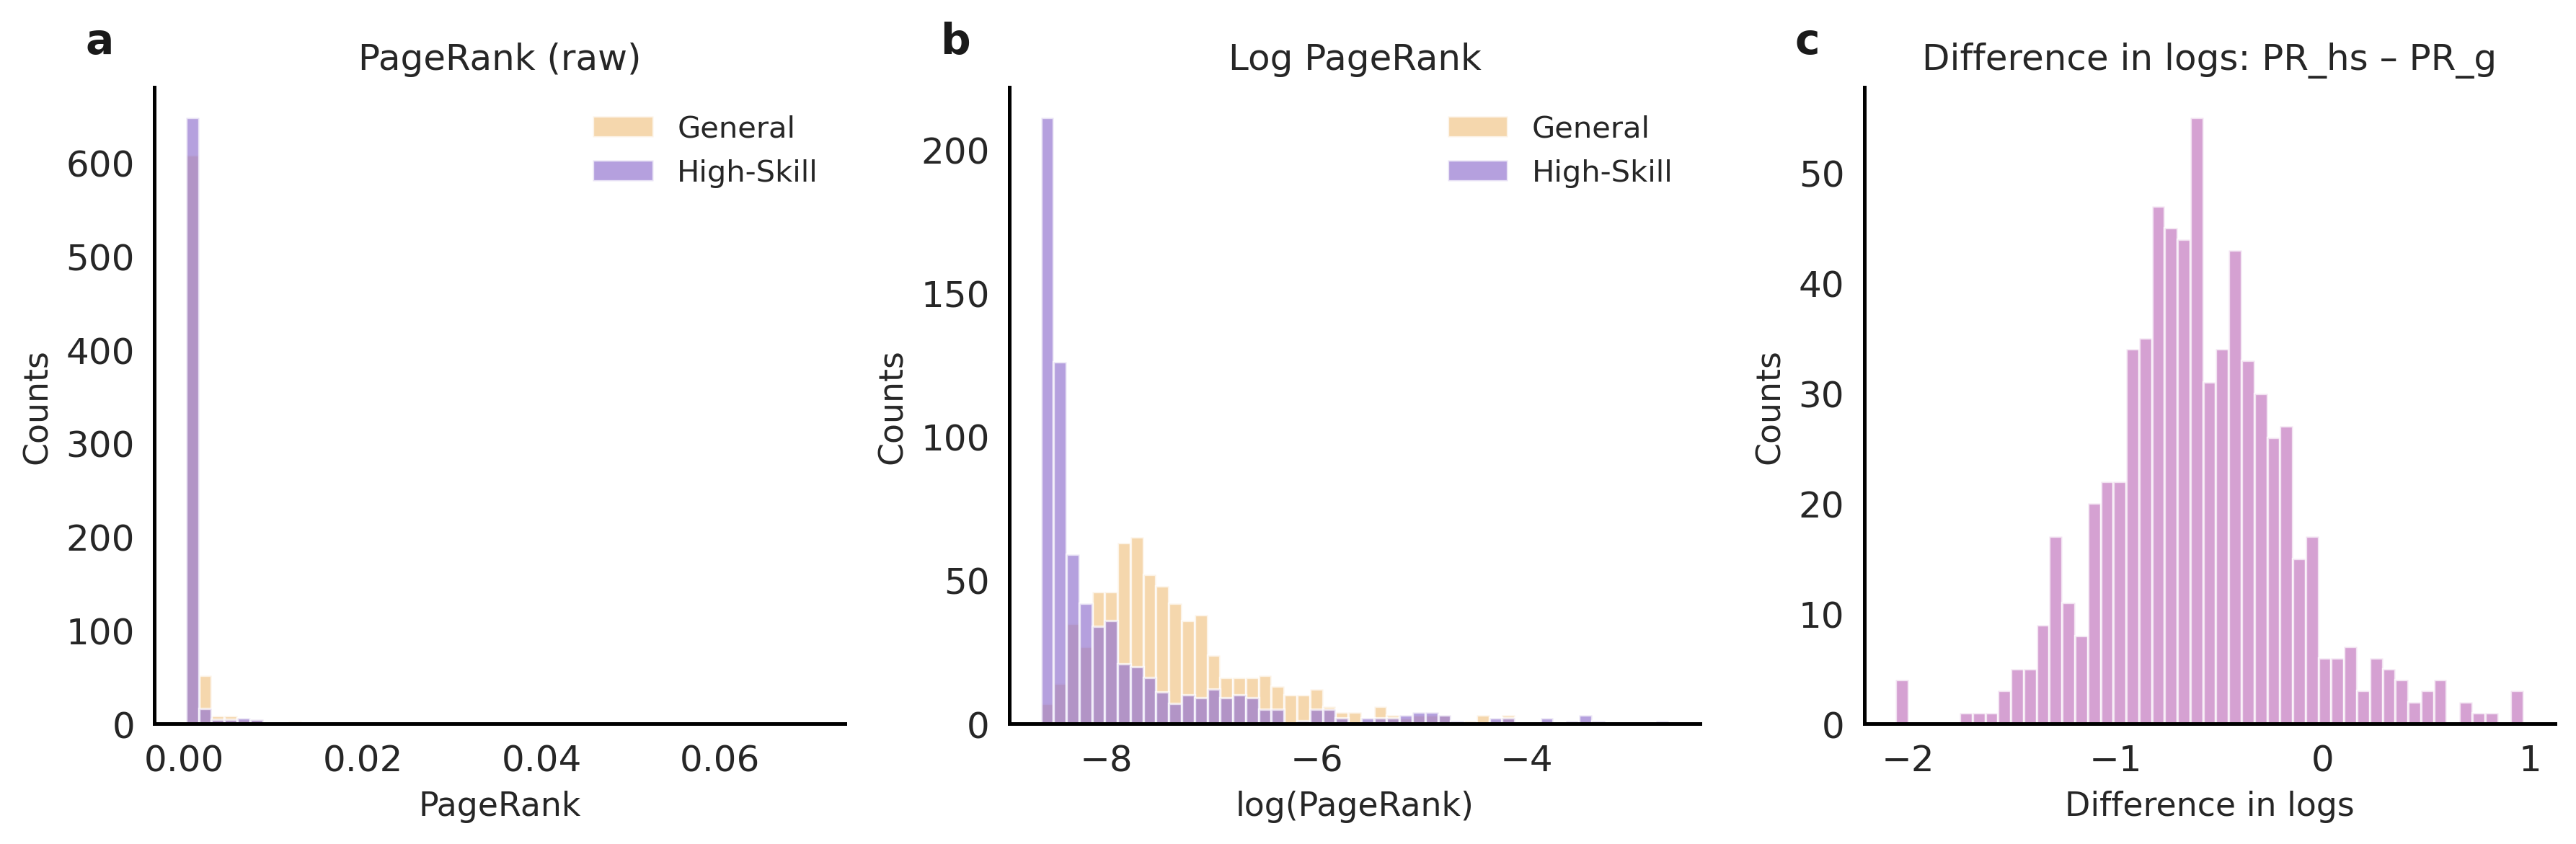

In [25]:
color_reg = '#f2c68b'
color_hs  = '#9678d1'

def clean_axis(ax):
    """Remove top/right spines and keep only x/y axes."""
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.2)
    ax.spines["bottom"].set_linewidth(1.2)
    ax.tick_params(axis='both', labelsize=12)

# ---------------------------
# 1) Log-spaced bins for raw PageRank
# ---------------------------
bins = np.linspace( 
    min(df["pagerank_irs"].min(), df["pagerank_exp"].min()), 
    max(df["pagerank_irs"].max(), df["pagerank_exp"].max()), 50 )

# Linear bins for logs
bins_log = np.linspace(
    min(df["log_pagerank_irs"].min(), df["log_pagerank_exp"].min()),
    max(df["log_pagerank_irs"].max(), df["log_pagerank_exp"].max()),
    50
)

# Linear bins for diff
bins_diff = np.linspace(df["pagerank_logdiff"].min(),
                        df["pagerank_logdiff"].max(), 50)

# ----------------------
#  Create figure
# ----------------------
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

# PLOT 1: Raw PageRank (log x-axis)
axes[0].hist(df["pagerank_irs"], bins=bins, alpha=0.7,
             label="General", color=color_reg)
axes[0].hist(df["pagerank_exp"], bins=bins, alpha=0.7,
             label="High-Skill", color=color_hs)

axes[0].set_title("PageRank (raw)")
axes[0].set_xlabel("PageRank")
axes[0].set_ylabel("Counts")
axes[0].legend(frameon=False)
clean_axis(axes[0])

# PLOT 2: Log(PageRank)
axes[1].hist(df["log_pagerank_irs"], bins=bins_log, alpha=0.7,
             label="General", color=color_reg)
axes[1].hist(df["log_pagerank_exp"], bins=bins_log, alpha=0.7,
             label="High-Skill", color=color_hs)

axes[1].set_title("Log PageRank")
axes[1].set_xlabel("log(PageRank)")
axes[1].set_ylabel("Counts")
axes[1].legend(frameon=False)
clean_axis(axes[1])

# PLOT 3: Log-difference
axes[2].hist(df["pagerank_logdiff"], bins=bins_diff,
             alpha=0.7, color="#C47AC0")

axes[2].set_title("Difference in logs: PR_hs – PR_g")
axes[2].set_xlabel("Difference in logs")
axes[2].set_ylabel("Counts")
clean_axis(axes[2])


plots_l = ['a', 'b', 'c']
for ia, ax in enumerate(fig.axes): 
    x,y = -0.1,1.04
    ax.text(x,y,  plots_l[ia],
        color = 'k',#'lightgreen',
        horizontalalignment='left',
        verticalalignment='bottom',
        weight = 'bold',
        transform=ax.transAxes,fontsize = 14)

plt.tight_layout()
plt.savefig('../fig/si/si_depvar_hist.pdf', bbox_inches='tight')
plt.show()


In [26]:
model_1= smf.ols(
    formula="pagerank_logdiff ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)",
    data=df
).fit(cov_type='HC3')

model_2= smf.ols(
    formula="pagerank_logdiff ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered",
    data=df
).fit(cov_type='HC3')


model_3= smf.ols(
    formula="pagerank_logdiff ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
            "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered",
    data=df
).fit(cov_type='HC3')

model_4= smf.ols(
    formula="pagerank_logdiff ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
            "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered"
            "+ education_centered + health_centered + inequality_centered",
    data=df
).fit(cov_type='HC3')

model_5= smf.ols(
    formula="pagerank_logdiff ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
            "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered"
            "+ education_centered + health_centered + inequality_centered"
            "+ nat_amenity_centered + water_perc_centered + risk_centered",
    data=df
).fit(cov_type='HC3')

model_1_1= smf.ols(
    formula="log_pagerank_exp ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)",
    data=df
).fit(cov_type='HC3')

model_2_1= smf.ols(
    formula="log_pagerank_exp ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered",
    data=df
).fit(cov_type='HC3')


model_3_1= smf.ols(
    formula="log_pagerank_exp ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
            "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered",
    data=df
).fit(cov_type='HC3')

model_4_1= smf.ols(
    formula="log_pagerank_exp ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
            "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered"
            "+ education_centered + health_centered + inequality_centered",
    data=df
).fit(cov_type='HC3')

model_5_1= smf.ols(
    formula="log_pagerank_exp ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
            "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered"
            "+ education_centered + health_centered + inequality_centered"
            "+ nat_amenity_centered + water_perc_centered + risk_centered",
    data=df
).fit(cov_type='HC3')

model_1_2= smf.ols(
    formula="log_pagerank_irs ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)",
    data=df
).fit(cov_type='HC3')

model_2_2= smf.ols(
    formula="log_pagerank_irs ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered",
    data=df
).fit(cov_type='HC3')


model_3_2= smf.ols(
    formula="log_pagerank_irs ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
            "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered",
    data=df
).fit(cov_type='HC3')

model_4_2= smf.ols(
    formula="log_pagerank_irs ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
            "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered"
            "+ education_centered + health_centered + inequality_centered",
    data=df
).fit(cov_type='HC3')

model_5_2= smf.ols(
    formula="log_pagerank_irs ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
            "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered"
            "+ education_centered + health_centered + inequality_centered"
            "+ nat_amenity_centered + water_perc_centered + risk_centered",
    data=df
).fit(cov_type='HC3')

In [27]:
summary = summary_col(
    [model_1, model_2, model_3, model_4, model_5, model_1_1, model_2_1, model_3_1, model_4_1, model_5_1, model_1_2, model_2_2, model_3_2, model_4_2, model_5_2],
    stars=False,
    model_names=[
        "Model 1", "Model 2", "Model 3", "Model 4", "Model 5", "Model 1", "Model 2", "Model 3", "Model 4", "Model 5", "Model 1", "Model 2", "Model 3", "Model 4", "Model 5"
    ],
    info_dict = {
        "N": lambda x: f"{int(x.nobs)}",
        r"$R^2$": lambda x: f"{x.rsquared:.3f}",
        r"Adj. $R^2$": lambda x: f"{x.rsquared_adj:.3f}",
        "BIC": lambda x: f"{x.bic:.2f}",
    }
)


In [28]:
df_results = summary.tables[0]

models = [model_1, model_2, model_3, model_4, model_5, model_1_1, model_2_1, model_3_1, model_4_1, model_5_1, model_1_2, model_2_2, model_3_2, model_4_2, model_5_2]

for col, model in zip(df_results.columns, models):
    for param in model.params.index:
        if param not in df_results.index:
            continue

        coef = model.params[param]
        pval = model.pvalues[param]
        stars = make_stars(pval)

        df_results.loc[param, col] = f"{coef:.3f}{stars}"


In [29]:
df_results

,Model 1 I,Model 2 I,Model 3 I,Model 4 I,Model 5 I,Model 1 II,Model 2 II,Model 3 II,Model 4 II,Model 5 II,Model 1 III,Model 2 III,Model 3 III,Model 4 III,Model 5 III
I(log_pop_centered ** 2),0.070***,0.062***,0.062***,0.063***,0.062***,0.107***,0.105***,0.108***,0.108***,0.109***,0.037***,0.043***,0.046***,0.045***,0.047***
,(0.0113),(0.0120),(0.0110),(0.0108),(0.0106),(0.0117),(0.0119),(0.0103),(0.0104),(0.0104),(0.0072),(0.0077),(0.0079),(0.0087),(0.0075)
Intercept,-0.733***,-0.726***,-0.728***,-0.727***,-0.727***,-8.146***,-8.144***,-8.149***,-8.147***,-8.147***,-7.413***,-7.418***,-7.421***,-7.420***,-7.420***
,(0.0201),(0.0201),(0.0188),(0.0185),(0.0184),(0.0201),(0.0202),(0.0180),(0.0165),(0.0164),(0.0143),(0.0138),(0.0137),(0.0134),(0.0131)
R-squared,0.2992,0.3577,0.4030,0.4106,0.4256,0.9107,0.9134,0.9241,0.9355,0.9368,0.8765,0.8846,0.8858,0.8935,0.9006
R-squared Adj.,0.2952,0.3512,0.3943,0.3994,0.4121,0.9102,0.9125,0.9230,0.9343,0.9353,0.8758,0.8835,0.8842,0.8915,0.8982
education_centered,,,,0.074*,0.074*,,,,0.202***,0.198***,,,,0.128***,0.123***
,,,,(0.0339),(0.0365),,,,(0.0319),(0.0335),,,,(0.0321),(0.0293)
health_centered,,,,0.015,0.016,,,,0.093***,0.081**,,,,0.078*,0.065*
,,,,(0.0390),(0.0379),,,,(0.0270),(0.0270),,,,(0.0311),(0.0292)


In [30]:
corr_pearson=df[["pagerank_logdiff", "log_pagerank_exp", "log_pagerank_irs",
                 "log_pop_centered",  "log_gdp_centered", 
                 "log_taxes_med_centered", "log_dividends_centered", "income_price_ratio2023_centered",
                 'log_est_100k_centered', 'log_emp_100k_centered', 'log_n_postings_centered', 
                 'education_centered','health_centered', 'inequality_centered', 
                 'nat_amenity_centered', 'water_perc_centered', 'risk_centered']].corr(method='pearson').round(3)

In [31]:
corr_spearman=df[["pagerank_logdiff", "log_pagerank_exp", "log_pagerank_irs",
                 "log_pop_centered",  "log_gdp_centered", 
                 "log_taxes_med_centered", "log_dividends_centered", "income_price_ratio2023_centered",
                 'log_est_100k_centered', 'log_emp_100k_centered', 'log_n_postings_centered', 
                 'education_centered','health_centered', 'inequality_centered', 
                 'nat_amenity_centered', 'water_perc_centered', 'risk_centered']].corr(method='spearman').round(3)

In [32]:
def format_bottom_colorbar(cbar, label):
    # identical tick behaviour
    cbar.ax.tick_params(
        axis="x",
        labelsize=9,
        length=4,
        width=0.6,
        pad=3
    )

    # identical label formatting
    cbar.set_label(label, fontsize=10, labelpad=4)

    # identical spine appearance
    for side in ["bottom", "top"]:
        cbar.ax.spines[side].set_visible(True)
        cbar.ax.spines[side].set_linewidth(0.6)

    # no left/right spines (keeps consistent)
    cbar.ax.spines["left"].set_visible(False)
    cbar.ax.spines["right"].set_visible(False)

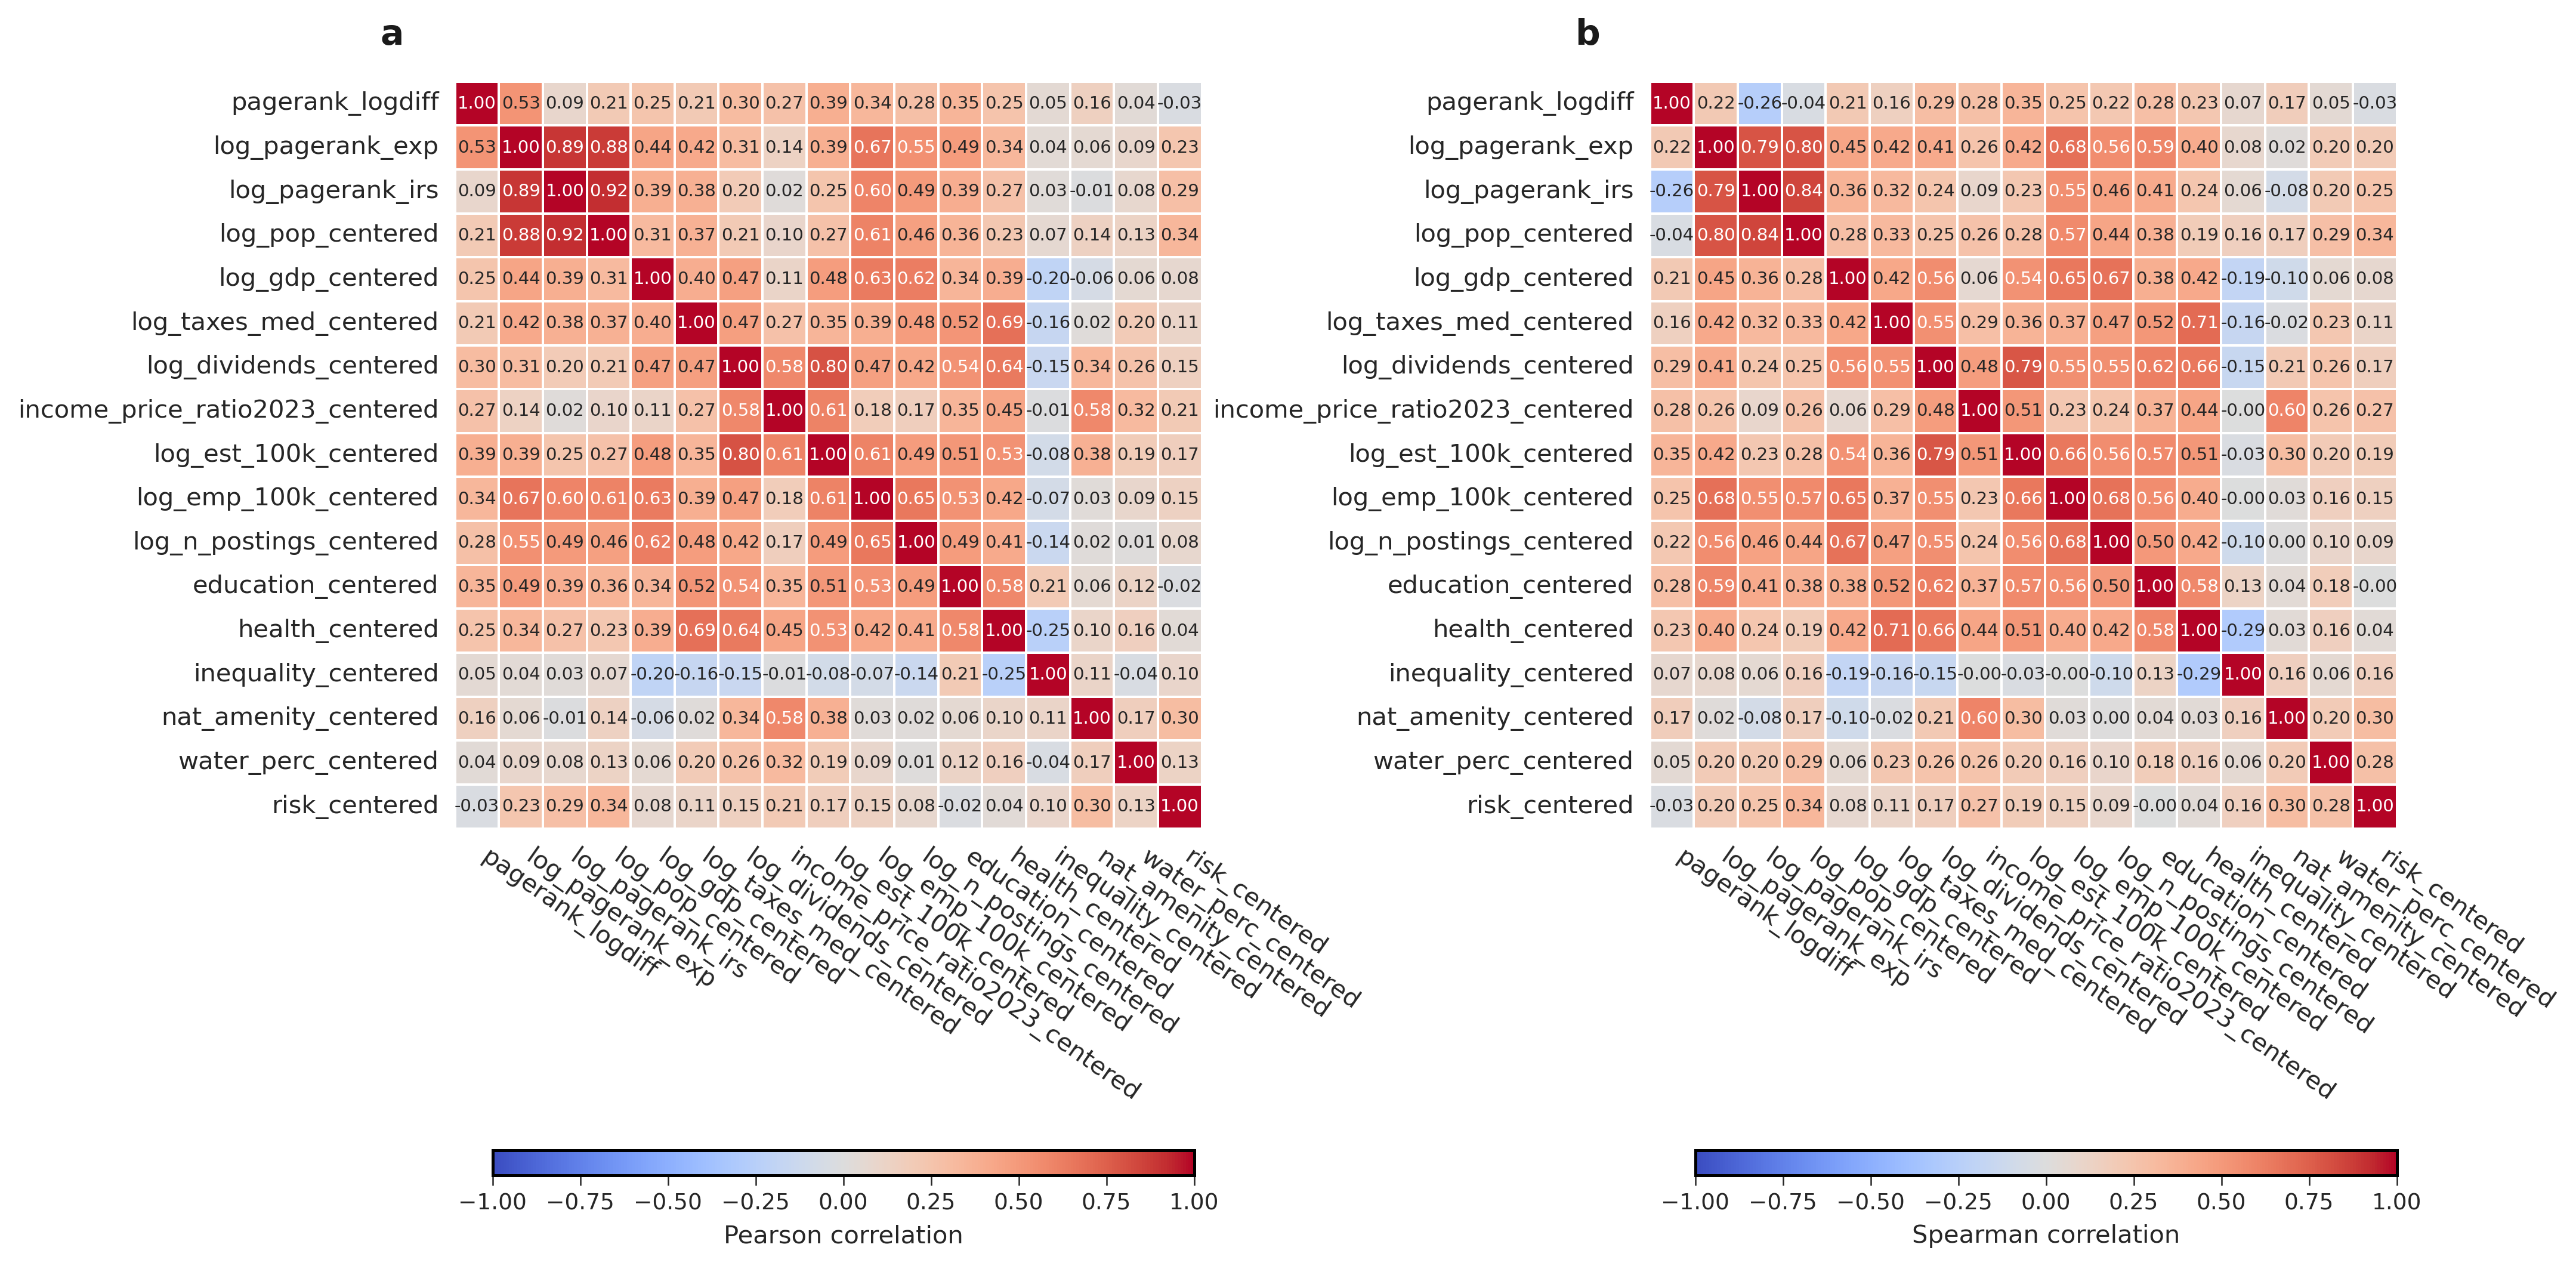

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
plt.subplots_adjust(wspace=0.6)   

# -------------------------
# 1. PEARSON HEATMAP (LEFT)
# -------------------------
ax1 = sns.heatmap(
    corr_pearson,
    ax=axes[0],
    cmap="coolwarm",
    vmin=-1, vmax=1,
    linewidths=0.5,
    square=True,
    cbar=False,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7}
)

ax1.set_xticklabels(ax1.get_xticklabels(), rotation=-35, ha="left")
ax1.set_yticklabels(ax1.get_yticklabels(), rotation=0)
ax1.set_xlabel("")
ax1.set_ylabel("")

# Colorbar under Pearson
fig1 = ax1.get_figure()
cax1 = fig1.add_axes([0.14, -0.08, 0.28, 0.02])

norm1 = plt.Normalize(vmin=-1, vmax=1)
sm1 = plt.cm.ScalarMappable(norm=norm1, cmap="coolwarm")

cbar1 = fig.colorbar(sm1, cax=cax1, orientation="horizontal")
format_bottom_colorbar(cbar1, "Pearson correlation")


# -------------------------
# 2. SPEARMAN HEATMAP (RIGHT)
# -------------------------
ax2 = sns.heatmap(
    corr_spearman,
    ax=axes[1],
    cmap="coolwarm",
    vmin=-1, vmax=1,
    linewidths=0.5,
    square=True,
    cbar=False,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7}
)

ax2.set_xticklabels(ax2.get_xticklabels(), rotation=-35, ha="left")
ax2.set_yticklabels(ax2.get_yticklabels(), rotation=0)
ax2.set_xlabel("")
ax2.set_ylabel("")

# Colorbar under Spearman
fig2 = ax2.get_figure()
cax2 = fig2.add_axes([0.62, -0.08, 0.28, 0.02])

norm2 = plt.Normalize(vmin=-1, vmax=1)
sm2 = plt.cm.ScalarMappable(norm=norm2, cmap="coolwarm")

cbar2 = fig.colorbar(sm2, cax=cax2, orientation="horizontal")
format_bottom_colorbar(cbar2, "Spearman correlation")

plots_l = ['a', 'b', '', '']
for ia, ax in enumerate(fig.axes): 
    x,y = -0.1,1.04
    ax.text(x,y,  plots_l[ia],
        color = 'k',#'lightgreen',
        horizontalalignment='left',
        verticalalignment='bottom',
        weight = 'bold',
        transform=ax.transAxes,fontsize = 14)

plt.savefig(
    '../fig/si/si_variables_corr.pdf',
    bbox_inches='tight',
    dpi=300
)

plt.show()


In [34]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

df["pop_gdp"] = df["log_pop_centered"] * df["log_gdp_centered"]
df["pop_risk"] = df["log_pop_centered"] * df["risk_centered"]
df["gdp_risk"] = df["log_gdp_centered"] * df["risk_centered"]
df["education_risk"] = df["education_centered"] * df["risk_centered"]

X = df[[
     "log_pop_centered",  "log_gdp_centered", 
     "log_taxes_med_centered", "log_dividends_centered", "income_price_ratio2023_centered",
     'log_emp_100k_centered', 'log_n_postings_centered', 
     'education_centered','health_centered', 'inequality_centered', 
     'nat_amenity_centered', 'water_perc_centered', 'risk_centered', 
]].assign(const=1)

vif_df = pd.DataFrame({
    "variable": X.columns,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
})

print(vif_df)


                           variable       VIF
0                  log_pop_centered  2.118017
1                  log_gdp_centered  2.220235
2            log_taxes_med_centered  2.333379
3            log_dividends_centered  2.808301
4   income_price_ratio2023_centered  2.363980
5             log_emp_100k_centered  3.043081
6           log_n_postings_centered  2.328520
7                education_centered  2.839426
8                   health_centered  3.072553
9               inequality_centered  1.543629
10             nat_amenity_centered  1.872552
11              water_perc_centered  1.188718
12                    risk_centered  1.328277
13                            const  1.000000


In [35]:
def clean_axis(ax):
    """Remove top/right spines and keep only x/y axes."""
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.2)
    ax.spines["bottom"].set_linewidth(1.2)
    ax.tick_params(axis='both', labelsize=12)

def delta_ci(C, V_sub, estimate, z=1.96):
    var = np.einsum("ij,jk,ik->i", C, V_sub, C)
    se = np.sqrt(var)
    return estimate - z * se, estimate + z * se


In [36]:
params = model_5.params
V = model_5.cov_params()

L_range = np.linspace(
    df["log_pop_centered"].min(),
    df["log_pop_centered"].max(),
    100
)

gdp_mean = df["log_gdp_centered"].mean()

######
me_pop_L = (
    params["log_pop_centered"]
    + params["log_pop_centered:log_gdp_centered"] * gdp_mean
    + 2 * params["I(log_pop_centered ** 2)"] * L_range
)

C1 = np.column_stack([
    np.ones(len(L_range)),
    np.full(len(L_range), gdp_mean),
    2 * L_range
])

V1 = V.loc[
    ["log_pop_centered",
     "log_pop_centered:log_gdp_centered",
     "I(log_pop_centered ** 2)"],
    ["log_pop_centered",
     "log_pop_centered:log_gdp_centered",
     "I(log_pop_centered ** 2)"]
].values

ci1_lo, ci1_hi = delta_ci(C1, V1, me_pop_L)


G_range = np.linspace(
    df["log_gdp_centered"].min(),
    df["log_gdp_centered"].max(),
    100
)

pop_mean = df["log_pop_centered"].mean()

######
me_pop_G = (
    params["log_pop_centered"]
    + params["log_pop_centered:log_gdp_centered"] * G_range
    + 2 * params["I(log_pop_centered ** 2)"] * pop_mean
)

C2 = np.column_stack([
    np.ones(len(G_range)),
    G_range,
    np.full(len(G_range), 2 * pop_mean)
])

V2 = V1  # same coefficients as above

ci2_lo, ci2_hi = delta_ci(C2, V1, me_pop_G)

######
me_gdp_L = (
    params["log_gdp_centered"]
    + params["log_pop_centered:log_gdp_centered"] * L_range
)

C3 = np.column_stack([
    np.ones(len(L_range)),
    L_range
])

V3 = V.loc[
    ["log_gdp_centered",
     "log_pop_centered:log_gdp_centered"],
    ["log_gdp_centered",
     "log_pop_centered:log_gdp_centered"]
].values

ci3_lo, ci3_hi = delta_ci(C3, V3, me_gdp_L)


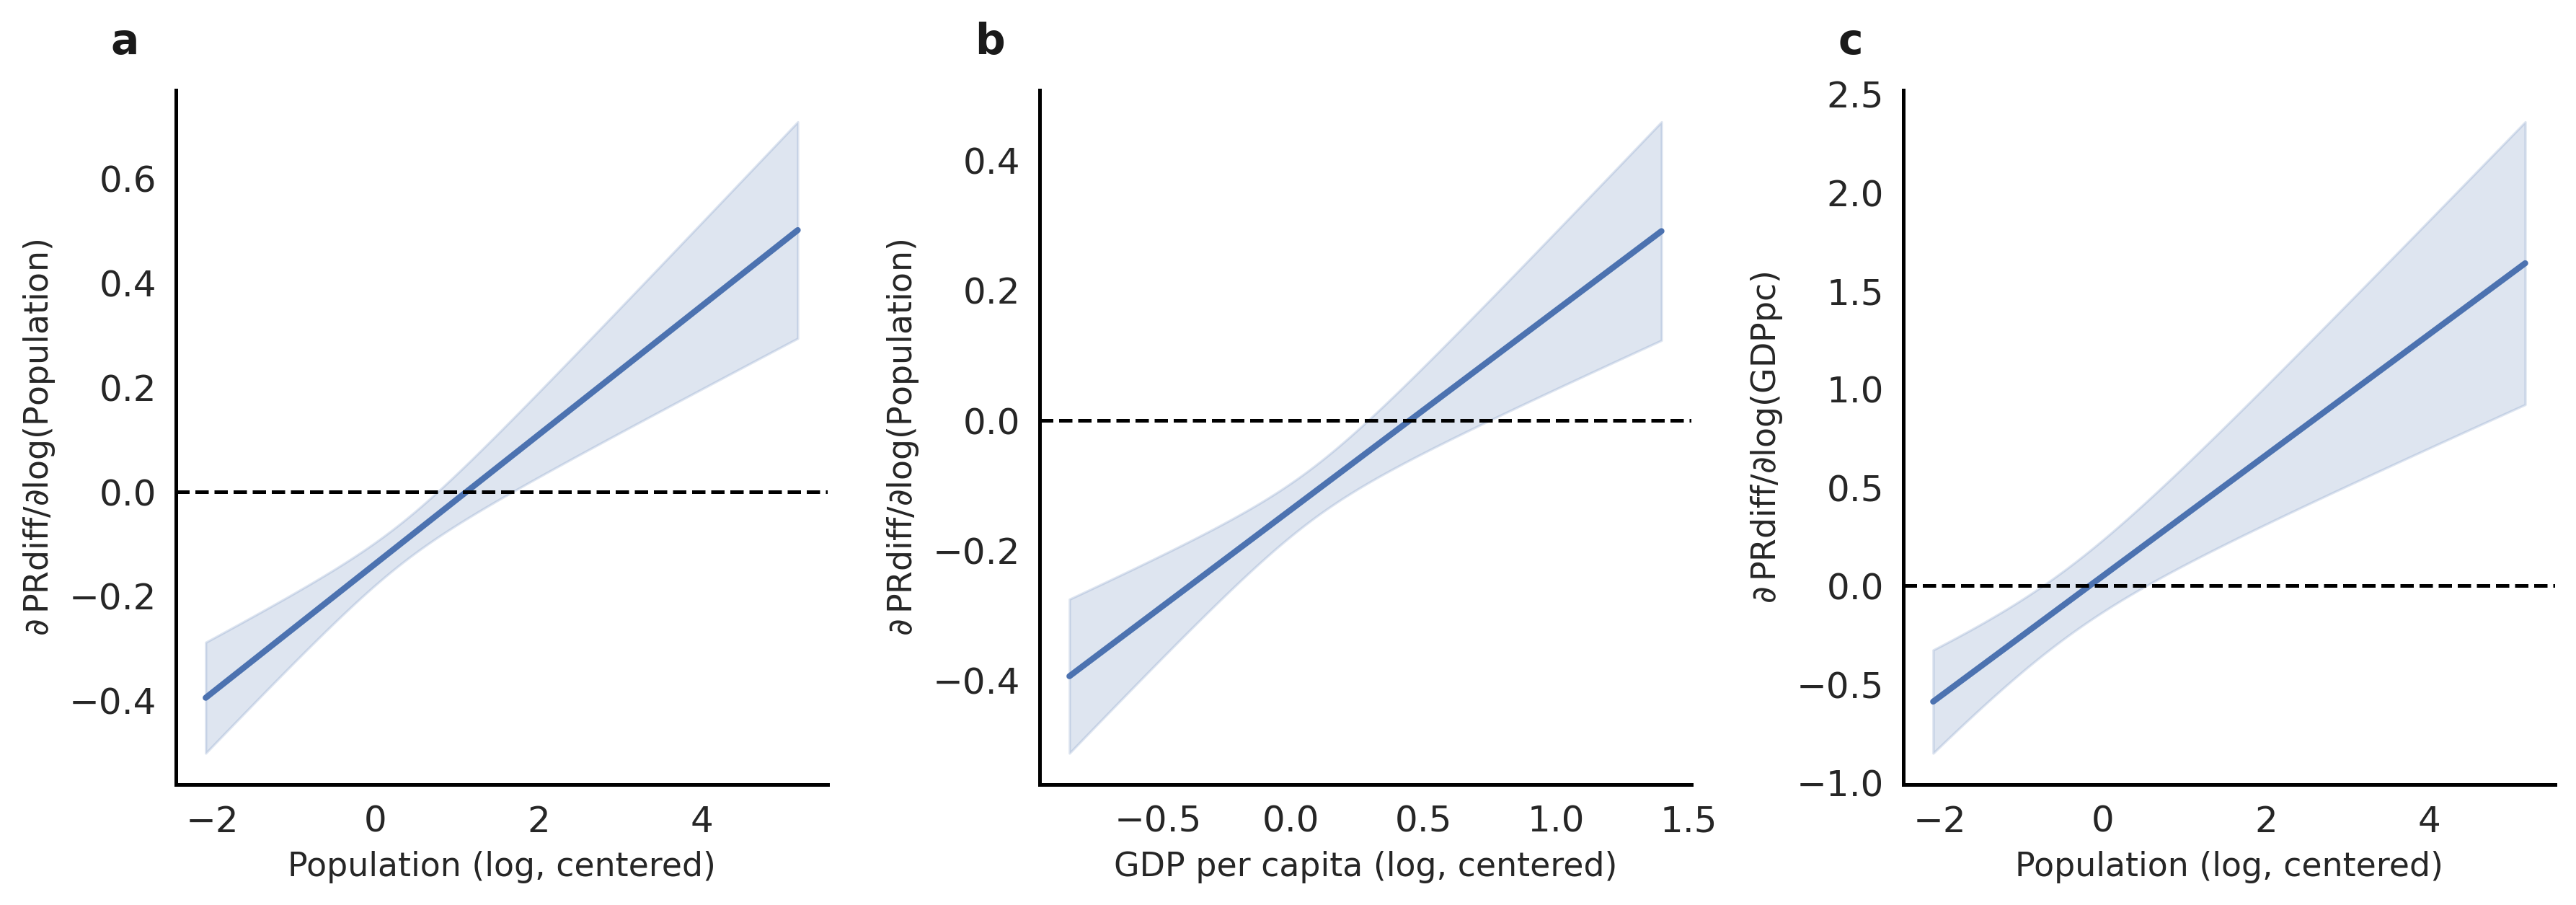

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

col = "#4C72B0"

# --- Panel 1 ---
axes[0].fill_between(L_range, ci1_lo, ci1_hi, color=col, alpha=0.18)
axes[0].plot(L_range, me_pop_L, color=col, lw=2)
axes[0].axhline(0, ls="--", color="black")
axes[0].set_xlabel("Population (log, centered)")
axes[0].set_ylabel(r"$\partial\,\mathrm{PRdiff}/\partial\log(\mathrm{Population})$")

# --- Panel 2 ---
axes[1].fill_between(G_range, ci2_lo, ci2_hi, color=col, alpha=0.18)
axes[1].plot(G_range, me_pop_G, color=col, lw=2)
axes[1].axhline(0, ls="--", color="black")
axes[1].set_xlabel("GDP per capita (log, centered)")
axes[1].set_ylabel(r"$\partial\,\mathrm{PRdiff}/\partial\log(\mathrm{Population})$")

# --- Panel 3 ---
axes[2].fill_between(L_range, ci3_lo, ci3_hi, color=col, alpha=0.18)
axes[2].plot(L_range, me_gdp_L, color=col, lw=2)
axes[2].axhline(0, ls="--", color="black")
axes[2].set_xlabel("Population (log, centered)")
axes[2].set_ylabel(r"$\partial\,\mathrm{PRdiff}/\partial\log(\mathrm{GDPpc})$")

for ax in axes:
    clean_axis(ax)

plt.tight_layout()

plots_l = ['a', 'b', 'c']
for ia, ax in enumerate(fig.axes): 
    x,y = -0.1,1.04
    ax.text(x,y,  plots_l[ia],
        color = 'k',#'lightgreen',
        horizontalalignment='left',
        verticalalignment='bottom',
        weight = 'bold',
        transform=ax.transAxes,fontsize = 14)

plt.savefig(
    '../fig/si/si_marginal_effects.pdf',
    bbox_inches='tight',
    dpi=300
)

plt.show()


5 groups of factors influencing the mobility preferences:

- Group 1: Agglomeration Size & Economic Power (GDP, Population, their interactions and squared term) 
- Group 2: Individual Wealth (Dividends and interest rates, median tax paid on real estate, real estate price - income ratio)
- Group 3: Labour Market Structure (Number of companies per 100k residents, number of employed per 100k residents, number of job postings)
- Group 4: Human Capital (education, health, inequality)
- Group 5: Geography (natural amenities, percentage of water, pop density, and somewhat risk)

In [38]:
groups = {
    "Agglomeration size &\n economic power": [
        "log_pop_centered",
        "log_gdp_centered",
        "log_pop_centered:log_gdp_centered",
        "I(log_pop_centered ** 2)"
    ],
    "Individual wealth": [
        "log_taxes_med_centered",
        "log_dividends_centered",
        "income_price_ratio2023_centered"
    ],
    "Labour market\n structure": [
        "log_est_100k_centered",
        "log_emp_100k_centered",
        "log_n_postings_centered"
    ],
    "Human capital": [
        "education_centered",
        "health_centered",
        "inequality_centered"
    ],
    "Geography": [
        "nat_amenity_centered",
        "water_perc_centered",
        "risk_centered"
    ]
}


import itertools
import math

def build_formula(dep_var, groups, selected_groups):
    rhs = []
    for g in selected_groups:
        rhs.extend(groups[g])
    rhs = list(dict.fromkeys(rhs))
    return dep_var + " ~ " + " + ".join(rhs)


dep_var = "pagerank_logdiff"

r2_map = {}

for k in range(len(groups) + 1):
    for combo in itertools.combinations(groups.keys(), k):

        if len(combo) == 0:
            formula = dep_var + " ~ 1"
        else:
            formula = build_formula(dep_var, groups, combo)

        model = smf.ols(formula=formula, data=df).fit()
        r2_map[frozenset(combo)] = model.rsquared

# --------------------------------------------------
# shapley (LMG) decomposition of R^2
# --------------------------------------------------

shapley = {g: 0.0 for g in groups}

G = list(groups.keys())
nG = len(G)

for g in G:
    for S in itertools.chain.from_iterable(
        itertools.combinations([x for x in G if x != g], r)
        for r in range(nG)
    ):
        S = frozenset(S)
        Sg = frozenset(set(S) | {g})

        weight = (
            math.factorial(len(S)) *
            math.factorial(nG - len(S) - 1) /
            math.factorial(nG)
        )

        delta_r2 = r2_map[Sg] - r2_map[S]
        shapley[g] += weight * delta_r2

# --------------------------------------------------
# results table
# --------------------------------------------------

results = (
    pd.DataFrame({
        "Group": shapley.keys(),
        "Shapley R2 contribution": shapley.values()
    })
    .sort_values("Shapley R2 contribution", ascending=False)
)

results["Share of total R2 (%)"] = (
    results["Shapley R2 contribution"] /
    sum(shapley.values()) * 100
)

results

,Group,Shapley R2 contribution,Share of total R2 (%)
0,Agglomeration size &\n economic power,0.243228,57.153796
2,Labour market\n structure,0.077864,18.296632
3,Human capital,0.044660,10.494187
1,Individual wealth,0.038464,9.038221
4,Geography,0.021351,5.017164


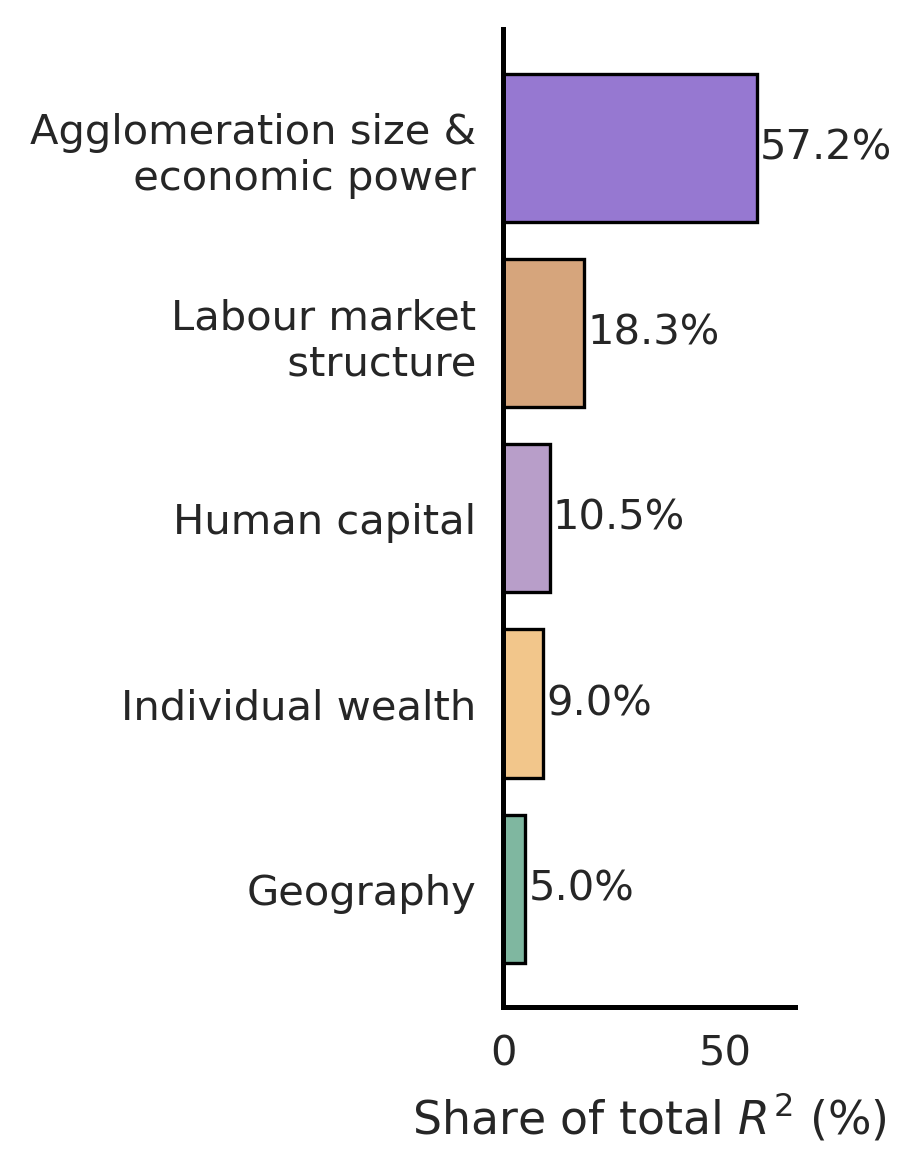

In [39]:
group_colors = {
    "Agglomeration size &\n economic power": "#9678D1",  # muted violet
    "Geography": "#7FB7A0",                              # sage green
    "Labour market\n structure": "#D6A57C",             # warm sand
    "Human capital": "#B89EC9",                          # lavender
    "Individual wealth": "#F2C68B"                       # soft amber
}

fig, ax = plt.subplots(figsize=(3, 4))

results = results.sort_values("Share of total R2 (%)", ascending=True)

ax.barh(
    results["Group"],
    results["Share of total R2 (%)"],
    color=results["Group"].map(group_colors),
    edgecolor="black",
    linewidth=0.8
)

for i, v in enumerate(results["Share of total R2 (%)"]):
    ax.text(
        v + 0.7,
        i,
        f"{v:.1f}%",
        va="center",
        fontsize=10
    )

# axis formatting
ax.set_xlabel("Share of total $R^2$ (%)")
ax.set_ylabel("")
ax.set_xlim(0, max(results["Share of total R2 (%)"]) * 1.15)

# remove grid, clean spines
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(axis="both", which="major")

plt.tight_layout()
plt.show()


In [40]:
from joblib import Parallel, delayed
from tqdm.auto import tqdm
from collections import defaultdict
import random

variables = [
    "log_pop_centered",
    "log_gdp_centered",
    "log_pop_centered:log_gdp_centered",
    "I(log_pop_centered ** 2)",
    "log_taxes_med_centered",
    "log_dividends_centered",
    "income_price_ratio2023_centered",
    "log_est_100k_centered",
    "log_emp_100k_centered",
    "log_n_postings_centered",
    "education_centered",
    "health_centered",
    "inequality_centered",
    "nat_amenity_centered",
    "water_perc_centered",
    "risk_centered",
]


def fit_r2(vars_subset, data):
    if len(vars_subset) == 0:
        return 0.0
    formula = "pagerank_logdiff ~ " + " + ".join(vars_subset)
    return smf.ols(formula, data=data).fit().rsquared


def shapley_one_permutation(variables, data, seed=None):
    if seed is not None:
        random.seed(seed)

    perm = variables.copy()
    random.shuffle(perm)

    contrib = defaultdict(float)
    included = []
    prev_r2 = 0.0

    for v in perm:
        included.append(v)
        r2_now = fit_r2(included, data)
        contrib[v] = r2_now - prev_r2
        prev_r2 = r2_now

    return contrib


n_permutations = 2000        
n_jobs = 12             

# run permutations in parallel
results_ind = Parallel(n_jobs=n_jobs)(
    delayed(shapley_one_permutation)(
        variables,
        df,
        seed=i
    )
    for i in tqdm(range(n_permutations), desc="Shapley permutations")
)

shapley = defaultdict(float)

for res in results_ind:
    for v, val in res.items():
        shapley[v] += val

# average over permutations
for v in shapley:
    shapley[v] /= n_permutations


Shapley permutations:   0%|          | 0/2000 [00:00<?, ?it/s]

In [41]:
R2_full = model_5.rsquared

shapley_var_df = (
    pd.DataFrame({
        "Variable": shapley.keys(),
        "Shapley R2": shapley.values()
    })
    .sort_values("Shapley R2", ascending=False)
    .reset_index(drop=True)
)

shapley_var_df["Share of total R2 (%)"] = (
    100 * shapley_var_df["Shapley R2"] / R2_full
)

shapley_var_df

,Variable,Shapley R2,Share of total R2 (%)
0,I(log_pop_centered ** 2),0.117873,27.698005
1,log_pop_centered:log_gdp_centered,0.086537,20.334524
2,log_est_100k_centered,0.037708,8.860756
3,log_pop_centered,0.031228,7.337974
4,log_emp_100k_centered,0.028502,6.697421
5,education_centered,0.026406,6.204949
6,income_price_ratio2023_centered,0.019881,4.671579
7,log_dividends_centered,0.015443,3.628823
8,log_n_postings_centered,0.011477,2.696792
9,log_gdp_centered,0.011455,2.691777


In [42]:
print("Sum of Shapley R2:", shapley_var_df["Shapley R2"].sum())
print("Full model R2:", R2_full)

Sum of Shapley R2: 0.42556672485063857
Full model R2: 0.42556672485063884


In [43]:
groups = { "Agglomeration size &\n economic power": [ "log_pop_centered", "log_gdp_centered", "log_pop_centered:log_gdp_centered", "I(log_pop_centered ** 2)" ], 
          "Individual wealth": [ "log_taxes_med_centered", "log_dividends_centered", "income_price_ratio2023_centered" ],
          "Human capital": [ "education_centered", "health_centered", "inequality_centered" ], 
          "Labour market\n structure": [ "log_est_100k_centered", "log_emp_100k_centered", "log_n_postings_centered" ], 
          "Geography": [ "nat_amenity_centered", "water_perc_centered", "risk_centered" ] }

var_to_group = {
    var: group
    for group, vars_in_group in groups.items()
    for var in vars_in_group
}

shapley_var_df["Group"] = shapley_var_df["Variable"].map(var_to_group)

# sort by partial R2
results = results.sort_values('Share of total R2 (%)', ascending=False)
group_order = (
    results.Group
)

# within each group: variables sorted by partial R2 (descending)
shapley_var_df["Group"] = pd.Categorical(shapley_var_df["Group"], categories=group_order, ordered=True)
shapley_var_df = shapley_var_df.sort_values(["Group", "Shapley R2"], ascending=[False, True]).reset_index(drop=True)

# y positions
shapley_var_df["y"] = np.arange(len(shapley_var_df))

var_labels = {
    "log_pop_centered": "Pop",
    "log_gdp_centered": "GDPpc",
    "log_pop_centered:log_gdp_centered": "Pop × GDPpc",
    "I(log_pop_centered ** 2)": "Pop²",
    "nat_amenity_centered": "Natural amenities",
    "risk_centered": "Hazard risk",
    "water_perc_centered": "Water share",
    "education_centered": "Education",
    "inequality_centered": "Inequality",
    "health_centered": "Health",
    "income_price_ratio2023_centered": "Price–income ratio",
    "log_taxes_med_centered": "Real estate taxes",
    "log_dividends_centered": "Dividends",
    "log_est_100k_centered": "Establishments",
    "log_emp_100k_centered": "Employment",
    "log_n_postings_centered": "Job postings",
}

shapley_var_df["label"] = shapley_var_df["Variable"].map(var_labels)


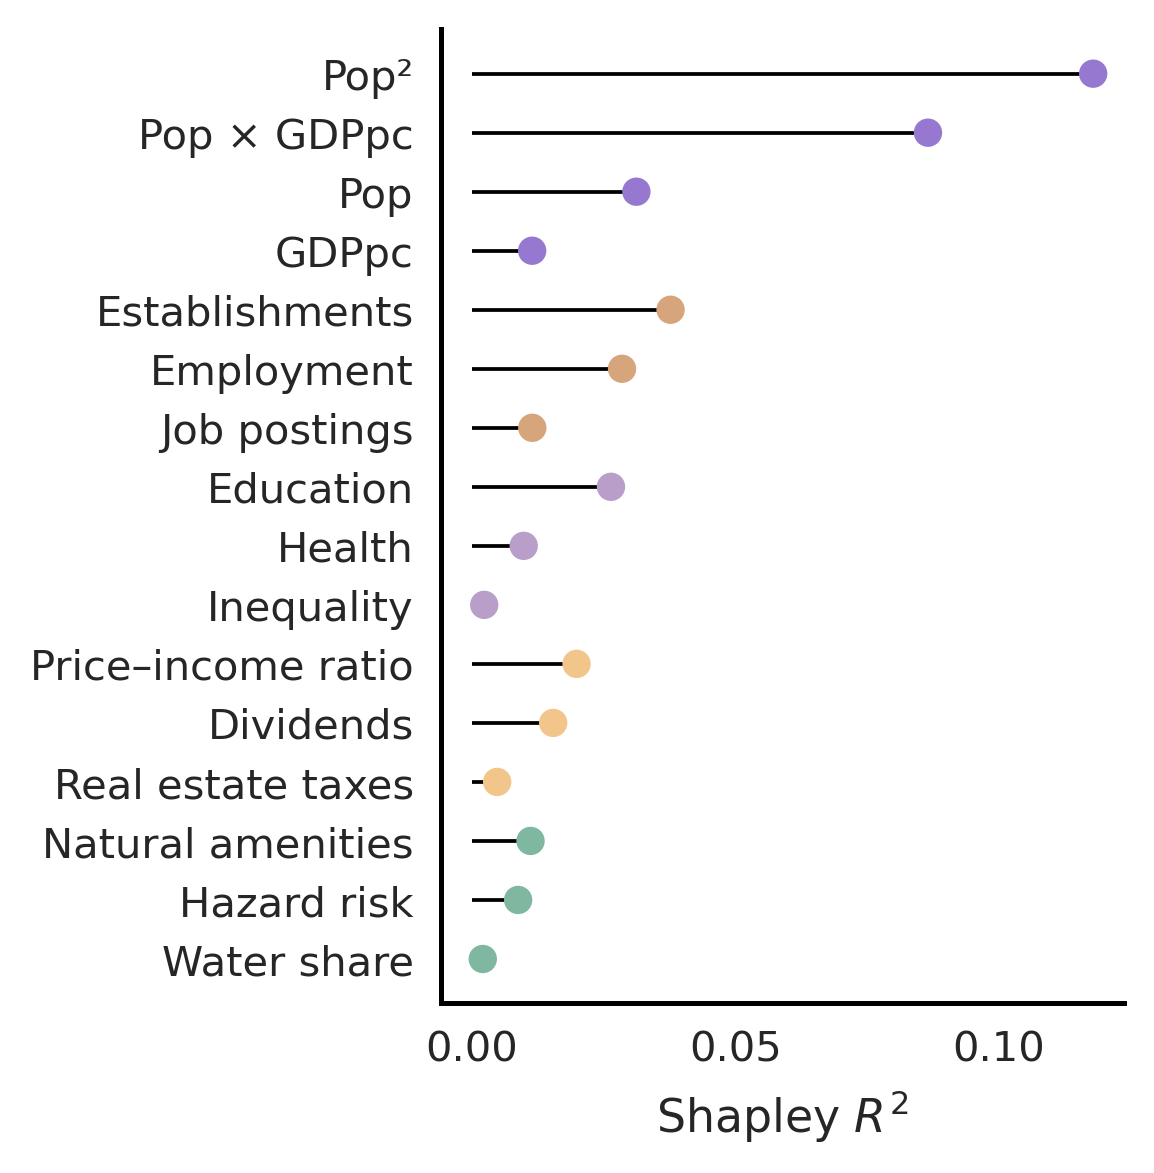

In [44]:
groups = shapley_var_df["Group"].unique()

fig, ax = plt.subplots(figsize=(4, 4))

# stems
ax.hlines(
    y=shapley_var_df["y"],
    xmin=0,
    xmax=shapley_var_df["Shapley R2"],
    color="black",
    linewidth=0.9
)

# heads (colored by group)
ax.scatter(
    shapley_var_df["Shapley R2"],
    shapley_var_df["y"],
    c=shapley_var_df["Group"].map(group_colors),
    s=36,
    zorder=3
)

# axis formatting
ax.set_xlabel("Shapley $R^2$")
ax.set_yticks(shapley_var_df["y"])
ax.set_yticklabels(shapley_var_df["label"])

# ax.set_xscale("log")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(False)


plt.tight_layout()
plt.show()


In [45]:
import re

records = []
rows = df_results.reset_index()

for i in range(len(rows) - 1):

    var = rows.loc[i, "index"]
    coef_cell = rows.loc[i, "Model 5 I"]
    se_cell   = rows.loc[i + 1, "Model 5 I"]

    # coefficient rows are strings; SE rows start with "("
    if not isinstance(coef_cell, str):
        continue
    if not isinstance(se_cell, str) or not se_cell.startswith("("):
        continue
    if var in ["Intercept", "R-squared", "R-squared Adj.", "BIC", "N"]:
        continue

    coef = float(re.sub(r"[^\d\.\-]", "", coef_cell))
    se   = float(re.sub(r"[^\d\.\-]", "", se_cell))

    sig = re.sub(r"[\d\.\-\s]", "", coef_cell)   # keeps *, **, *** or +

    records.append({
        "Variable": var,
        "coef": coef,
        "se": se,
        "sig": sig
    })



coef_df = pd.DataFrame(records)

coef_df["ci_low"] = coef_df["coef"] - 1.96 * coef_df["se"]
coef_df["ci_high"] = coef_df["coef"] + 1.96 * coef_df["se"]

var_to_group = {
    "log_pop_centered": "Agglomeration size &\n economic power",
    "log_gdp_centered": "Agglomeration size &\n economic power",
    "log_pop_centered:log_gdp_centered": "Agglomeration size &\n economic power",
    "I(log_pop_centered ** 2)": "Agglomeration size &\n economic power",

    "log_taxes_med_centered": "Individual wealth",
    "log_dividends_centered": "Individual wealth",
    "income_price_ratio2023_centered": "Individual wealth",

    "log_est_100k_centered": "Labour market\n structure",
    "log_emp_100k_centered": "Labour market\n structure",
    "log_n_postings_centered": "Labour market\n structure",

    "education_centered": "Human capital",
    "health_centered": "Human capital",
    "inequality_centered": "Human capital",

    "nat_amenity_centered": "Geography",
    "water_perc_centered": "Geography",
    "risk_centered": "Geography"
}

coef_df["Group"] = coef_df["Variable"].map(var_to_group)
coef_df = coef_df.dropna(subset=["Group"])



In [46]:
var_name_map = {
    "log_pop_centered:log_gdp_centered": "Pop × GDPpc",
    "I(log_pop_centered ** 2)": "Pop²",
    "log_gdp_centered": "GDPpc",
    "log_pop_centered": "Pop",

    "nat_amenity_centered": "Natural amenities",
    "risk_centered": "Hazard risk",
    "log_pop_density_centered": "Pop density",
    "water_perc_centered": "Water share",

    "education_centered": "Education",
    "inequality_centered": "Inequality",
    "health_centered": "Health",

    "income_price_ratio2023_centered": "Price-income ratio",
    "log_taxes_med_centered": "Real estate taxes",
    "log_dividends_centered": "Dividends",

    "log_est_100k_centered": "Establishments",
    "log_emp_100k_centered": "Employment",
    "log_n_postings_centered": "Job postings"
}

coef_df["Variable_label"] = coef_df["Variable"].map(var_name_map)

variable_order = shapley_var_df['Variable']

coef_df["Variable"] = pd.Categorical(
    coef_df["Variable"],
    categories=variable_order,
    ordered=True
)

coef_df = coef_df.sort_values("Variable").reset_index(drop=True)
coef_df["y"] = range(len(coef_df))

In [47]:
group_colors = {
    "Agglomeration size &\n economic power": "#9678D1",  # muted violet
    "Geography": "#7FB7A0",                              # sage green
    "Labour market\n structure": "#D6A57C",             # warm sand
    "Human capital": "#B89EC9",                          # lavender
    "Individual wealth": "#F2C68B"                       # soft amber
}



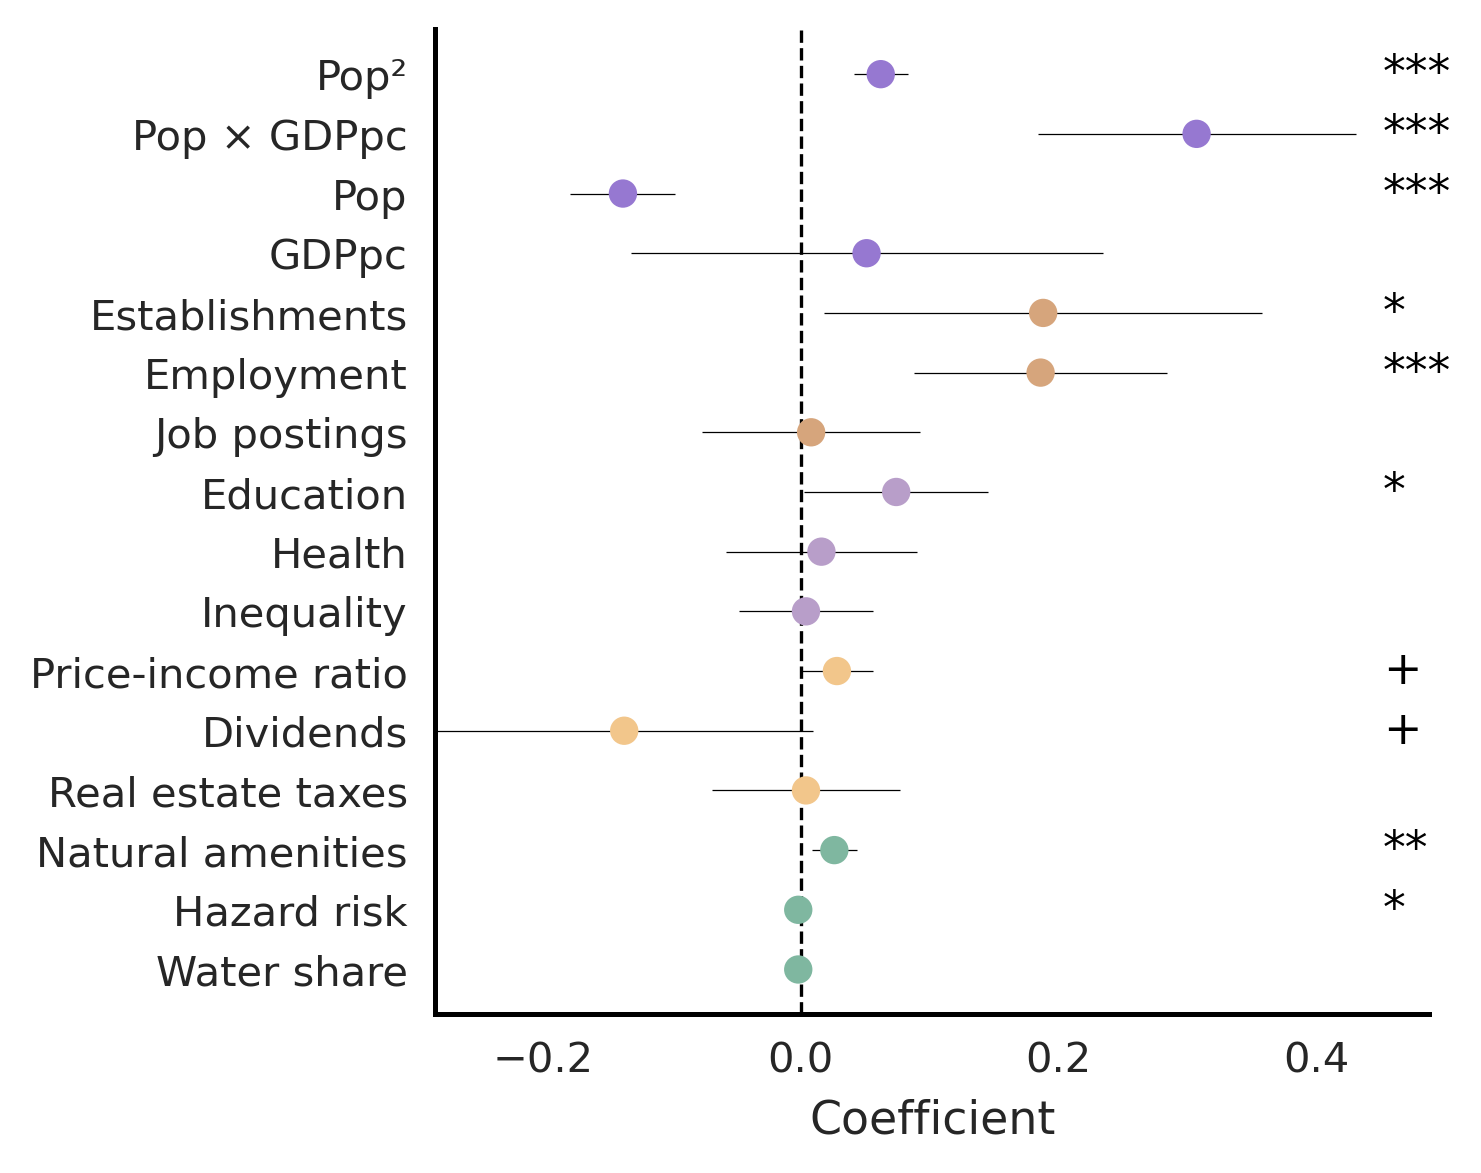

In [48]:
fig, ax = plt.subplots(figsize=(5, 4))

# confidence intervals
ax.hlines(
    y=coef_df["y"],
    xmin=coef_df["ci_low"],
    xmax=coef_df["ci_high"],
    color="black",
    linewidth=0.3
)

# point estimates
ax.scatter(
    coef_df["coef"],
    coef_df["y"],
    c=coef_df["Group"].map(group_colors),
    s=36,
    zorder=3
)

# zero line
ax.axvline(0, color="black", linestyle="--", linewidth=0.8)

ax.set_yticks(coef_df["y"])
ax.set_yticklabels(coef_df["Variable_label"])

ax.set_xlabel("Coefficient")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(False)

sig_x = coef_df["ci_high"].max() + 0.03 * (
    coef_df["ci_high"].max() - coef_df["ci_low"].min()
)

for _, row in coef_df.iterrows():
    if row["sig"] != "":
        ax.text(
            sig_x,
            row["y"],
            row["sig"],
            fontsize=11,
            va="center",
            ha="left",
            color="black",
            zorder=4
        )

ax.set_xlim(
    coef_df["ci_low"].min(),
    sig_x + 0.05 * (coef_df["ci_high"].max() - coef_df["ci_low"].min())
)


plt.tight_layout()
plt.show()


In [49]:
df.to_csv('../data_generated/df_merged_cbsa2.csv')

### Temporal Dynamics

In [50]:
nri_county=df = pd.read_parquet("../data_loaded/nri_counties.parquet")
counties = load_counties()


In [51]:
hits_exp = pd.read_parquet("../data_generated/network_metrics/cbsa2_hits_exp_3y.parquet")
hits_irs = pd.read_parquet("../data_generated/network_metrics/cbsa2_hits_irs_3y.parquet")

hits_merged=hits_irs.merge(hits_exp, left_on=['window', 'CBSA'], right_on=['window', 'CBSA'], how='inner', suffixes=('_irs', '_exp'))

cbsa = load_cbsa()


In [52]:
business = pd.read_csv("../data_loaded/cbp22co.zip", sep=',')

business["STCOFIPS"] = (
            business["fipstate"].astype(str).str.zfill(2)
            + business["fipscty"].astype(str).str.zfill(3))

business=business[business['naics'].isin(['51----','52----','53----','54----','55----','56----'])]

business=business.groupby('STCOFIPS').agg({'emp':'sum', 'est':'sum'}).reset_index()

In [53]:
hits_merged['pagerank_diff']=hits_merged['pagerank_exp']-hits_merged['pagerank_irs']

xwalk = cbsa[['STCOFIPS', 'CBSA Code', 'CBSA Title']].drop_duplicates()

counties = counties.merge(xwalk, on='STCOFIPS', how='left')
nri_county = nri_county.merge(xwalk, on='STCOFIPS', how='left')

counties_cbsa = (
    counties
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code', 'CBSA Title'], as_index=False)
    .agg(
        ALAND=('ALAND', 'sum'),
        AWATER=('AWATER', 'sum')
    )
)
counties_cbsa['water_perc'] = counties_cbsa['AWATER'] / (counties_cbsa['ALAND'] + counties_cbsa['AWATER']) * 100


def wmean(x, w):
    x = pd.to_numeric(x, errors='coerce')
    w = pd.to_numeric(w, errors='coerce')
    m = x.notna() & w.notna()
    if not m.any():
        return np.nan
    return np.average(x[m], weights=w[m])

hazards = [
    'RISK_SCORE', 'AVLN_RISKS', 'CFLD_RISKS', 'CWAV_RISKS', 'DRGT_RISKS',
    'ERQK_RISKS', 'HAIL_RISKS', 'HWAV_RISKS', 'HRCN_RISKS', 'ISTM_RISKS',
    'LNDS_RISKS', 'LTNG_RISKS', 'RFLD_RISKS', 'SWND_RISKS', 'TRND_RISKS',
    'TSUN_RISKS', 'VLCN_RISKS', 'WFIR_RISKS', 'WNTW_RISKS'
]

nri_county[hazards] = (
    nri_county[hazards]
    .replace(-9999, np.nan)
    .apply(pd.to_numeric, errors='coerce')
)


nri_cbsa = (
    nri_county
    .dropna(subset=['CBSA Code'])
    .assign(POPULATION=pd.to_numeric(nri_county['POPULATION'], errors='coerce'))
    .groupby(['CBSA Code', 'CBSA Title'], as_index=False)
    .agg(
        POPULATION=('POPULATION', 'sum'),
        **{h: (h, 'mean') for h in hazards}
    )
)

cbsa_agg = (
    counties_cbsa
    .merge(nri_cbsa, on=['CBSA Code', 'CBSA Title'], how='outer')
)

cbsa_agg['pop_density'] = cbsa_agg['POPULATION'] / cbsa_agg['ALAND'] * 1_000_000


hits_merged = hits_merged.merge(
    cbsa_agg,
    left_on=['CBSA'],
    right_on=['CBSA Code'],
    how='left',
    suffixes=('', '_cbsa')
)

In [54]:
## Job postings

jobposts=pd.read_csv('../data_loaded/jobpostings_aggregated/job_postings_county_month.csv')
jobposts_naics=pd.read_csv('../data_loaded/jobpostings_aggregated/job_postings_county_month_naics.csv')

jobposts_naics['year'] = jobposts_naics['month_year'].str[:4].astype(int)
jobposts_naics = jobposts_naics[jobposts_naics['year'].isin([2016, 2017, 2018,2019])].reset_index(drop=True)

jobposts_naics['STCOFIPS']=jobposts_naics['STCOFIPS'].astype(str)
jobposts_naics = jobposts_naics.merge(xwalk, on='STCOFIPS', how='left')

total_posts = (
    jobposts_naics
    .groupby(["CBSA Code"])
    .n_postings
    .sum()
    .reset_index()
    .rename(columns={"n_postings": "total_postings"})
)

target_posts = (
    jobposts_naics[jobposts_naics["NAICS_2"].isin([51, 52, 53, 54, 55, 56])]
    .groupby(["CBSA Code"])
    .n_postings
    .sum()
    .reset_index()
    .rename(columns={"n_postings": "target_postings"})
)

jobposts_share = (
    total_posts
    .merge(target_posts, on=["CBSA Code"], how="left")
)

jobposts_share["target_postings"] = jobposts_share["target_postings"].fillna(0)
jobposts_share["share_target_pct"] = (
    100 * jobposts_share["target_postings"] / jobposts_share["total_postings"]
)

jobposts_share['CBSA Code']=jobposts_share['CBSA Code'].astype(str)
jobposts_share["CBSA Code"]=jobposts_share["CBSA Code"].astype(str).str.zfill(5)

hits_merged=hits_merged.merge(jobposts_share, left_on='CBSA', right_on='CBSA Code', how='left')
hits_merged['target_postings'] = hits_merged['target_postings'].fillna(0)
hits_merged['n_postings_100k'] = hits_merged['target_postings']/hits_merged['POPULATION']*100_000

In [55]:
business = business.merge(xwalk, on='STCOFIPS', how='left')
business=business.groupby('CBSA Code').agg({'emp':'sum', 'est':'sum'}).reset_index()

hits_merged=hits_merged.merge(business, left_on='CBSA', right_on='CBSA Code', how='left')

hits_merged['emp_100k'] = hits_merged['emp']/hits_merged['POPULATION']*100_000
hits_merged['est_100k'] = hits_merged['est']/hits_merged['POPULATION']*100_000

In [56]:
# MY URBAN
pop_w = nri_county[['STCOFIPS', 'POPULATION']].copy()
pop_w['POPULATION'] = pd.to_numeric(pop_w['POPULATION'], errors='coerce')

urban=pd.read_parquet('../data_loaded/data_final/urban_afford.parquet')
urban['STCOFIPS'] = urban['STCOFIPS'].astype(str)

urban_cbsa_in = (
    urban[['STCOFIPS','nat_amenity_score','urbanism','real_estate_taxes_med',
           'med_home_price2017','income_price_ratio2023','inequality_ratio']]
    .merge(pop_w, on='STCOFIPS', how='left')
    .merge(xwalk, on='STCOFIPS', how='left')
)

urbanism_dict = {
    "6 - Noncore": 1,
    "5 - Micropolitan": 2,
    "4 - Small metro": 3,
    "3 - Medium metro": 4,
    "2 - Large fringe metro": 5,
    "1 - Large central metro": 6
}

urban_cbsa_in["urbanism"] = urban_cbsa_in["urbanism"].map(urbanism_dict)


urban_cbsa = (
    urban_cbsa_in
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code', 'CBSA Title'], as_index=False)
    .apply(lambda g: pd.Series({
        'nat_amenity_score': wmean(g['nat_amenity_score'], g['POPULATION']),
        'real_estate_taxes_med': wmean(g['real_estate_taxes_med'], g['POPULATION']),
        'med_home_price2017': wmean(g['med_home_price2017'], g['POPULATION']),
        'income_price_ratio2023': wmean(g['income_price_ratio2023'], g['POPULATION']),
        'inequality_ratio': wmean(g['inequality_ratio'], g['POPULATION']),

        'urbanism_pwmean': wmean(g['urbanism'], g['POPULATION'])
    }))
    .reset_index(drop=True)
)

urban_r = urban_cbsa.set_index('CBSA Code').drop(columns=['CBSA Title'], errors='ignore')

hits_merged = hits_merged.join(urban_r, on='CBSA')

In [57]:
## MY HDI

education_calulated=pd.read_parquet('../data_loaded/data_final/education_combined.parquet')
health_calulated=pd.read_parquet('../data_loaded/data_final/health_combined.parquet')
income_calulated=pd.read_parquet('../data_loaded/data_final/median_income_combined.parquet')

health_calulated=health_calulated[health_calulated['year']==2020][['STCOFIPS', 'health_index', 'health_index_adj']]
income_calulated=income_calulated[income_calulated['year']==2020][['STCOFIPS', 'income_index', 'income_index_adj']]

## MY INCOME
income_combined=pd.read_parquet('../data_loaded/data_final/income_combined.parquet')
income_combined=income_combined[income_combined['year']==2019].reset_index(drop=True)

income_combined = income_combined.pivot_table(
    index=["STCOFIPS"],    
    columns="Description",  
    values="value",        
    aggfunc="first"
).reset_index()

income_combined.columns.name = None

income_combined['gdp_pc']=income_combined['real_gdp_chained_2017']/income_combined['population']
income_combined['dividends_pc']=income_combined['dividends']/income_combined['population']

income_combined=income_combined[['STCOFIPS', 'personal_income_pc', 'poverty_rate_all', 'gdp_pc', 'dividends_pc', 'dividends']]

In [58]:
pop_w = nri_county[['STCOFIPS', 'POPULATION']].copy()
pop_w['POPULATION'] = pd.to_numeric(pop_w['POPULATION'], errors='coerce')

education_cbsa = (
    education_calulated
    .merge(pop_w, on='STCOFIPS', how='left')
    .merge(xwalk, on='STCOFIPS', how='left')
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code'], as_index=False)
    .apply(lambda g: pd.Series({
        'education_index': wmean(g['education_index'], g['POPULATION'])
    }))
    .reset_index(drop=True)
)

health_cbsa = (
    health_calulated
    .merge(pop_w, on='STCOFIPS', how='left')
    .merge(xwalk, on='STCOFIPS', how='left')
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code'], as_index=False)
    .apply(lambda g: pd.Series({
        'health_index_adj': wmean(g['health_index_adj'], g['POPULATION'])
    }))
    .reset_index(drop=True)
)

income_cbsa = (
    income_calulated
    .merge(pop_w, on='STCOFIPS', how='left')
    .merge(xwalk, on='STCOFIPS', how='left')
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code'], as_index=False)
    .apply(lambda g: pd.Series({
        'income_index_adj': wmean(g['income_index_adj'], g['POPULATION'])
    }))
    .reset_index(drop=True)
)

combined_income_cbsa = (
    income_combined
    .merge(pop_w, on='STCOFIPS', how='left')
    .merge(xwalk, on='STCOFIPS', how='left')
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code'], as_index=False)
    .apply(lambda g: pd.Series({
        'personal_income_pc': wmean(g['personal_income_pc'], g['POPULATION']),
        'poverty_rate_all': wmean(g['poverty_rate_all'], g['POPULATION']),
        'gdp_pc': wmean(g['gdp_pc'], g['POPULATION']),
        'dividends_pc': wmean(g['dividends_pc'], g['POPULATION']),
        'dividends': pd.to_numeric(g['dividends'], errors='coerce').sum(skipna=True),
        'POPULATION_sum': g['POPULATION'].sum(skipna=True)
    }))
    .reset_index(drop=True)
)



In [59]:
hits_merged['CBSA'] = hits_merged['CBSA'].astype(str)

for df in [education_cbsa, health_cbsa, income_cbsa, combined_income_cbsa]:
    df['CBSA Code'] = df['CBSA Code'].astype(str)

education_r = education_cbsa.set_index('CBSA Code').drop(columns=['CBSA Title'], errors='ignore')
health_r    = health_cbsa.set_index('CBSA Code').drop(columns=['CBSA Title'], errors='ignore')
income_r    = income_cbsa.set_index('CBSA Code').drop(columns=['CBSA Title'], errors='ignore')
cincome_r   = combined_income_cbsa.set_index('CBSA Code').drop(columns=['CBSA Title'], errors='ignore')

hits_merged = (
    hits_merged
    .join(education_r, on='CBSA')
    .join(health_r, on='CBSA')
    .join(income_r, on='CBSA')
    .join(cincome_r, on='CBSA')
)


In [60]:
df = hits_merged.copy()
na_counts = df.isna().sum()
print(na_counts[na_counts > 0])

AVLN_RISKS                2702
CFLD_RISKS                2368
HRCN_RISKS                 808
ISTM_RISKS                 248
LNDS_RISKS                  14
LTNG_RISKS                  30
TSUN_RISKS                2874
VLCN_RISKS                2874
CBSA Code_y                355
total_postings             355
share_target_pct           355
nat_amenity_score           30
med_home_price2017          31
income_price_ratio2023      31
personal_income_pc          19
gdp_pc                      19
dividends_pc                19
dtype: int64


In [61]:
df = hits_merged[hits_merged["window"] == "2020-2022"].copy()
df1 = hits_merged[hits_merged["window"] == "2011-2013"].copy()
df2 = hits_merged[hits_merged["window"] == "2014-2016"].copy()
df3 = hits_merged[hits_merged["window"] == "2017-2019"].copy()

# log transforms (avoid −inf)
for col in ["pagerank_irs", "pagerank_exp"]:
    df[f"log_{col}"] = (df[col] + 1e-12).apply(np.log)
    df1[f"log_{col}"] = (df1[col] + 1e-12).apply(np.log)
    df2[f"log_{col}"] = (df2[col] + 1e-12).apply(np.log)
    df3[f"log_{col}"] = (df3[col] + 1e-12).apply(np.log)

for col in ['POPULATION', 'target_postings', 'n_postings_100k', 'emp_100k', 'est_100k', 
            'personal_income_pc', 'gdp_pc', 'dividends_pc', 'pop_density',
            'real_estate_taxes_med', 'med_home_price2017']:
    df[f"log_{col}"] = (df[col]).apply(np.log1p)
    df1[f"log_{col}"] = (df1[col]).apply(np.log1p)
    df2[f"log_{col}"] = (df2[col]).apply(np.log1p)
    df3[f"log_{col}"] = (df3[col]).apply(np.log1p)

df['pagerank_logdiff']=df['log_pagerank_exp']-df['log_pagerank_irs']
df1['pagerank_logdiff']=df1['log_pagerank_exp']-df1['log_pagerank_irs']
df2['pagerank_logdiff']=df2['log_pagerank_exp']-df2['log_pagerank_irs']
df3['pagerank_logdiff']=df3['log_pagerank_exp']-df3['log_pagerank_irs']

df=df.dropna(subset=df.columns.difference(hazards)).reset_index(drop=True)
df1=df1.dropna(subset=df1.columns.difference(hazards)).reset_index(drop=True)
df2=df2.dropna(subset=df2.columns.difference(hazards)).reset_index(drop=True)
df3=df3.dropna(subset=df3.columns.difference(hazards)).reset_index(drop=True)

In [62]:
for dataset in [df, df1, df2, df3]:
    dataset['log_pop_centered'] = dataset['log_POPULATION'] - dataset['log_POPULATION'].mean()
    dataset['log_n_postings_centered'] = dataset['log_n_postings_100k'] - dataset['log_n_postings_100k'].mean()
    dataset['log_gdp_centered'] = dataset['log_gdp_pc'] - dataset['log_gdp_pc'].mean()
    dataset['education_centered'] = dataset['education_index'] - dataset['education_index'].mean()
    dataset['income_centered'] = dataset['income_index_adj'] - dataset['income_index_adj'].mean()
    dataset['health_centered'] = dataset['health_index_adj'] - dataset['health_index_adj'].mean()
    dataset['risk_centered'] = dataset['RISK_SCORE'] - dataset['RISK_SCORE'].mean()
    dataset['poverty_rate_centered'] = dataset['poverty_rate_all'] - dataset['poverty_rate_all'].mean()
    dataset['nat_amenity_centered'] = dataset['nat_amenity_score'] - dataset['nat_amenity_score'].mean()
    dataset['log_taxes_med_centered'] = dataset['log_real_estate_taxes_med'] - dataset['log_real_estate_taxes_med'].mean()
    dataset['income_price_ratio2023_centered'] = dataset['income_price_ratio2023'] - dataset['income_price_ratio2023'].mean()
    dataset['log_personal_income_centered'] = dataset['log_personal_income_pc'] - dataset['log_personal_income_pc'].mean()
    dataset['log_est_100k_centered'] = dataset['log_est_100k'] - dataset['log_est_100k'].mean()
    dataset['log_emp_100k_centered'] = dataset['log_emp_100k'] - dataset['log_emp_100k'].mean()
    dataset['water_perc_centered'] = dataset['water_perc'] - dataset['water_perc'].mean()
    dataset['log_pop_density_centered'] = dataset['log_pop_density'] - dataset['log_pop_density'].mean()
    dataset['log_dividends_centered'] = dataset['log_dividends_pc'] - dataset['log_dividends_pc'].mean()
    dataset['inequality_centered'] = dataset['inequality_ratio'] - dataset['inequality_ratio'].mean()

In [63]:
# Regressions
model_riskint = smf.ols(
    formula=(
            "pagerank_logdiff ~ risk_centered + log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
            "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered"
            "+ education_centered + health_centered + inequality_centered"
            "+ nat_amenity_centered + water_perc_centered"
    ),
    data=df
).fit(cov_type='HC3')

model_riskint1 = smf.ols(
    formula=(
            "pagerank_logdiff ~ risk_centered + log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
            "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered"
            "+ education_centered + health_centered + inequality_centered"
            "+ nat_amenity_centered + water_perc_centered"
    ),
    data=df1
).fit(cov_type='HC3')

model_riskint2 = smf.ols(
    formula=(
            "pagerank_logdiff ~ risk_centered + log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
            "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered"
            "+ education_centered + health_centered + inequality_centered"
            "+ nat_amenity_centered + water_perc_centered"
    ),
    data=df2
).fit(cov_type='HC3')

model_riskint3 = smf.ols(
    formula=(
            "pagerank_logdiff ~ risk_centered + log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
            "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered"
            "+ education_centered + health_centered + inequality_centered"
            "+ nat_amenity_centered + water_perc_centered"
    ),
    data=df3
).fit(cov_type='HC3')

In [64]:
model_dict = {
    "2011–2013": model_riskint1,
    "2014–2016": model_riskint2,
    "2017–2019": model_riskint3,
    "2020–2022": model_riskint
}

In [65]:
results_table = summary_col(
    list(model_dict.values()),
    stars=False,
    model_names=list(model_dict.keys()),
    info_dict={
        "N": lambda x: f"{int(x.nobs)}",
        "BIC": lambda x: f"{x.bic:.0f}"
    }
)


In [66]:
df_table = results_table.tables[0]

# Loop through model columns
for col in model_dict.keys():  
    model = model_dict[col]  # get model object
    
    for row in df_table.index:
        cell = df_table.loc[row, col]

        # Some rows (N, AIC) are not numeric → skip
        try:
            coef = float(cell.split()[0])
        except:
            continue
        
        # Get p-value for this coefficient
        pval = model.pvalues.get(row, 1.0)
        star = make_stars(pval)
        
        df_table.loc[row, col] = f"{coef:.3f}{star}"


In [67]:
df_table

,2011–2013,2014–2016,2017–2019,2020–2022
Intercept,-0.666***,-0.725***,-0.695***,-0.632***
,(0.0189),(0.0206),(0.0214),(0.0219)
risk_centered,-0.002*,-0.001,-0.001,-0.002*
,(0.0008),(0.0008),(0.0008),(0.0010)
log_pop_centered,-0.173***,-0.141***,-0.150***,-0.180***
,(0.0205),(0.0236),(0.0215),(0.0236)
log_gdp_centered,0.121,0.155,0.050,0.014
,(0.0833),(0.0969),(0.0967),(0.1283)
log_pop_centered:log_gdp_centered,0.362***,0.256***,0.285***,0.135
,(0.0537),(0.0688),(0.0627),(0.1049)


In [68]:
group_map = {
    "Agglomeration": [
        "log_pop_centered",
        "log_gdp_centered",
        "log_pop_centered:log_gdp_centered",
        "I(log_pop_centered ** 2)"
    ],
    "Individual wealth": [
        "log_taxes_med_centered",
        "log_dividends_centered",
        "income_price_ratio2023_centered"
    ],
    "Labour market": [
        "log_est_100k_centered",
        "log_emp_100k_centered",
        "log_n_postings_centered"
    ],
    "Human capital": [
        "education_centered",
        "health_centered",
        "inequality_centered"
    ],
    "Geography": [
        "nat_amenity_centered",
        "water_perc_centered",
        "risk_centered"
    ]
}

group_order = list(group_map.keys())


In [69]:
var_order = [
     'water_perc_centered',
     'risk_centered',
     'nat_amenity_centered',
     'log_taxes_med_centered',
     'log_dividends_centered',
     'income_price_ratio2023_centered',
     'inequality_centered',
     'health_centered',
     'education_centered',
     'log_n_postings_centered',
     'log_emp_100k_centered',
     'log_est_100k_centered',
     'log_gdp_centered',
     'log_pop_centered',
     'log_pop_centered:log_gdp_centered',
     'I(log_pop_centered ** 2)'
]

var_labels = {
    "log_pop_centered:log_gdp_centered": "Pop × GDPpc",
    "I(log_pop_centered ** 2)": "Pop²",
    "log_gdp_centered": "GDPpc",
    "log_pop_centered": "Pop",
    "nat_amenity_centered": "Natural amenities",
    "risk_centered": "Hazard risk",
    "log_pop_density_centered": "Pop density",
    "water_perc_centered": "Water share",
    "education_centered": "Education",
    "inequality_centered": "Inequality",
    "health_centered": "Health",
    "income_price_ratio2023_centered": "Price-income ratio",
    "log_taxes_med_centered": "Real estate taxes",
    "log_dividends_centered": "Dividends",
    "log_est_100k_centered": "Establishments",
    "log_emp_100k_centered": "Employment",
    "log_n_postings_centered": "Job postings"
}

var_to_group = {
    "log_pop_centered": "Agglomeration size &\n economic power",
    "log_gdp_centered": "Agglomeration size &\n economic power",
    "log_pop_centered:log_gdp_centered": "Agglomeration size &\n economic power",
    "I(log_pop_centered ** 2)": "Agglomeration size &\n economic power",

    "log_taxes_med_centered": "Individual wealth",
    "log_dividends_centered": "Individual wealth",
    "income_price_ratio2023_centered": "Individual wealth",

    "log_est_100k_centered": "Labour market\n structure",
    "log_emp_100k_centered": "Labour market\n structure",
    "log_n_postings_centered": "Labour market\n structure",

    "education_centered": "Human capital",
    "health_centered": "Human capital",
    "inequality_centered": "Human capital",

    "nat_amenity_centered": "Geography",
    "water_perc_centered": "Geography",
    "log_pop_density_centered": "Geography",
    "risk_centered": "Geography"
}

def significance_stars(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    elif p < 0.1:
        return "+"
    else:
        return ""



In [70]:
records = []

for industry, model in model_dict.items():

    params = model.params
    ses    = model.bse
    pvals  = model.pvalues

    for var in var_labels.keys():

        if var not in params.index:
            continue

        coef = params[var]
        se   = ses[var]
        pval = pvals[var]

        records.append({
            "Industry": industry,
            "Variable": var,
            "Variable_label": var_labels[var],
            "Group": var_to_group[var],
            "coef": coef,
            "se": se,
            "ci_low": coef - 1.96 * se,
            "ci_high": coef + 1.96 * se,
            "sig": significance_stars(pval)
        })


In [71]:
coef_df_long = pd.DataFrame(records)

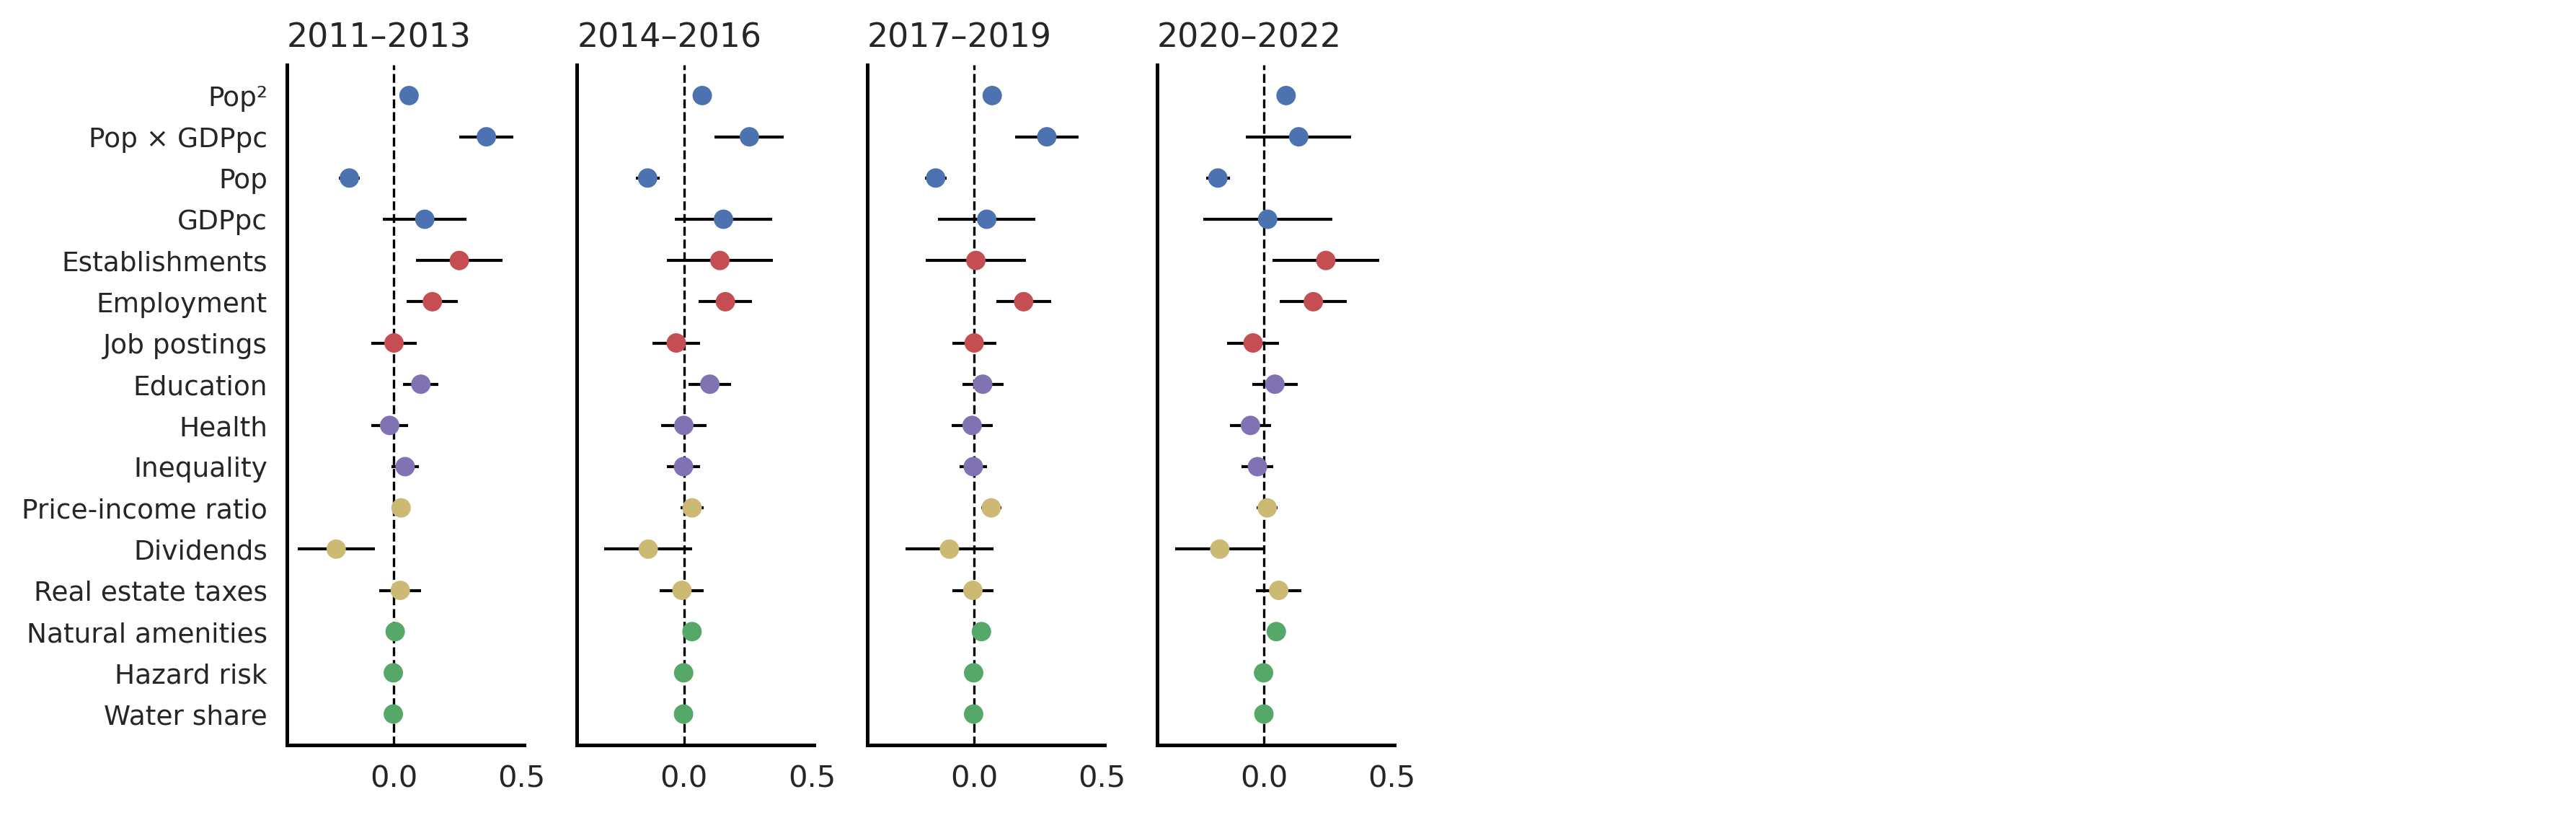

In [72]:
group_colors = {
    "Agglomeration size &\n economic power": "#4C72B0",
    "Geography": "#55A868",
    "Labour market\n structure": "#C44E52",
    "Human capital": "#8172B3",
    "Individual wealth": "#CCB974"
}

industries = coef_df_long["Industry"].unique()

fig, axes = plt.subplots(
    nrows=1,
    ncols=8,
    figsize=(12,4),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

for ax, industry in zip(axes, industries):

    sub = (
        coef_df_long[coef_df_long["Industry"] == industry]
        .set_index("Variable")
        .loc[var_order]
        .reset_index()
    )

    y = np.arange(len(sub))

    # confidence intervals
    ax.hlines(
        y=y,
        xmin=sub["ci_low"],
        xmax=sub["ci_high"],
        color="black",
        linewidth=1
    )

    # point estimates
    ax.scatter(
        sub["coef"],
        y,
        c=sub["Group"].map(group_colors),
        s=32,
        zorder=3
    )

    # zero line
    ax.axvline(0, color="black", linestyle="--", linewidth=0.8)

    ax.set_title(industry, fontsize=11, loc="left")
    ax.set_yticks(y)
    ax.set_yticklabels(sub["Variable_label"], fontsize=9)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(False)

# remove unused facets
for ax in axes[len(industries):]:
    ax.axis("off")

fig.supxlabel("")

plt.tight_layout()
plt.show()


In [73]:
def sig_to_level(sig):
    return {
        "***": 3,
        "**": 2,
        "*": 1,
        "+": 0.5,
        "": 0
    }.get(sig, 0)

coef_df_long["significance_level"] = coef_df_long["sig"].apply(sig_to_level)
coef_df_long["heat_value"] = (
    np.sign(coef_df_long["coef"]) *
    coef_df_long["significance_level"]
)


In [74]:
coef_std = (
    coef_df_long
    .groupby("Variable")["coef"]
    .transform(lambda x: x / x.std())
)

coef_df_long["coef_std"] = coef_std
coef_df_long["significant"] = coef_df_long["significance_level"] >= 0.5

coef_df_long["coef_std_masked"] = np.where(
    coef_df_long["significant"],
    coef_df_long["coef_std"],
    0.0
)

heat_df_sen = (
    coef_df_long
    .pivot(index="Variable",
           columns="Industry",
           values="coef_std_masked")
)

heat_df_sen = heat_df_sen.loc[var_order]

heat_df_sen.index = heat_df_sen.index.map(var_labels)

In [75]:
coef_df_long[coef_df_long['Variable']=='risk_centered']

,Industry,Variable,Variable_label,Group,coef,se,ci_low,ci_high,sig,significance_level,heat_value,coef_std,significant,coef_std_masked
5,2011–2013,risk_centered,Hazard risk,Geography,-0.001626,0.000784,-0.003162,-0.000090,*,1.0,-1.0,-2.991213,True,-2.991213
21,2014–2016,risk_centered,Hazard risk,Geography,-0.000721,0.000846,-0.002379,0.000938,,0.0,-0.0,-1.325714,False,0.000000
37,2017–2019,risk_centered,Hazard risk,Geography,-0.001166,0.000845,-0.002823,0.000490,,0.0,-0.0,-2.145694,False,0.000000
53,2020–2022,risk_centered,Hazard risk,Geography,-0.001968,0.000981,-0.003890,-0.000046,*,1.0,-1.0,-3.620698,True,-3.620698


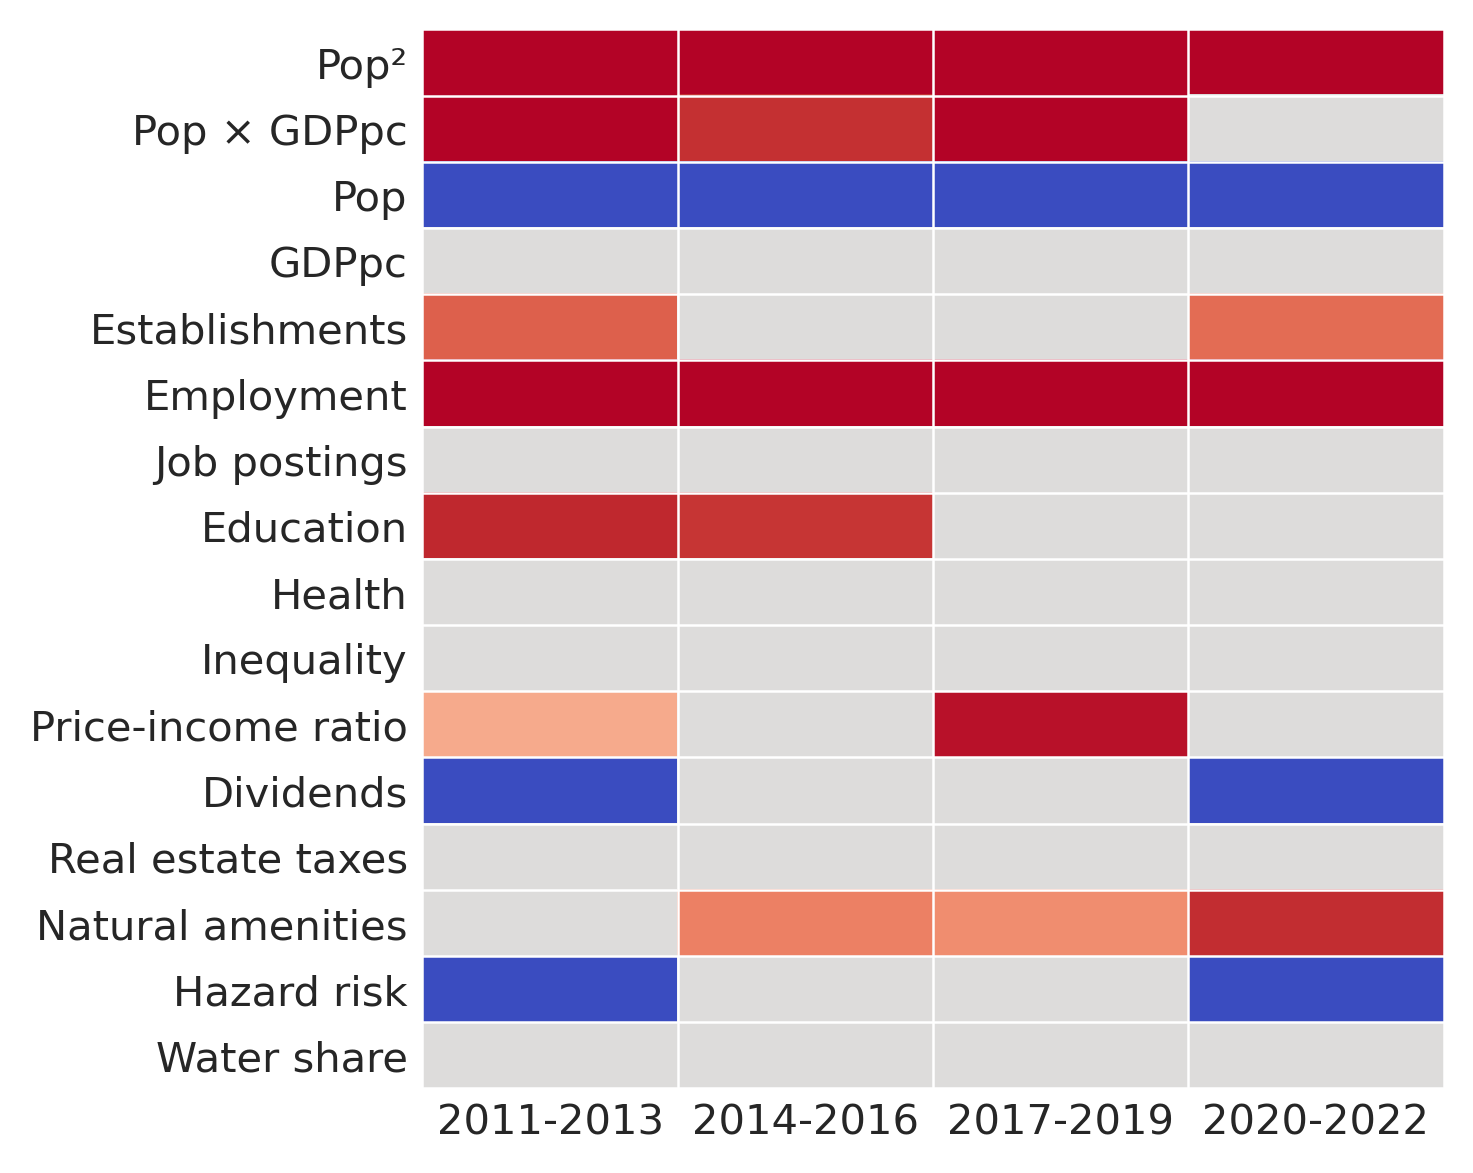

In [76]:
fig, ax = plt.subplots(figsize=(5, 4))

im = ax.imshow(
    heat_df_sen.values,
    cmap="coolwarm",
    vmin=-3,
    vmax=3,
    aspect="auto",
    alpha=1)

ax.invert_yaxis()
    
ax.set_xticks(np.arange(len(heat_df_sen.columns)))
ax.set_xticklabels(['2011-2013','2014-2016','2017-2019','2020-2022'], rotation=0, ha="center")

# # y labels on the right
# ax.yaxis.tick_right()
ax.set_yticks(np.arange(len(heat_df_sen.index)))
ax.set_yticklabels(heat_df_sen.index)

ax.tick_params(axis="y", which="both", length=0)
ax.tick_params(axis="x", which="both", length=0)

ax.set_xticks(np.arange(-0.5, len(heat_df_sen.columns), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(heat_df_sen.index), 1), minor=True)
ax.grid(which="minor", color="white", linestyle='-', linewidth=0.6)
ax.tick_params(which="minor", bottom=False, left=False)

# clean spines
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_xlabel("")
ax.set_ylabel("")

plt.tight_layout()

plt.savefig(
    '../fig/si/si_time_coef.pdf',
    bbox_inches='tight',
    dpi=300
)

plt.show()


### Different Seniority levels

In [77]:
nri_county=df = pd.read_parquet("../data_loaded/nri_counties.parquet")
counties = load_counties()


In [78]:
hits_exp = pd.read_parquet("../data_generated/network_metrics/cbsa2_seniority_hits_exp_1122.parquet")
hits_irs = pd.read_parquet("../data_generated/network_metrics/cbsa2_hits_irs_1122.parquet")

hits_merged=hits_irs.merge(hits_exp, left_on=['CBSA'], right_on=['CBSA'], how='inner', suffixes=('_irs', '_exp'))

cbsa = load_cbsa()


In [79]:
business = pd.read_csv("../data_loaded/cbp22co.zip", sep=',')

business["STCOFIPS"] = (
            business["fipstate"].astype(str).str.zfill(2)
            + business["fipscty"].astype(str).str.zfill(3))

business=business[business['naics'].isin(['51----','52----','53----','54----','55----','56----'])]

business=business.groupby('STCOFIPS').agg({'emp':'sum', 'est':'sum'}).reset_index()

In [80]:
hits_merged['pagerank_diff']=hits_merged['pagerank_exp']-hits_merged['pagerank_irs']

xwalk = cbsa[['STCOFIPS', 'CBSA Code', 'CBSA Title']].drop_duplicates()

counties = counties.merge(xwalk, on='STCOFIPS', how='left')
nri_county = nri_county.merge(xwalk, on='STCOFIPS', how='left')

counties_cbsa = (
    counties
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code', 'CBSA Title'], as_index=False)
    .agg(
        ALAND=('ALAND', 'sum'),
        AWATER=('AWATER', 'sum')
    )
)
counties_cbsa['water_perc'] = counties_cbsa['AWATER'] / (counties_cbsa['ALAND'] + counties_cbsa['AWATER']) * 100


def wmean(x, w):
    x = pd.to_numeric(x, errors='coerce')
    w = pd.to_numeric(w, errors='coerce')
    m = x.notna() & w.notna()
    if not m.any():
        return np.nan
    return np.average(x[m], weights=w[m])

hazards = [
    'RISK_SCORE', 'AVLN_RISKS', 'CFLD_RISKS', 'CWAV_RISKS', 'DRGT_RISKS',
    'ERQK_RISKS', 'HAIL_RISKS', 'HWAV_RISKS', 'HRCN_RISKS', 'ISTM_RISKS',
    'LNDS_RISKS', 'LTNG_RISKS', 'RFLD_RISKS', 'SWND_RISKS', 'TRND_RISKS',
    'TSUN_RISKS', 'VLCN_RISKS', 'WFIR_RISKS', 'WNTW_RISKS'
]

nri_county[hazards] = (
    nri_county[hazards]
    .replace(-9999, np.nan)
    .apply(pd.to_numeric, errors='coerce')
)


nri_cbsa = (
    nri_county
    .dropna(subset=['CBSA Code'])
    .assign(POPULATION=pd.to_numeric(nri_county['POPULATION'], errors='coerce'))
    .groupby(['CBSA Code', 'CBSA Title'], as_index=False)
    .agg(
        POPULATION=('POPULATION', 'sum'),
        **{h: (h, 'mean') for h in hazards}
    )
)

cbsa_agg = (
    counties_cbsa
    .merge(nri_cbsa, on=['CBSA Code', 'CBSA Title'], how='outer')
)

cbsa_agg['pop_density'] = cbsa_agg['POPULATION'] / cbsa_agg['ALAND'] * 1_000_000


hits_merged = hits_merged.merge(
    cbsa_agg,
    left_on=['CBSA'],
    right_on=['CBSA Code'],
    how='left',
    suffixes=('', '_cbsa')
)

In [81]:
## Job postings

jobposts=pd.read_csv('../data_loaded/jobpostings_aggregated/job_postings_county_month.csv')
jobposts_naics=pd.read_csv('../data_loaded/jobpostings_aggregated/job_postings_county_month_naics.csv')

jobposts_naics['year'] = jobposts_naics['month_year'].str[:4].astype(int)
jobposts_naics = jobposts_naics[jobposts_naics['year'].isin([2016, 2017, 2018,2019])].reset_index(drop=True)

jobposts_naics['STCOFIPS']=jobposts_naics['STCOFIPS'].astype(str)
jobposts_naics = jobposts_naics.merge(xwalk, on='STCOFIPS', how='left')

total_posts = (
    jobposts_naics
    .groupby(["CBSA Code"])
    .n_postings
    .sum()
    .reset_index()
    .rename(columns={"n_postings": "total_postings"})
)

target_posts = (
    jobposts_naics[jobposts_naics["NAICS_2"].isin([51, 52, 53, 54, 55, 56])]
    .groupby(["CBSA Code"])
    .n_postings
    .sum()
    .reset_index()
    .rename(columns={"n_postings": "target_postings"})
)

jobposts_share = (
    total_posts
    .merge(target_posts, on=["CBSA Code"], how="left")
)

jobposts_share["target_postings"] = jobposts_share["target_postings"].fillna(0)
jobposts_share["share_target_pct"] = (
    100 * jobposts_share["target_postings"] / jobposts_share["total_postings"]
)

jobposts_share['CBSA Code']=jobposts_share['CBSA Code'].astype(str)
jobposts_share["CBSA Code"]=jobposts_share["CBSA Code"].astype(str).str.zfill(5)

hits_merged=hits_merged.merge(jobposts_share, left_on='CBSA', right_on='CBSA Code', how='left')
hits_merged['target_postings'] = hits_merged['target_postings'].fillna(0)
hits_merged['n_postings_100k'] = hits_merged['target_postings']/hits_merged['POPULATION']*100_000

In [82]:
business = business.merge(xwalk, on='STCOFIPS', how='left')
business=business.groupby('CBSA Code').agg({'emp':'sum', 'est':'sum'}).reset_index()

hits_merged=hits_merged.merge(business, left_on='CBSA', right_on='CBSA Code', how='left')

hits_merged['emp_100k'] = hits_merged['emp']/hits_merged['POPULATION']*100_000
hits_merged['est_100k'] = hits_merged['est']/hits_merged['POPULATION']*100_000

In [83]:
# MY URBAN
pop_w = nri_county[['STCOFIPS', 'POPULATION']].copy()
pop_w['POPULATION'] = pd.to_numeric(pop_w['POPULATION'], errors='coerce')

urban=pd.read_parquet('../data_loaded/data_final/urban_afford.parquet')
urban['STCOFIPS'] = urban['STCOFIPS'].astype(str)

urban_cbsa_in = (
    urban[['STCOFIPS','nat_amenity_score','urbanism','real_estate_taxes_med',
           'med_home_price2017','income_price_ratio2023','inequality_ratio']]
    .merge(pop_w, on='STCOFIPS', how='left')
    .merge(xwalk, on='STCOFIPS', how='left')
)

urbanism_dict = {
    "6 - Noncore": 1,
    "5 - Micropolitan": 2,
    "4 - Small metro": 3,
    "3 - Medium metro": 4,
    "2 - Large fringe metro": 5,
    "1 - Large central metro": 6
}

urban_cbsa_in["urbanism"] = urban_cbsa_in["urbanism"].map(urbanism_dict)


urban_cbsa = (
    urban_cbsa_in
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code', 'CBSA Title'], as_index=False)
    .apply(lambda g: pd.Series({
        'nat_amenity_score': wmean(g['nat_amenity_score'], g['POPULATION']),
        'real_estate_taxes_med': wmean(g['real_estate_taxes_med'], g['POPULATION']),
        'med_home_price2017': wmean(g['med_home_price2017'], g['POPULATION']),
        'income_price_ratio2023': wmean(g['income_price_ratio2023'], g['POPULATION']),
        'inequality_ratio': wmean(g['inequality_ratio'], g['POPULATION']),

        'urbanism_pwmean': wmean(g['urbanism'], g['POPULATION'])
    }))
    .reset_index(drop=True)
)

urban_r = urban_cbsa.set_index('CBSA Code').drop(columns=['CBSA Title'], errors='ignore')

hits_merged = hits_merged.join(urban_r, on='CBSA')

In [84]:
## MY HDI

education_calulated=pd.read_parquet('../data_loaded/data_final/education_combined.parquet')
health_calulated=pd.read_parquet('../data_loaded/data_final/health_combined.parquet')
income_calulated=pd.read_parquet('../data_loaded/data_final/median_income_combined.parquet')

health_calulated=health_calulated[health_calulated['year']==2020][['STCOFIPS', 'health_index', 'health_index_adj']]
income_calulated=income_calulated[income_calulated['year']==2020][['STCOFIPS', 'income_index', 'income_index_adj']]

## MY INCOME
income_combined=pd.read_parquet('../data_loaded/data_final/income_combined.parquet')
income_combined=income_combined[income_combined['year']==2019].reset_index(drop=True)

income_combined = income_combined.pivot_table(
    index=["STCOFIPS"],    
    columns="Description",  
    values="value",        
    aggfunc="first"
).reset_index()

income_combined.columns.name = None

income_combined['gdp_pc']=income_combined['real_gdp_chained_2017']/income_combined['population']
income_combined['dividends_pc']=income_combined['dividends']/income_combined['population']

income_combined=income_combined[['STCOFIPS', 'personal_income_pc', 'poverty_rate_all', 'gdp_pc', 'dividends_pc', 'dividends']]

In [85]:
pop_w = nri_county[['STCOFIPS', 'POPULATION']].copy()
pop_w['POPULATION'] = pd.to_numeric(pop_w['POPULATION'], errors='coerce')

education_cbsa = (
    education_calulated
    .merge(pop_w, on='STCOFIPS', how='left')
    .merge(xwalk, on='STCOFIPS', how='left')
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code'], as_index=False)
    .apply(lambda g: pd.Series({
        'education_index': wmean(g['education_index'], g['POPULATION'])
    }))
    .reset_index(drop=True)
)

health_cbsa = (
    health_calulated
    .merge(pop_w, on='STCOFIPS', how='left')
    .merge(xwalk, on='STCOFIPS', how='left')
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code'], as_index=False)
    .apply(lambda g: pd.Series({
        'health_index_adj': wmean(g['health_index_adj'], g['POPULATION'])
    }))
    .reset_index(drop=True)
)

income_cbsa = (
    income_calulated
    .merge(pop_w, on='STCOFIPS', how='left')
    .merge(xwalk, on='STCOFIPS', how='left')
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code'], as_index=False)
    .apply(lambda g: pd.Series({
        'income_index_adj': wmean(g['income_index_adj'], g['POPULATION'])
    }))
    .reset_index(drop=True)
)

combined_income_cbsa = (
    income_combined
    .merge(pop_w, on='STCOFIPS', how='left')
    .merge(xwalk, on='STCOFIPS', how='left')
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code'], as_index=False)
    .apply(lambda g: pd.Series({
        'personal_income_pc': wmean(g['personal_income_pc'], g['POPULATION']),
        'poverty_rate_all': wmean(g['poverty_rate_all'], g['POPULATION']),
        'gdp_pc': wmean(g['gdp_pc'], g['POPULATION']),
        'dividends_pc': wmean(g['dividends_pc'], g['POPULATION']),
        'dividends': pd.to_numeric(g['dividends'], errors='coerce').sum(skipna=True),
        'POPULATION_sum': g['POPULATION'].sum(skipna=True)
    }))
    .reset_index(drop=True)
)



In [86]:
hits_merged['CBSA'] = hits_merged['CBSA'].astype(str)

for df in [education_cbsa, health_cbsa, income_cbsa, combined_income_cbsa]:
    df['CBSA Code'] = df['CBSA Code'].astype(str)

education_r = education_cbsa.set_index('CBSA Code').drop(columns=['CBSA Title'], errors='ignore')
health_r    = health_cbsa.set_index('CBSA Code').drop(columns=['CBSA Title'], errors='ignore')
income_r    = income_cbsa.set_index('CBSA Code').drop(columns=['CBSA Title'], errors='ignore')
cincome_r   = combined_income_cbsa.set_index('CBSA Code').drop(columns=['CBSA Title'], errors='ignore')

hits_merged = (
    hits_merged
    .join(education_r, on='CBSA')
    .join(health_r, on='CBSA')
    .join(income_r, on='CBSA')
    .join(cincome_r, on='CBSA')
)


In [87]:
# log transforms (avoid −inf)
for col in ["pagerank_irs", "pagerank_exp"]:
    hits_merged[f"log_{col}"] = (hits_merged[col] + 1e-12).apply(np.log) # there are no zeroes

for col in ['POPULATION', 'target_postings', 'n_postings_100k', 'emp_100k', 'est_100k', 
            'personal_income_pc', 'gdp_pc', 'dividends_pc', 'pop_density',
            'real_estate_taxes_med', 'med_home_price2017']:
    hits_merged[f"log_{col}"] = (hits_merged[col]).apply(np.log1p)

hits_merged['pagerank_logdiff']=hits_merged['log_pagerank_exp']-hits_merged['log_pagerank_irs']

In [88]:
df = hits_merged.copy()
na_counts = df.isna().sum()
print(na_counts[na_counts > 0])

AVLN_RISKS                1688
CFLD_RISKS                1483
HRCN_RISKS                 526
ISTM_RISKS                 170
LNDS_RISKS                   8
LTNG_RISKS                  17
TSUN_RISKS                1809
VLCN_RISKS                1809
CBSA Code_y                230
total_postings             230
share_target_pct           230
nat_amenity_score           17
med_home_price2017          13
income_price_ratio2023      13
personal_income_pc          12
gdp_pc                      12
dividends_pc                12
log_personal_income_pc      12
log_gdp_pc                  12
log_dividends_pc            12
log_med_home_price2017      13
dtype: int64


In [89]:
df['log_pop_centered'] = df['log_POPULATION'] - df['log_POPULATION'].mean()
df['log_n_postings_centered'] = df['log_n_postings_100k'] - df['log_n_postings_100k'].mean()
df['log_gdp_centered'] = df['log_gdp_pc'] - df['log_gdp_pc'].mean()
df['education_centered'] = df['education_index'] - df['education_index'].mean()
df['income_centered'] = df['income_index_adj'] - df['income_index_adj'].mean()
df['health_centered'] = df['health_index_adj'] - df['health_index_adj'].mean()
df['risk_centered'] = df['RISK_SCORE'] - df['RISK_SCORE'].mean()
df['poverty_rate_centered'] = df['poverty_rate_all'] - df['poverty_rate_all'].mean()
df['nat_amenity_centered'] = df['nat_amenity_score'] - df['nat_amenity_score'].mean()
df['log_taxes_med_centered'] = df['log_real_estate_taxes_med'] - df['log_real_estate_taxes_med'].mean()
df['income_price_ratio2023_centered'] = df['income_price_ratio2023'] - df['income_price_ratio2023'].mean()
df['log_personal_income_centered'] = df['log_personal_income_pc'] - df['log_personal_income_pc'].mean()
df['log_est_100k_centered'] = df['log_est_100k'] - df['log_est_100k'].mean()
df['log_emp_100k_centered'] = df['log_emp_100k'] - df['log_emp_100k'].mean()
df['water_perc_centered'] = df['water_perc'] - df['water_perc'].mean()
df['log_pop_density_centered'] = df['log_pop_density'] - df['log_pop_density'].mean()
df['log_dividends_centered'] = df['log_dividends_pc'] - df['log_dividends_pc'].mean()
df['inequality_centered'] = df['inequality_ratio'] - df['inequality_ratio'].mean()

In [90]:
socs2 = [
    'Early-career',
    'Mid-career',
    'Senior leadership'
]

models_socs2 = {}

In [91]:
# ======================================================
# SIGNIFICANCE STAR FUNCTION
# ======================================================
def significance_stars(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    elif p < 0.1:
        return "+"
    else:
        return ""


# ======================================================
# MAIN LOOP: RUN ALL HAZARD MODELS AND BUILD ONE DATAFRAME
# ======================================================

models_full = {}
all_results = []

for field in socs2:

    # Filter dataset
    sub = df[df['seniority']==field].copy()

    vars_in_formula = [
        f"risk_centered", "pagerank_logdiff", 'log_pop_centered', 'log_gdp_centered', "log_personal_income_centered", "log_taxes_med_centered", "log_dividends_centered", "income_price_ratio2023_centered",
        "log_est_100k_centered", "log_emp_100k_centered", "log_n_postings_centered", "education_centered", "income_centered", "health_centered", "inequality_centered",
        "nat_amenity_centered", "water_perc_centered"
    ]
    
    sub_clean = sub.dropna(subset=vars_in_formula)

    formula = (
            "pagerank_logdiff ~ risk_centered + log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
            "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered"
            "+ education_centered + health_centered + inequality_centered"
            "+ nat_amenity_centered + water_perc_centered"
    )

    try:
        model = smf.ols(
            formula=formula,
            data=sub_clean
        ).fit(cov_type='HC3')
    except Exception as e:
        print(f"Skipping {field}: {e}")
        continue

    models_full[field] = model

In [92]:
df_table_full=pd.DataFrame()

for col in socs2:

    res = summary_col(
        [models_full[col]],
        stars=False,
        model_names=[col],
        info_dict={
            "N": lambda x: f"{int(x.nobs)}",
            "BIC": lambda x: f"{x.bic:.0f}"}
    )

    # df_index=df_table.index
    
    df_table = res.tables[0]
    
    model = models_full[col]
    
    for row in df_table.index:
        cell = df_table.loc[row, col]
    
        try:
            coef = float(cell.split()[0])
        except:
            continue
        
        pval = model.pvalues.get(row, 1.0)
        star = make_stars(pval)
        
        df_table.loc[row, col] = f"{coef:.3f}{star}"

    df_table_full=pd.concat([df_table_full, df_table], axis=1)

In [93]:
df_table_full

,Early-career,Mid-career,Senior leadership
Intercept,-0.444***,-0.693***,-0.424***
,(0.0216),(0.0202),(0.0227)
risk_centered,-0.003**,-0.002*,-0.002*
,(0.0011),(0.0007),(0.0010)
log_pop_centered,-0.263***,-0.128***,-0.237***
,(0.0237),(0.0181),(0.0230)
log_gdp_centered,0.178,0.163+,-0.037
,(0.1143),(0.0929),(0.1115)
log_pop_centered:log_gdp_centered,0.518***,0.393***,0.380***
,(0.0680),(0.0513),(0.0594)


In [94]:
group_map = {
    "Agglomeration": [
        "log_pop_centered",
        "log_gdp_centered",
        "log_pop_centered:log_gdp_centered",
        "I(log_pop_centered ** 2)"
    ],
    "Individual wealth": [
        "log_taxes_med_centered",
        "log_dividends_centered",
        "income_price_ratio2023_centered"
    ],
    "Labour market": [
        "log_est_100k_centered",
        "log_emp_100k_centered",
        "log_n_postings_centered"
    ],
    "Human capital": [
        "education_centered",
        "health_centered",
        "inequality_centered"
    ],
    "Geography": [
        "nat_amenity_centered",
        "water_perc_centered",
        "risk_centered"
    ]
}

group_order = list(group_map.keys())


In [95]:
var_order = [
     'water_perc_centered',
     'risk_centered',
     'nat_amenity_centered',
     'log_taxes_med_centered',
     'log_dividends_centered',
     'income_price_ratio2023_centered',
     'inequality_centered',
     'health_centered',
     'education_centered',
     'log_n_postings_centered',
     'log_emp_100k_centered',
     'log_est_100k_centered',
     'log_gdp_centered',
     'log_pop_centered',
     'log_pop_centered:log_gdp_centered',
     'I(log_pop_centered ** 2)'
]

var_labels = {
    "I(log_pop_centered ** 2)": "Pop²",
    "log_pop_centered:log_gdp_centered": "Pop × GDPpc",
    "log_pop_centered": "Pop",
    "log_gdp_centered": "GDPpc",
    "log_est_100k_centered": "Establishments",
    "log_emp_100k_centered": "Employment",
    "log_n_postings_centered": "Job postings",
    "education_centered": "Education",
    "health_centered": "Health",
    "inequality_centered": "Inequality",
    "income_price_ratio2023_centered": "Price-income ratio",
    "log_dividends_centered": "Dividends",
    "log_taxes_med_centered": "Real estate taxes",
    "nat_amenity_centered": "Natural amenities",
    "risk_centered": "Hazard risk",
    "water_perc_centered": "Water share",
}

var_to_group = {
    "log_pop_centered": "Agglomeration size &\n economic power",
    "log_gdp_centered": "Agglomeration size &\n economic power",
    "log_pop_centered:log_gdp_centered": "Agglomeration size &\n economic power",
    "I(log_pop_centered ** 2)": "Agglomeration size &\n economic power",

    "log_taxes_med_centered": "Individual wealth",
    "log_dividends_centered": "Individual wealth",
    "income_price_ratio2023_centered": "Individual wealth",

    "log_est_100k_centered": "Labour market\n structure",
    "log_emp_100k_centered": "Labour market\n structure",
    "log_n_postings_centered": "Labour market\n structure",

    "education_centered": "Human capital",
    "health_centered": "Human capital",
    "inequality_centered": "Human capital",

    "nat_amenity_centered": "Geography",
    "water_perc_centered": "Geography",
    "log_pop_density_centered": "Geography",
    "risk_centered": "Geography"
}

def significance_stars(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    elif p < 0.1:
        return "+"
    else:
        return ""



In [96]:
records = []

for industry, model in models_full.items():

    params = model.params
    ses    = model.bse
    pvals  = model.pvalues

    for var in var_labels.keys():

        if var not in params.index:
            continue

        coef = params[var]
        se   = ses[var]
        pval = pvals[var]

        records.append({
            "Industry": industry,
            "Variable": var,
            "Variable_label": var_labels[var],
            "Group": var_to_group[var],
            "coef": coef,
            "se": se,
            "ci_low": coef - 1.96 * se,
            "ci_high": coef + 1.96 * se,
            "sig": significance_stars(pval)
        })


In [97]:
coef_df_long = pd.DataFrame(records)

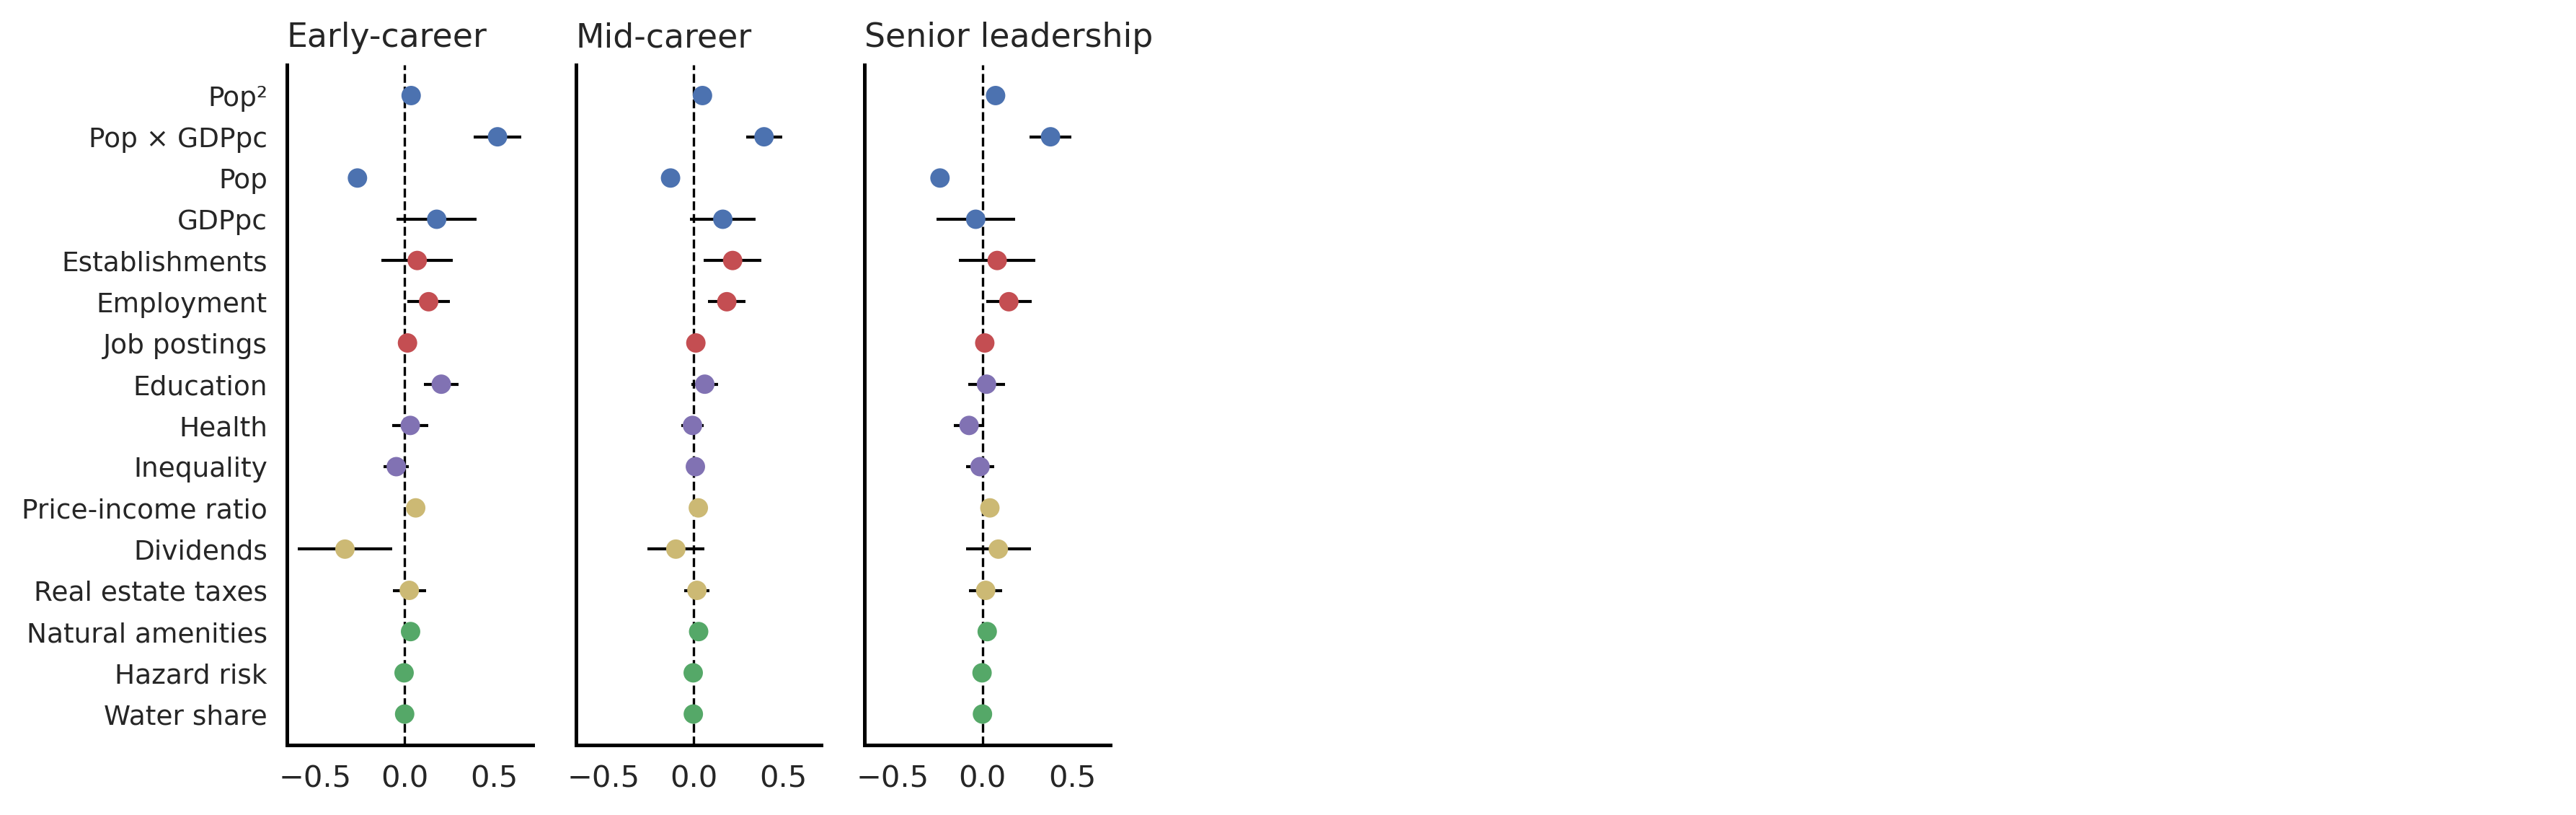

In [98]:
group_colors = {
    "Agglomeration size &\n economic power": "#4C72B0",
    "Geography": "#55A868",
    "Labour market\n structure": "#C44E52",
    "Human capital": "#8172B3",
    "Individual wealth": "#CCB974"
}

industries = coef_df_long["Industry"].unique()

fig, axes = plt.subplots(
    nrows=1,
    ncols=8,
    figsize=(12,4),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

for ax, industry in zip(axes, industries):

    sub = (
        coef_df_long[coef_df_long["Industry"] == industry]
        .set_index("Variable")
        .loc[var_order]
        .reset_index()
    )

    y = np.arange(len(sub))

    # confidence intervals
    ax.hlines(
        y=y,
        xmin=sub["ci_low"],
        xmax=sub["ci_high"],
        color="black",
        linewidth=1
    )

    # point estimates
    ax.scatter(
        sub["coef"],
        y,
        c=sub["Group"].map(group_colors),
        s=32,
        zorder=3
    )

    # zero line
    ax.axvline(0, color="black", linestyle="--", linewidth=0.8)

    ax.set_title(industry, fontsize=11, loc="left")
    ax.set_yticks(y)
    ax.set_yticklabels(sub["Variable_label"], fontsize=9)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(False)

# remove unused facets
for ax in axes[len(industries):]:
    ax.axis("off")

fig.supxlabel("")

plt.tight_layout()
plt.show()


In [99]:
def sig_to_level(sig):
    return {
        "***": 3,
        "**": 2,
        "*": 1,
        "+": 0.5,
        "": 0
    }.get(sig, 0)

coef_df_long["significance_level"] = coef_df_long["sig"].apply(sig_to_level)
coef_df_long["heat_value"] = (
    np.sign(coef_df_long["coef"]) *
    coef_df_long["significance_level"]
)


In [100]:
coef_std = (
    coef_df_long
    .groupby("Variable")["coef"]
    .transform(lambda x: x / x.std())
)

coef_df_long["coef_std"] = coef_std
coef_df_long["significant"] = coef_df_long["significance_level"] >= 0.5

coef_df_long["coef_std_masked"] = np.where(
    coef_df_long["significant"],
    coef_df_long["coef_std"],
    0.0
)

heat_df_sen = (
    coef_df_long
    .pivot(index="Variable",
           columns="Industry",
           values="coef_std_masked")
)

heat_df_sen = heat_df_sen.loc[var_order]

heat_df_sen.index = heat_df_sen.index.map(var_labels)

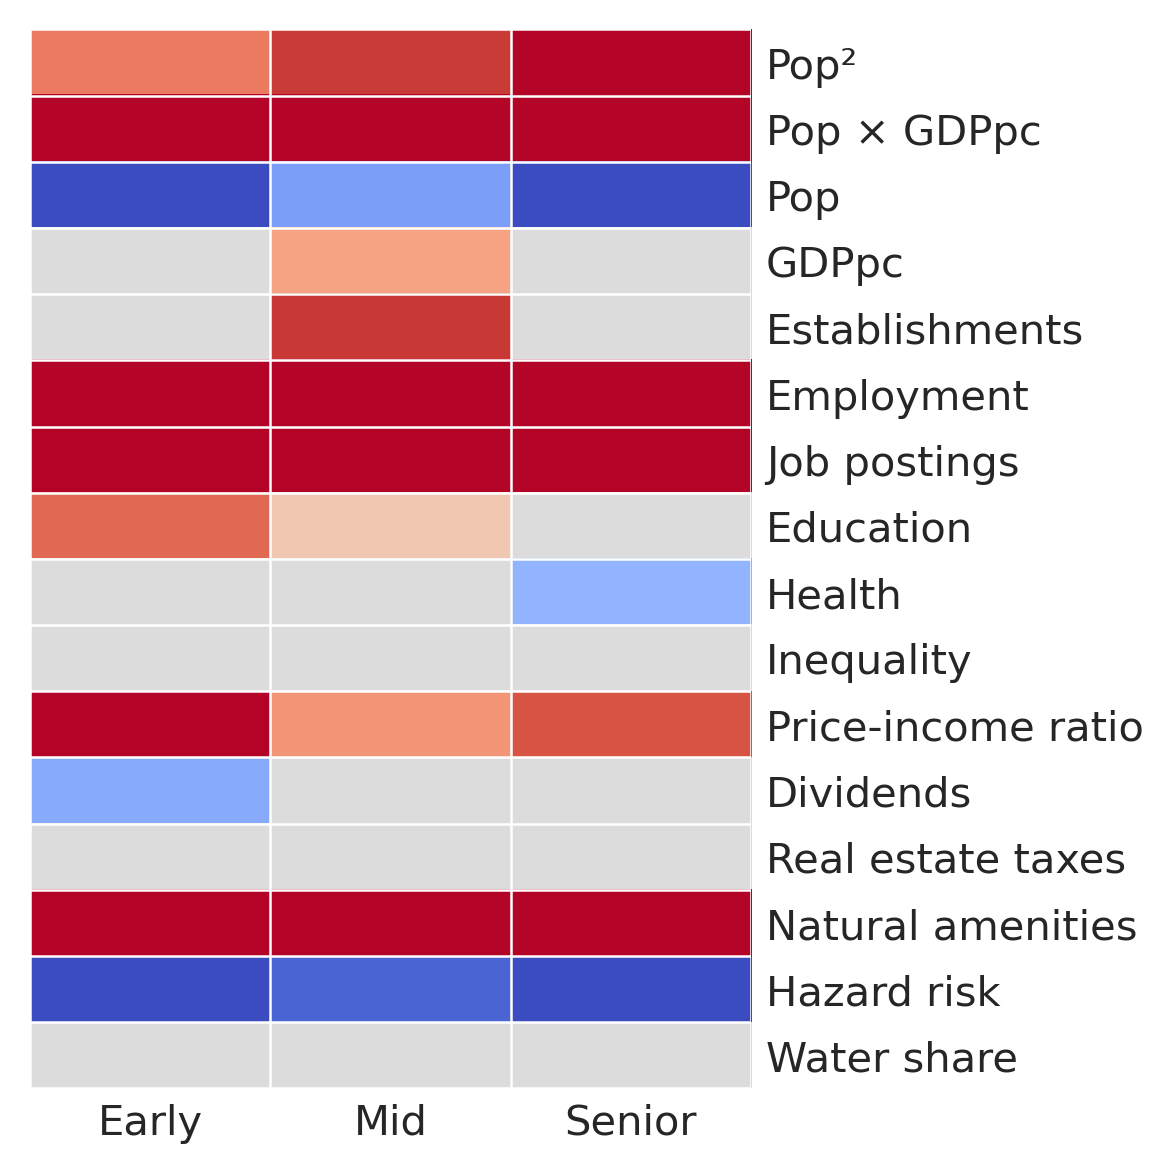

In [101]:
fig, ax = plt.subplots(figsize=(4, 4))

im = ax.imshow(
    heat_df_sen.values,
    cmap="coolwarm",
    vmin=-3,
    vmax=3,
    aspect="auto",
    alpha=1)

ax.invert_yaxis()
    
ax.set_xticks(np.arange(len(heat_df_sen.columns)))
ax.set_xticklabels(['Early','Mid','Senior'], rotation=0, ha="center")

# y labels on the right
ax.yaxis.tick_right()
ax.set_yticks(np.arange(len(heat_df_sen.index)))
ax.set_yticklabels(heat_df_sen.index)

ax.tick_params(axis="y", which="both", length=0)
ax.tick_params(axis="x", which="both", length=0)

ax.set_xticks(np.arange(-0.5, len(heat_df_sen.columns), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(heat_df_sen.index), 1), minor=True)
ax.grid(which="minor", color="white", linestyle='-', linewidth=0.6)
ax.tick_params(which="minor", bottom=False, left=False)

# clean spines
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_xlabel("")
ax.set_ylabel("")

plt.tight_layout()
plt.show()


### Different Industries

In [102]:
nri_county=df = pd.read_parquet("../data_loaded/nri_counties.parquet")
counties = load_counties()


In [103]:
hits_exp = pd.read_parquet("../data_generated/network_metrics/cbsa2_soc2_hits_exp_1122.parquet")
hits_irs = pd.read_parquet("../data_generated/network_metrics/cbsa2_hits_irs_1122.parquet")

hits_merged=hits_irs.merge(hits_exp, left_on=['CBSA'], right_on=['CBSA'], how='inner', suffixes=('_irs', '_exp'))

cbsa = load_cbsa()


In [104]:
business = pd.read_csv("../data_loaded/cbp22co.zip", sep=',')

business["STCOFIPS"] = (
            business["fipstate"].astype(str).str.zfill(2)
            + business["fipscty"].astype(str).str.zfill(3))

business=business[business['naics'].isin(['51----','52----','53----','54----','55----','56----'])]

business=business.groupby('STCOFIPS').agg({'emp':'sum', 'est':'sum'}).reset_index()

In [105]:
hits_merged['pagerank_diff']=hits_merged['pagerank_exp']-hits_merged['pagerank_irs']

xwalk = cbsa[['STCOFIPS', 'CBSA Code', 'CBSA Title']].drop_duplicates()

counties = counties.merge(xwalk, on='STCOFIPS', how='left')
nri_county = nri_county.merge(xwalk, on='STCOFIPS', how='left')

counties_cbsa = (
    counties
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code', 'CBSA Title'], as_index=False)
    .agg(
        ALAND=('ALAND', 'sum'),
        AWATER=('AWATER', 'sum')
    )
)
counties_cbsa['water_perc'] = counties_cbsa['AWATER'] / (counties_cbsa['ALAND'] + counties_cbsa['AWATER']) * 100


def wmean(x, w):
    x = pd.to_numeric(x, errors='coerce')
    w = pd.to_numeric(w, errors='coerce')
    m = x.notna() & w.notna()
    if not m.any():
        return np.nan
    return np.average(x[m], weights=w[m])

hazards = [
    'RISK_SCORE', 'AVLN_RISKS', 'CFLD_RISKS', 'CWAV_RISKS', 'DRGT_RISKS',
    'ERQK_RISKS', 'HAIL_RISKS', 'HWAV_RISKS', 'HRCN_RISKS', 'ISTM_RISKS',
    'LNDS_RISKS', 'LTNG_RISKS', 'RFLD_RISKS', 'SWND_RISKS', 'TRND_RISKS',
    'TSUN_RISKS', 'VLCN_RISKS', 'WFIR_RISKS', 'WNTW_RISKS'
]

nri_county[hazards] = (
    nri_county[hazards]
    .replace(-9999, np.nan)
    .apply(pd.to_numeric, errors='coerce')
)


nri_cbsa = (
    nri_county
    .dropna(subset=['CBSA Code'])
    .assign(POPULATION=pd.to_numeric(nri_county['POPULATION'], errors='coerce'))
    .groupby(['CBSA Code', 'CBSA Title'], as_index=False)
    .agg(
        POPULATION=('POPULATION', 'sum'),
        **{h: (h, 'mean') for h in hazards}
    )
)

cbsa_agg = (
    counties_cbsa
    .merge(nri_cbsa, on=['CBSA Code', 'CBSA Title'], how='outer')
)

cbsa_agg['pop_density'] = cbsa_agg['POPULATION'] / cbsa_agg['ALAND'] * 1_000_000


hits_merged = hits_merged.merge(
    cbsa_agg,
    left_on=['CBSA'],
    right_on=['CBSA Code'],
    how='left',
    suffixes=('', '_cbsa')
)

In [106]:
## Job postings

jobposts=pd.read_csv('../data_loaded/jobpostings_aggregated/job_postings_county_month.csv')
jobposts_naics=pd.read_csv('../data_loaded/jobpostings_aggregated/job_postings_county_month_naics.csv')

jobposts_naics['year'] = jobposts_naics['month_year'].str[:4].astype(int)
jobposts_naics = jobposts_naics[jobposts_naics['year'].isin([2016, 2017, 2018,2019])].reset_index(drop=True)

jobposts_naics['STCOFIPS']=jobposts_naics['STCOFIPS'].astype(str)
jobposts_naics = jobposts_naics.merge(xwalk, on='STCOFIPS', how='left')

total_posts = (
    jobposts_naics
    .groupby(["CBSA Code"])
    .n_postings
    .sum()
    .reset_index()
    .rename(columns={"n_postings": "total_postings"})
)

target_posts = (
    jobposts_naics[jobposts_naics["NAICS_2"].isin([51, 52, 53, 54, 55, 56])]
    .groupby(["CBSA Code"])
    .n_postings
    .sum()
    .reset_index()
    .rename(columns={"n_postings": "target_postings"})
)

jobposts_share = (
    total_posts
    .merge(target_posts, on=["CBSA Code"], how="left")
)

jobposts_share["target_postings"] = jobposts_share["target_postings"].fillna(0)
jobposts_share["share_target_pct"] = (
    100 * jobposts_share["target_postings"] / jobposts_share["total_postings"]
)

jobposts_share['CBSA Code']=jobposts_share['CBSA Code'].astype(str)
jobposts_share["CBSA Code"]=jobposts_share["CBSA Code"].astype(str).str.zfill(5)

hits_merged=hits_merged.merge(jobposts_share, left_on='CBSA', right_on='CBSA Code', how='left')
hits_merged['target_postings'] = hits_merged['target_postings'].fillna(0)
hits_merged['n_postings_100k'] = hits_merged['target_postings']/hits_merged['POPULATION']*100_000

In [107]:
business = business.merge(xwalk, on='STCOFIPS', how='left')
business=business.groupby('CBSA Code').agg({'emp':'sum', 'est':'sum'}).reset_index()

hits_merged=hits_merged.merge(business, left_on='CBSA', right_on='CBSA Code', how='left')

hits_merged['emp_100k'] = hits_merged['emp']/hits_merged['POPULATION']*100_000
hits_merged['est_100k'] = hits_merged['est']/hits_merged['POPULATION']*100_000

In [108]:
# MY URBAN
pop_w = nri_county[['STCOFIPS', 'POPULATION']].copy()
pop_w['POPULATION'] = pd.to_numeric(pop_w['POPULATION'], errors='coerce')

urban=pd.read_parquet('../data_loaded/data_final/urban_afford.parquet')
urban['STCOFIPS'] = urban['STCOFIPS'].astype(str)

urban_cbsa_in = (
    urban[['STCOFIPS','nat_amenity_score','urbanism','real_estate_taxes_med',
           'med_home_price2017','income_price_ratio2023','inequality_ratio']]
    .merge(pop_w, on='STCOFIPS', how='left')
    .merge(xwalk, on='STCOFIPS', how='left')
)

urbanism_dict = {
    "6 - Noncore": 1,
    "5 - Micropolitan": 2,
    "4 - Small metro": 3,
    "3 - Medium metro": 4,
    "2 - Large fringe metro": 5,
    "1 - Large central metro": 6
}

urban_cbsa_in["urbanism"] = urban_cbsa_in["urbanism"].map(urbanism_dict)


urban_cbsa = (
    urban_cbsa_in
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code', 'CBSA Title'], as_index=False)
    .apply(lambda g: pd.Series({
        'nat_amenity_score': wmean(g['nat_amenity_score'], g['POPULATION']),
        'real_estate_taxes_med': wmean(g['real_estate_taxes_med'], g['POPULATION']),
        'med_home_price2017': wmean(g['med_home_price2017'], g['POPULATION']),
        'income_price_ratio2023': wmean(g['income_price_ratio2023'], g['POPULATION']),
        'inequality_ratio': wmean(g['inequality_ratio'], g['POPULATION']),

        'urbanism_pwmean': wmean(g['urbanism'], g['POPULATION'])
    }))
    .reset_index(drop=True)
)

urban_r = urban_cbsa.set_index('CBSA Code').drop(columns=['CBSA Title'], errors='ignore')

hits_merged = hits_merged.join(urban_r, on='CBSA')

In [109]:
## MY HDI

education_calulated=pd.read_parquet('../data_loaded/data_final/education_combined.parquet')
health_calulated=pd.read_parquet('../data_loaded/data_final/health_combined.parquet')
income_calulated=pd.read_parquet('../data_loaded/data_final/median_income_combined.parquet')

health_calulated=health_calulated[health_calulated['year']==2020][['STCOFIPS', 'health_index', 'health_index_adj']]
income_calulated=income_calulated[income_calulated['year']==2020][['STCOFIPS', 'income_index', 'income_index_adj']]

## MY INCOME
income_combined=pd.read_parquet('../data_loaded/data_final/income_combined.parquet')
income_combined=income_combined[income_combined['year']==2019].reset_index(drop=True)

income_combined = income_combined.pivot_table(
    index=["STCOFIPS"],    
    columns="Description",  
    values="value",        
    aggfunc="first"
).reset_index()

income_combined.columns.name = None

income_combined['gdp_pc']=income_combined['real_gdp_chained_2017']/income_combined['population']
income_combined['dividends_pc']=income_combined['dividends']/income_combined['population']

income_combined=income_combined[['STCOFIPS', 'personal_income_pc', 'poverty_rate_all', 'gdp_pc', 'dividends_pc', 'dividends']]

In [110]:
pop_w = nri_county[['STCOFIPS', 'POPULATION']].copy()
pop_w['POPULATION'] = pd.to_numeric(pop_w['POPULATION'], errors='coerce')

education_cbsa = (
    education_calulated
    .merge(pop_w, on='STCOFIPS', how='left')
    .merge(xwalk, on='STCOFIPS', how='left')
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code'], as_index=False)
    .apply(lambda g: pd.Series({
        'education_index': wmean(g['education_index'], g['POPULATION'])
    }))
    .reset_index(drop=True)
)

health_cbsa = (
    health_calulated
    .merge(pop_w, on='STCOFIPS', how='left')
    .merge(xwalk, on='STCOFIPS', how='left')
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code'], as_index=False)
    .apply(lambda g: pd.Series({
        'health_index_adj': wmean(g['health_index_adj'], g['POPULATION'])
    }))
    .reset_index(drop=True)
)

income_cbsa = (
    income_calulated
    .merge(pop_w, on='STCOFIPS', how='left')
    .merge(xwalk, on='STCOFIPS', how='left')
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code'], as_index=False)
    .apply(lambda g: pd.Series({
        'income_index_adj': wmean(g['income_index_adj'], g['POPULATION'])
    }))
    .reset_index(drop=True)
)

combined_income_cbsa = (
    income_combined
    .merge(pop_w, on='STCOFIPS', how='left')
    .merge(xwalk, on='STCOFIPS', how='left')
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code'], as_index=False)
    .apply(lambda g: pd.Series({
        'personal_income_pc': wmean(g['personal_income_pc'], g['POPULATION']),
        'poverty_rate_all': wmean(g['poverty_rate_all'], g['POPULATION']),
        'gdp_pc': wmean(g['gdp_pc'], g['POPULATION']),
        'dividends_pc': wmean(g['dividends_pc'], g['POPULATION']),
        'dividends': pd.to_numeric(g['dividends'], errors='coerce').sum(skipna=True),
        'POPULATION_sum': g['POPULATION'].sum(skipna=True)
    }))
    .reset_index(drop=True)
)



In [111]:
hits_merged['CBSA'] = hits_merged['CBSA'].astype(str)

for df in [education_cbsa, health_cbsa, income_cbsa, combined_income_cbsa]:
    df['CBSA Code'] = df['CBSA Code'].astype(str)

education_r = education_cbsa.set_index('CBSA Code').drop(columns=['CBSA Title'], errors='ignore')
health_r    = health_cbsa.set_index('CBSA Code').drop(columns=['CBSA Title'], errors='ignore')
income_r    = income_cbsa.set_index('CBSA Code').drop(columns=['CBSA Title'], errors='ignore')
cincome_r   = combined_income_cbsa.set_index('CBSA Code').drop(columns=['CBSA Title'], errors='ignore')

hits_merged = (
    hits_merged
    .join(education_r, on='CBSA')
    .join(health_r, on='CBSA')
    .join(income_r, on='CBSA')
    .join(cincome_r, on='CBSA')
)


In [112]:
# log transforms (avoid −inf)
for col in ["pagerank_irs", "pagerank_exp"]:
    hits_merged[f"log_{col}"] = (hits_merged[col] + 1e-12).apply(np.log) # there are no zeroes

for col in ['POPULATION', 'target_postings', 'n_postings_100k', 'emp_100k', 'est_100k', 
            'personal_income_pc', 'gdp_pc', 'dividends_pc', 'pop_density',
            'real_estate_taxes_med', 'med_home_price2017']:
    hits_merged[f"log_{col}"] = (hits_merged[col]).apply(np.log1p)

hits_merged['pagerank_logdiff']=hits_merged['log_pagerank_exp']-hits_merged['log_pagerank_irs']

In [113]:
df = hits_merged.copy()
na_counts = df.isna().sum()
print(na_counts[na_counts > 0])

AVLN_RISKS                4043
CFLD_RISKS                3421
HRCN_RISKS                1221
ISTM_RISKS                 458
LNDS_RISKS                  17
LTNG_RISKS                  40
TSUN_RISKS                4313
VLCN_RISKS                4360
CBSA Code_y                582
total_postings             582
share_target_pct           582
nat_amenity_score           40
med_home_price2017          30
income_price_ratio2023      30
personal_income_pc          29
gdp_pc                      29
dividends_pc                29
log_personal_income_pc      29
log_gdp_pc                  29
log_dividends_pc            29
log_med_home_price2017      30
dtype: int64


In [114]:
df['log_pop_centered'] = df['log_POPULATION'] - df['log_POPULATION'].mean()
df['log_n_postings_centered'] = df['log_n_postings_100k'] - df['log_n_postings_100k'].mean()
df['log_gdp_centered'] = df['log_gdp_pc'] - df['log_gdp_pc'].mean()
df['education_centered'] = df['education_index'] - df['education_index'].mean()
df['income_centered'] = df['income_index_adj'] - df['income_index_adj'].mean()
df['health_centered'] = df['health_index_adj'] - df['health_index_adj'].mean()
df['risk_centered'] = df['RISK_SCORE'] - df['RISK_SCORE'].mean()
df['poverty_rate_centered'] = df['poverty_rate_all'] - df['poverty_rate_all'].mean()
df['nat_amenity_centered'] = df['nat_amenity_score'] - df['nat_amenity_score'].mean()
df['log_taxes_med_centered'] = df['log_real_estate_taxes_med'] - df['log_real_estate_taxes_med'].mean()
df['income_price_ratio2023_centered'] = df['income_price_ratio2023'] - df['income_price_ratio2023'].mean()
df['log_personal_income_centered'] = df['log_personal_income_pc'] - df['log_personal_income_pc'].mean()
df['log_est_100k_centered'] = df['log_est_100k'] - df['log_est_100k'].mean()
df['log_emp_100k_centered'] = df['log_emp_100k'] - df['log_emp_100k'].mean()
df['water_perc_centered'] = df['water_perc'] - df['water_perc'].mean()
df['log_pop_density_centered'] = df['log_pop_density'] - df['log_pop_density'].mean()
df['log_dividends_centered'] = df['log_dividends_pc'] - df['log_dividends_pc'].mean()
df['inequality_centered'] = df['inequality_ratio'] - df['inequality_ratio'].mean()

In [115]:
# hazards = [
#     'AVLN_RISKS', 'CFLD_RISKS', 'CWAV_RISKS', 'DRGT_RISKS', 'ERQK_RISKS', 'HAIL_RISKS', 'HWAV_RISKS',
#     'HRCN_RISKS', 'ISTM_RISKS', 'LNDS_RISKS', 'LTNG_RISKS', 'RFLD_RISKS', 'SWND_RISKS', 'TRND_RISKS',
#     'TSUN_RISKS', 'VLCN_RISKS', 'WFIR_RISKS', 'WNTW_RISKS'
# ]

# existing = [h for h in hazards if h in df.columns]

# df = df.drop(columns=existing)

# df = df.merge(
#     nri_county[["STCOFIPS"] + hazards],
#     on="STCOFIPS",
#     how="left"
# )

# for hazard in hazards:
#     df[f'{hazard}_centered'] = df[hazard] - df[hazard].mean()

socs2 = [
    'Management',
    'Business & Finance',
    'Computer & Math',
    'Arts / Media / Design',
    'Education / Training',
    'Sales',
    'Healthcare Practitioners',
    'Sciences'
]

models_socs2 = {}

In [116]:
signif_stars = make_stars  # imported from utils

# ======================================================
# MAIN LOOP: RUN ALL HAZARD MODELS AND BUILD ONE DATAFRAME
# ======================================================

models_full = {}
all_results = []

for field in socs2:

    # Filter dataset
    sub = df[df['job_field']==field].copy()

    vars_in_formula = [
        f"risk_centered", "pagerank_logdiff", 'log_pop_centered', 'log_gdp_centered', "log_personal_income_centered", "log_taxes_med_centered", "log_dividends_centered", "income_price_ratio2023_centered",
        "log_est_100k_centered", "log_emp_100k_centered", "log_n_postings_centered", "education_centered", "income_centered", "health_centered", "inequality_centered",
        "nat_amenity_centered", "water_perc_centered"
    ]
    
    sub_clean = sub.dropna(subset=vars_in_formula)

    formula = (
            "pagerank_logdiff ~ risk_centered + log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
            "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered"
            "+ education_centered + health_centered + inequality_centered"
            "+ nat_amenity_centered + water_perc_centered"
    )

    try:
        model = smf.ols(
            formula=formula,
            data=sub_clean
        ).fit(cov_type="HC3")
    except Exception as e:
        print(f"Skipping {field}: {e}")
        continue

    models_full[field] = model

In [117]:
models_full

{'Management': <statsmodels.regression.linear_model.RegressionResultsWrapper at 0x7fcb2d7a3f20>,
 'Business & Finance': <statsmodels.regression.linear_model.RegressionResultsWrapper at 0x7fcb12fdcaa0>,
 'Computer & Math': <statsmodels.regression.linear_model.RegressionResultsWrapper at 0x7fcb362e4cb0>,
 'Arts / Media / Design': <statsmodels.regression.linear_model.RegressionResultsWrapper at 0x7fcb2d7a3e60>,
 'Education / Training': <statsmodels.regression.linear_model.RegressionResultsWrapper at 0x7fcb5c037440>,
 'Sales': <statsmodels.regression.linear_model.RegressionResultsWrapper at 0x7fcb362d2a50>,
 'Healthcare Practitioners': <statsmodels.regression.linear_model.RegressionResultsWrapper at 0x7fcb12d37a70>,
 'Sciences': <statsmodels.regression.linear_model.RegressionResultsWrapper at 0x7fcb5c08d4c0>}

In [118]:
df_table_full=pd.DataFrame()

for col in socs2:

    res = summary_col(
        [models_full[col]],
        stars=False,
        model_names=[col],
        info_dict={
            "N": lambda x: f"{int(x.nobs)}",
            "BIC": lambda x: f"{x.bic:.0f}"}
    )

    # df_index=df_table.index
    
    df_table = res.tables[0]
    
    model = models_full[col]
    
    for row in df_table.index:
        cell = df_table.loc[row, col]
    
        try:
            coef = float(cell.split()[0])
        except:
            continue
        
        pval = model.pvalues.get(row, 1.0)
        star = make_stars(pval)
        
        df_table.loc[row, col] = f"{coef:.3f}{star}"

    df_table_full=pd.concat([df_table_full, df_table], axis=1)

In [119]:
df_table_full

,Management,Business & Finance,Computer & Math,Arts / Media / Design,Education / Training,Sales,Healthcare Practitioners,Sciences
Intercept,-0.616***,-0.444***,-0.698***,-0.333***,-0.208***,-0.199***,0.173***,0.560***
,(0.0236),(0.0249),(0.0263),(0.0253),(0.0264),(0.0277),(0.0378),(0.0543)
risk_centered,-0.003***,-0.001,-0.001,-0.002+,-0.003**,0.000,-0.003+,-0.002
,(0.0008),(0.0009),(0.0009),(0.0010),(0.0011),(0.0013),(0.0017),(0.0023)
log_pop_centered,-0.096***,-0.101***,-0.236***,-0.189***,-0.234***,-0.357***,-0.259***,-0.525***
,(0.0180),(0.0187),(0.0213),(0.0250),(0.0225),(0.0262),(0.0408),(0.0712)
log_gdp_centered,0.207*,0.052,0.333*,0.080,0.304**,0.110,-0.440**,-0.035
,(0.0960),(0.0866),(0.1510),(0.1244),(0.1158),(0.2728),(0.1652),(0.3348)
log_pop_centered:log_gdp_centered,0.346***,0.326***,0.560***,0.321***,0.418***,0.418**,0.211+,0.429**
,(0.0500),(0.0497),(0.0761),(0.0701),(0.0553),(0.1286),(0.1257),(0.1664)


In [120]:
group_map = {
    "Agglomeration": [
        "log_pop_centered",
        "log_gdp_centered",
        "log_pop_centered:log_gdp_centered",
        "I(log_pop_centered ** 2)"
    ],
    "Individual wealth": [
        "log_taxes_med_centered",
        "log_dividends_centered",
        "income_price_ratio2023_centered"
    ],
    "Labour market": [
        "log_est_100k_centered",
        "log_emp_100k_centered",
        "log_n_postings_centered"
    ],
    "Human capital": [
        "education_centered",
        "health_centered",
        "inequality_centered"
    ],
    "Geography": [
        "nat_amenity_centered",
        "water_perc_centered",
        "risk_centered"
    ]
}

group_order = list(group_map.keys())

def build_formula(dep_var, groups, selected_groups):
    rhs = []
    for g in selected_groups:
        rhs.extend(groups[g])
    rhs = list(dict.fromkeys(rhs))  # preserve order, drop duplicates
    return dep_var + " ~ " + " + ".join(rhs)

base_vars = [
    "pagerank_logdiff",
    "risk_centered",
    "log_pop_centered",
    "log_gdp_centered",
    "log_taxes_med_centered",
    "log_dividends_centered",
    "income_price_ratio2023_centered",
    "log_est_100k_centered",
    "log_emp_100k_centered",
    "log_n_postings_centered",
    "education_centered",
    "health_centered",
    "inequality_centered",
    "nat_amenity_centered",
    "water_perc_centered",
]


In [121]:
records = []

for industry, model in models_full.items():

    params = model.params
    ses    = model.bse
    pvals  = model.pvalues

    for var in var_labels.keys():

        if var not in params.index:
            continue

        coef = params[var]
        se   = ses[var]
        pval = pvals[var]

        records.append({
            "Industry": industry,
            "Variable": var,
            "Variable_label": var_labels[var],
            "Group": var_to_group[var],
            "coef": coef,
            "se": se,
            "ci_low": coef - 1.96 * se,
            "ci_high": coef + 1.96 * se,
            "sig": significance_stars(pval)
        })


In [122]:
coef_df_long = pd.DataFrame(records)


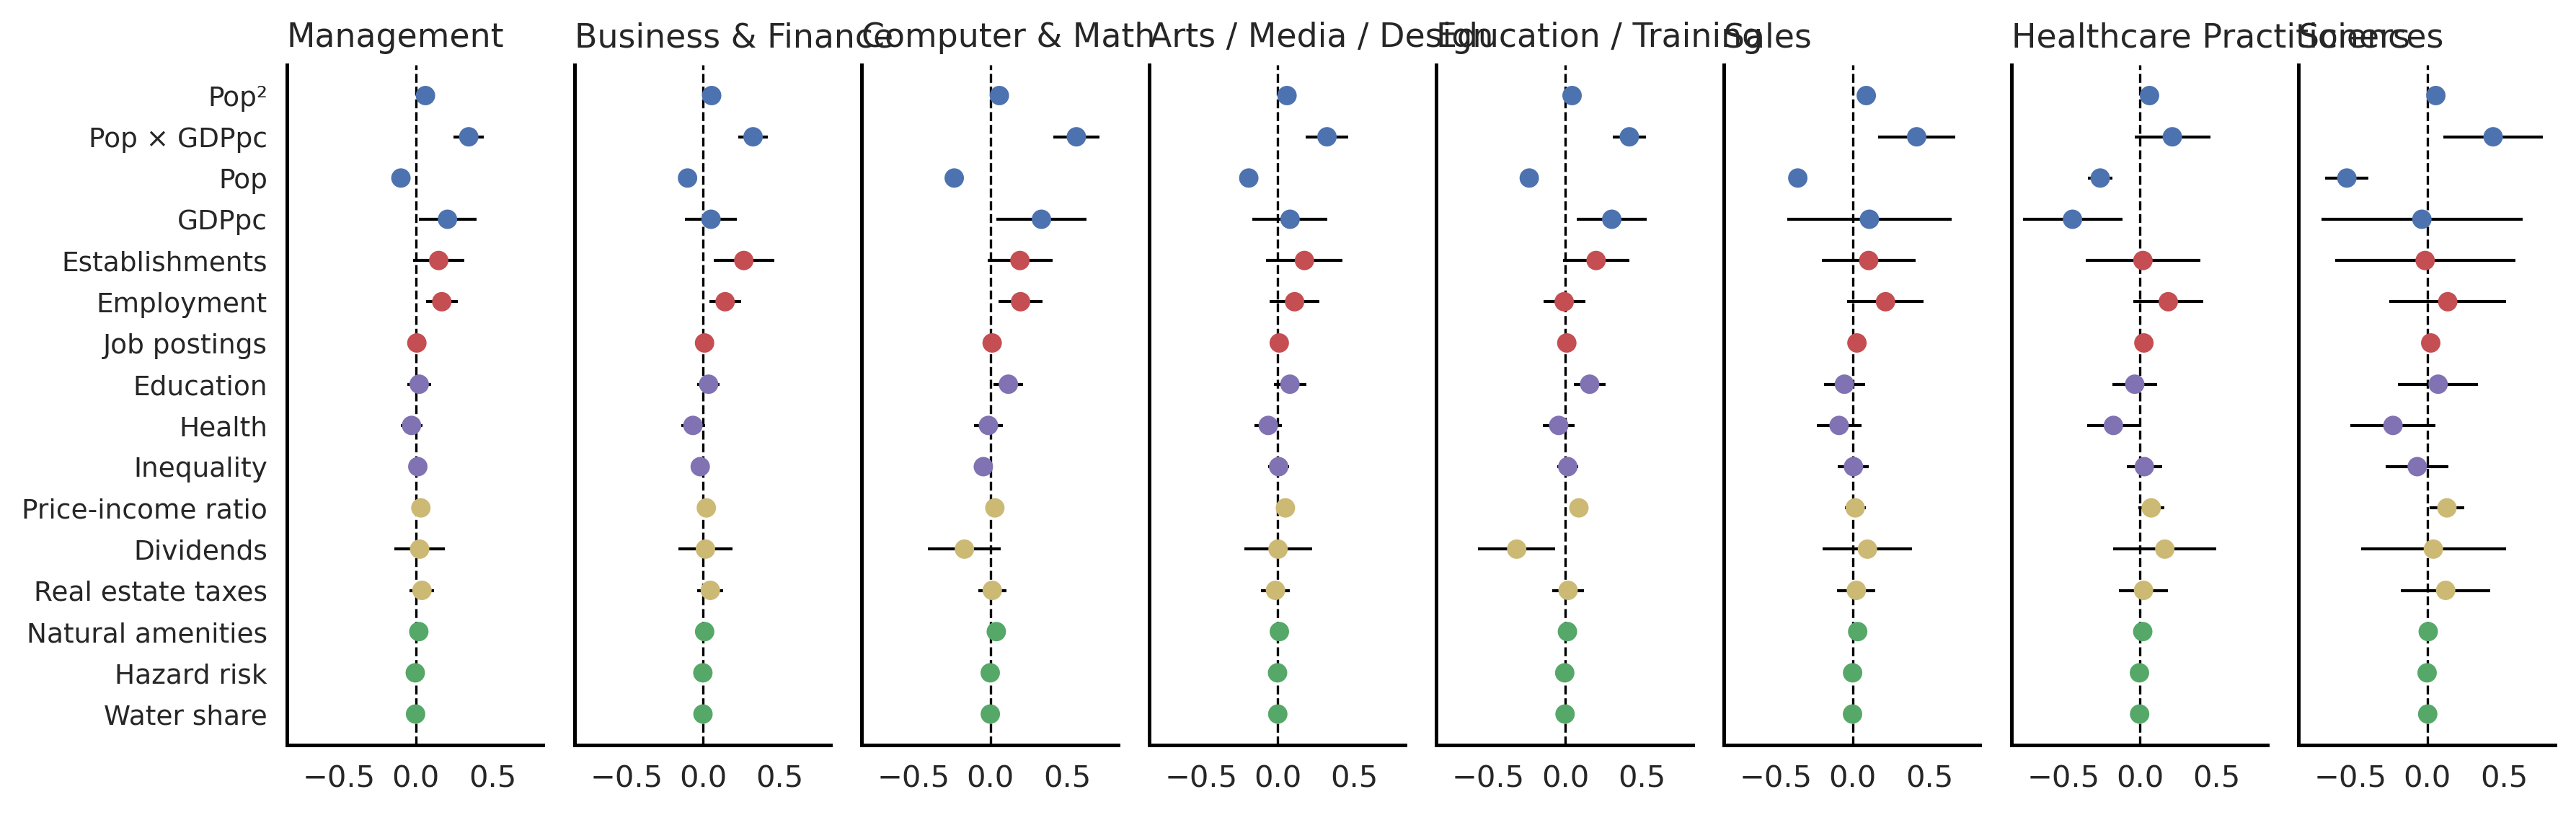

In [123]:
group_colors = {
    "Agglomeration size &\n economic power": "#4C72B0",
    "Geography": "#55A868",
    "Labour market\n structure": "#C44E52",
    "Human capital": "#8172B3",
    "Individual wealth": "#CCB974"
}

industries = coef_df_long["Industry"].unique()

fig, axes = plt.subplots(
    nrows=1,
    ncols=8,
    figsize=(12,4),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

for ax, industry in zip(axes, industries):

    sub = (
        coef_df_long[coef_df_long["Industry"] == industry]
        .set_index("Variable")
        .loc[var_order]
        .reset_index()
    )

    y = np.arange(len(sub))

    # confidence intervals
    ax.hlines(
        y=y,
        xmin=sub["ci_low"],
        xmax=sub["ci_high"],
        color="black",
        linewidth=1
    )

    # point estimates
    ax.scatter(
        sub["coef"],
        y,
        c=sub["Group"].map(group_colors),
        s=32,
        zorder=3
    )

    # zero line
    ax.axvline(0, color="black", linestyle="--", linewidth=0.8)

    ax.set_title(industry, fontsize=11, loc="left")
    ax.set_yticks(y)
    ax.set_yticklabels(sub["Variable_label"], fontsize=9)

    ax.invert_yaxis()

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(False)

# remove unused facets
for ax in axes[len(industries):]:
    ax.axis("off")

fig.supxlabel("")

plt.tight_layout()
plt.show()


In [124]:
def sig_to_level(sig):
    return {
        "***": 3,
        "**": 2,
        "*": 1,
        "+": 0.5,
        "": 0
    }.get(sig, 0)

coef_df_long["significance_level"] = coef_df_long["sig"].apply(sig_to_level)
coef_df_long["heat_value"] = (
    np.sign(coef_df_long["coef"]) *
    coef_df_long["significance_level"]
)


In [125]:
coef_std = (
    coef_df_long
    .groupby("Variable")["coef"]
    .transform(lambda x: x / x.std())
)

coef_df_long["coef_std"] = coef_std
coef_df_long["significant"] = coef_df_long["significance_level"] >= 0.5

coef_df_long["coef_std_masked"] = np.where(
    coef_df_long["significant"],
    coef_df_long["coef_std"],
    0.0
)

heat_df_ind = (
    coef_df_long
    .pivot(index="Variable",
           columns="Industry",
           values="coef_std_masked")
)

heat_df_ind = heat_df_ind.loc[var_order]

heat_df_ind.index = heat_df_ind.index.map(var_labels)

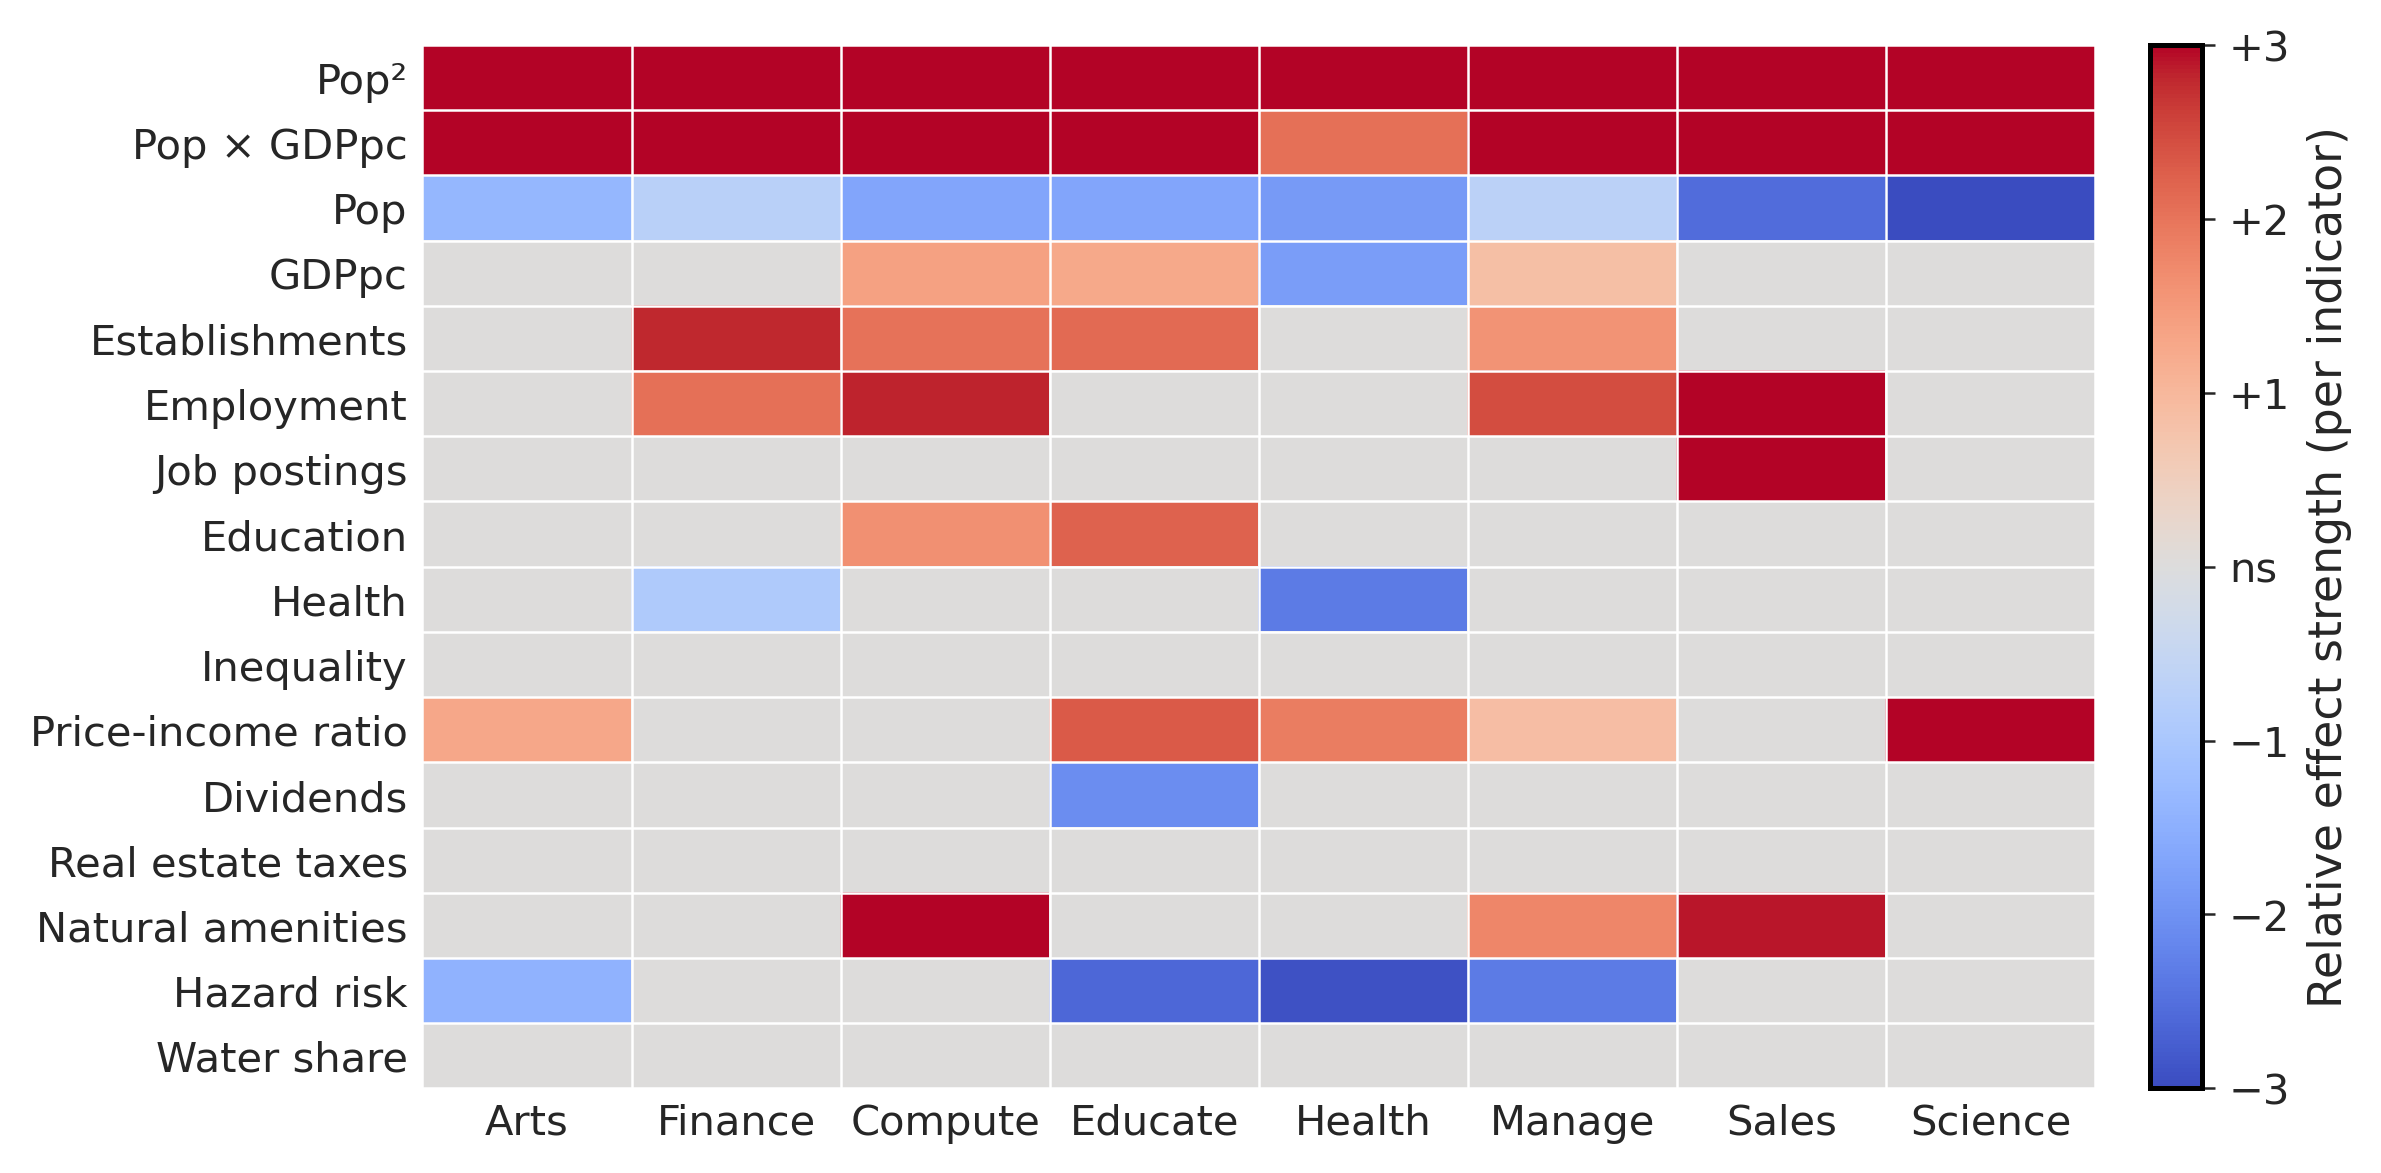

In [126]:
fig, ax = plt.subplots(figsize=(8, 4))

im = ax.imshow(
    heat_df_ind.values,
    cmap='coolwarm',
    vmin=-3,
    vmax=3,
    aspect="auto",
    alpha=1)

ax.invert_yaxis()
    
ax.set_xticks(np.arange(len(heat_df_ind.columns)))
ax.set_xticklabels(['Arts', 'Finance', 'Compute', 'Educate', 'Health', 'Manage', 'Sales', 'Science'], rotation=0, ha="center")

# y labels on the right
ax.yaxis.tick_left()
ax.set_yticks(np.arange(len(heat_df_ind.index)))
ax.set_yticklabels(heat_df_ind.index)

ax.tick_params(axis="y", which="both", length=0)
ax.tick_params(axis="x", which="both", length=0)

ax.set_xticks(np.arange(-0.5, len(heat_df_ind.columns), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(heat_df_ind.index), 1), minor=True)
ax.grid(which="minor", color="white", linestyle='-', linewidth=0.6)
ax.tick_params(which="minor", bottom=False, left=False)

# clean spines
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_xlabel("")
ax.set_ylabel("")



cbar = fig.colorbar(
    im,
    ax=ax,
    orientation="vertical",
    fraction=0.045,
    pad=0.03
)

ticks = [-3, -2, -1, 0, 1, 2, 3]
cbar.set_ticks(ticks)

cbar.set_ticklabels([
    "−3",
    "−2",
    "−1",
    "ns",
    "+1",
    "+2",
    "+3"
])

cbar.ax.tick_params()
cbar.set_label("Relative effect strength (per indicator)")


plt.tight_layout()
plt.show()


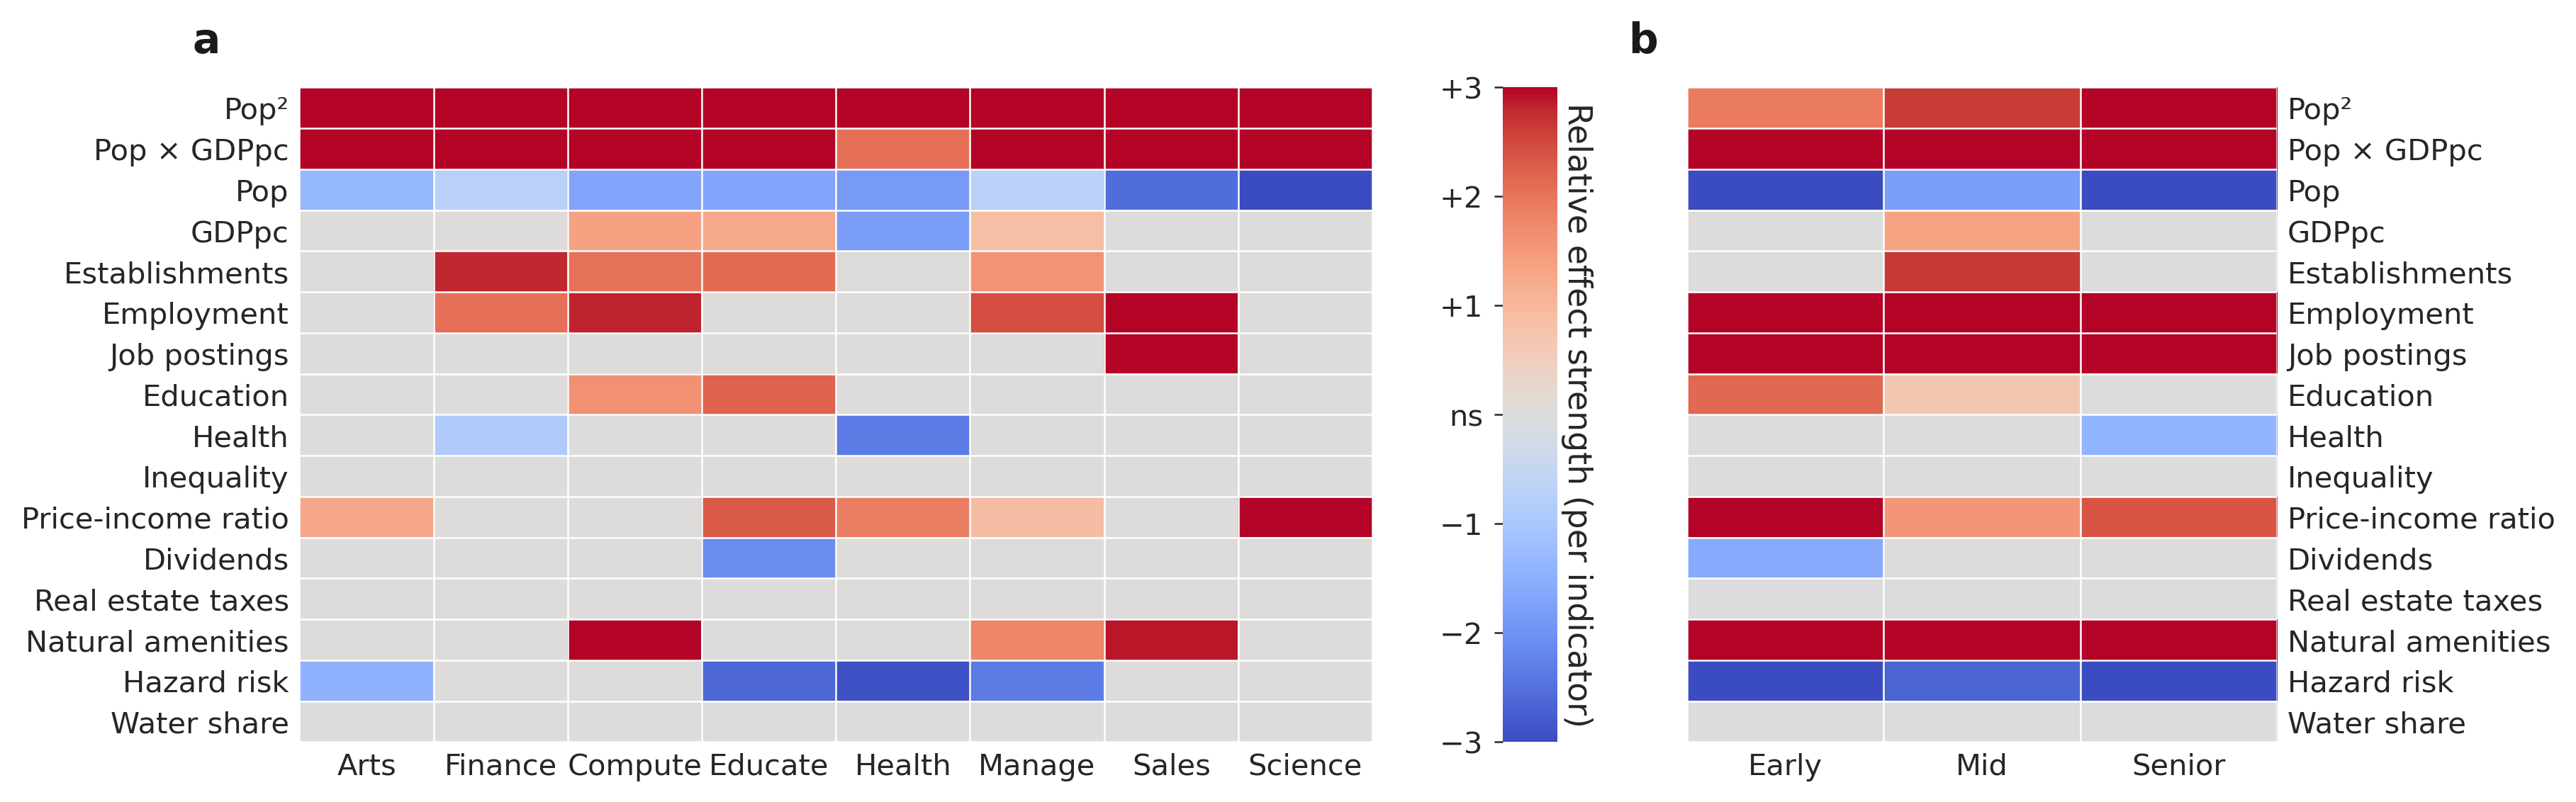

In [127]:
from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(12, 4))

gs = GridSpec(
    nrows=1,
    ncols=3,
    width_ratios=[1.0, 0.20, 0.55],  # thinner colourbar column
    wspace=0.08
)

ax_left  = fig.add_subplot(gs[0, 0])
ax_cbar  = fig.add_subplot(gs[0, 1])   # colourbar axis (do NOT turn off)
ax_right = fig.add_subplot(gs[0, 2])

# --- heatmaps ---
im1 = ax_left.imshow(
    heat_df_ind.values,
    cmap="coolwarm",
    vmin=-3, vmax=3,
    aspect="auto"
)

im2 = ax_right.imshow(
    heat_df_sen.values,
    cmap="coolwarm",
    vmin=-3, vmax=3,
    aspect="auto"
)

for ax in [ax_left, ax_right]:
    ax.invert_yaxis()
    ax.tick_params(axis="y", which="both", length=0)
    ax.tick_params(axis="x", which="both", length=0)
    ax.grid(which="minor", color="white", linestyle="-", linewidth=0.6)
    ax.tick_params(which="minor", bottom=False, left=False)
    for spine in ax.spines.values():
        spine.set_visible(False)

# --- left ticks ---
ax_left.set_xticks(np.arange(len(heat_df_ind.columns)))
ax_left.set_xticklabels(
    ["Arts", "Finance", "Compute", "Educate", "Health", "Manage", "Sales", "Science"],
    rotation=0, ha="center"
)
ax_left.yaxis.tick_left()
ax_left.set_yticks(np.arange(len(heat_df_ind.index)))
ax_left.set_yticklabels(heat_df_ind.index)
ax_left.set_xticks(np.arange(-0.5, len(heat_df_ind.columns), 1), minor=True)
ax_left.set_yticks(np.arange(-0.5, len(heat_df_ind.index), 1), minor=True)

# --- right ticks ---
ax_right.set_xticks(np.arange(len(heat_df_sen.columns)))
ax_right.set_xticklabels(["Early", "Mid", "Senior"], rotation=0, ha="center")
ax_right.yaxis.tick_right()
ax_right.set_yticks(np.arange(len(heat_df_sen.index)))
ax_right.set_yticklabels(heat_df_sen.index)
ax_right.set_xticks(np.arange(-0.5, len(heat_df_sen.columns), 1), minor=True)
ax_right.set_yticks(np.arange(-0.5, len(heat_df_sen.index), 1), minor=True)

# --- colourbar in the middle axis ---
cbar = fig.colorbar(im1, cax=ax_cbar, orientation="vertical")

cbar.ax.set_aspect(2)

cbar.set_ticks([-3, -2, -1, 0, 1, 2, 3])
cbar.set_ticklabels(["−3", "−2", "−1", "ns", "+1", "+2", "+3"])

cbar.set_label("Relative effect strength (per indicator)", rotation=-90, labelpad=12)
cbar.ax.yaxis.set_label_position("right")  # nicer between panels
cbar.ax.yaxis.set_ticks_position("left")
cbar.outline.set_visible(False)

plots_l = ['a', '', 'b']
for ia, ax in enumerate(fig.axes): 
    x,y = -0.1,1.04
    ax.text(x,y,  plots_l[ia],
        color = 'k',#'lightgreen',
        horizontalalignment='left',
        verticalalignment='bottom',
        weight = 'bold',
        transform=ax.transAxes,fontsize = 14)

plt.savefig(
    '../fig/si/si_prmodelling_indsen.pdf',
    bbox_inches='tight',
    dpi=300
)

plt.show()


### For SI-7: CBSA without probabilistic assignment

In [128]:
nri_county=df = pd.read_parquet("../data_loaded/nri_counties.parquet")

counties = load_counties()
cbsa = load_cbsa()

In [129]:
business = pd.read_csv("../data_loaded/cbp22co.zip", sep=',')

business["STCOFIPS"] = (
            business["fipstate"].astype(str).str.zfill(2)
            + business["fipscty"].astype(str).str.zfill(3))

business=business[business['naics'].isin(['51----','52----','53----','54----','55----','56----'])]

business=business.groupby('STCOFIPS').agg({'emp':'sum', 'est':'sum'}).reset_index()

In [130]:
hits_irs=pd.read_parquet("../data_generated/network_metrics/cbsa_hits_irs_1122.parquet")
hits_exp=pd.read_parquet("../data_generated/network_metrics/cbsa_hits_exp_1122.parquet")

hits_merged=hits_irs.merge(hits_exp, left_on=['CBSA'], right_on=['CBSA'], how='inner', suffixes=('_irs', '_exp'))

In [131]:
hits_merged['pagerank_diff']=hits_merged['pagerank_exp']-hits_merged['pagerank_irs']

xwalk = cbsa[['STCOFIPS', 'CBSA Code', 'CBSA Title']].drop_duplicates()

counties = counties.merge(xwalk, on='STCOFIPS', how='left')
nri_county = nri_county.merge(xwalk, on='STCOFIPS', how='left')

counties_cbsa = (
    counties
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code', 'CBSA Title'], as_index=False)
    .agg(
        ALAND=('ALAND', 'sum'),
        AWATER=('AWATER', 'sum')
    )
)
counties_cbsa['water_perc'] = counties_cbsa['AWATER'] / (counties_cbsa['ALAND'] + counties_cbsa['AWATER']) * 100


def wmean(x, w):
    x = pd.to_numeric(x, errors='coerce')
    w = pd.to_numeric(w, errors='coerce')
    m = x.notna() & w.notna()
    if not m.any():
        return np.nan
    return np.average(x[m], weights=w[m])

hazards = [
    'RISK_SCORE', 'AVLN_RISKS', 'CFLD_RISKS', 'CWAV_RISKS', 'DRGT_RISKS',
    'ERQK_RISKS', 'HAIL_RISKS', 'HWAV_RISKS', 'HRCN_RISKS', 'ISTM_RISKS',
    'LNDS_RISKS', 'LTNG_RISKS', 'RFLD_RISKS', 'SWND_RISKS', 'TRND_RISKS',
    'TSUN_RISKS', 'VLCN_RISKS', 'WFIR_RISKS', 'WNTW_RISKS'
]

nri_county[hazards] = (
    nri_county[hazards]
    .replace(-9999, np.nan)
    .apply(pd.to_numeric, errors='coerce')
)


nri_cbsa = (
    nri_county
    .dropna(subset=['CBSA Code'])
    .assign(POPULATION=pd.to_numeric(nri_county['POPULATION'], errors='coerce'))
    .groupby(['CBSA Code', 'CBSA Title'], as_index=False)
    .agg(
        POPULATION=('POPULATION', 'sum'),
        **{h: (h, 'mean') for h in hazards}
    )
)

cbsa_agg = (
    counties_cbsa
    .merge(nri_cbsa, on=['CBSA Code', 'CBSA Title'], how='outer')
)

cbsa_agg['pop_density'] = cbsa_agg['POPULATION'] / cbsa_agg['ALAND'] * 1_000_000


hits_merged = hits_merged.merge(
    cbsa_agg,
    left_on=['CBSA'],
    right_on=['CBSA Code'],
    how='left',
    suffixes=('', '_cbsa')
)


In [132]:
## Job postings

jobposts=pd.read_csv('../data_loaded/jobpostings_aggregated/job_postings_county_month.csv')
jobposts_naics=pd.read_csv('../data_loaded/jobpostings_aggregated/job_postings_county_month_naics.csv')

jobposts_naics['year'] = jobposts_naics['month_year'].str[:4].astype(int)
jobposts_naics = jobposts_naics[jobposts_naics['year'].isin([2016, 2017, 2018,2019])].reset_index(drop=True)

jobposts_naics['STCOFIPS']=jobposts_naics['STCOFIPS'].astype(str)
jobposts_naics = jobposts_naics.merge(xwalk, on='STCOFIPS', how='left')

total_posts = (
    jobposts_naics
    .groupby(["CBSA Code"])
    .n_postings
    .sum()
    .reset_index()
    .rename(columns={"n_postings": "total_postings"})
)

target_posts = (
    jobposts_naics[jobposts_naics["NAICS_2"].isin([51, 52, 53, 54, 55, 56])]
    .groupby(["CBSA Code"])
    .n_postings
    .sum()
    .reset_index()
    .rename(columns={"n_postings": "target_postings"})
)

jobposts_share = (
    total_posts
    .merge(target_posts, on=["CBSA Code"], how="left")
)

jobposts_share["target_postings"] = jobposts_share["target_postings"].fillna(0)
jobposts_share["share_target_pct"] = (
    100 * jobposts_share["target_postings"] / jobposts_share["total_postings"]
)

jobposts_share['CBSA Code']=jobposts_share['CBSA Code'].astype(str)
jobposts_share["CBSA Code"]=jobposts_share["CBSA Code"].astype(str).str.zfill(5)

hits_merged=hits_merged.merge(jobposts_share, left_on='CBSA', right_on='CBSA Code', how='left')
hits_merged['target_postings'] = hits_merged['target_postings'].fillna(0)
hits_merged['n_postings_100k'] = hits_merged['target_postings']/hits_merged['POPULATION']*100_000

In [133]:
business = business.merge(xwalk, on='STCOFIPS', how='left')
business=business.groupby('CBSA Code').agg({'emp':'sum', 'est':'sum'}).reset_index()

hits_merged=hits_merged.merge(business, left_on='CBSA', right_on='CBSA Code', how='left')

hits_merged['emp_100k'] = hits_merged['emp']/hits_merged['POPULATION']*100_000
hits_merged['est_100k'] = hits_merged['est']/hits_merged['POPULATION']*100_000

In [134]:
# MY URBAN
pop_w = nri_county[['STCOFIPS', 'POPULATION']].copy()
pop_w['POPULATION'] = pd.to_numeric(pop_w['POPULATION'], errors='coerce')

urban=pd.read_parquet('../data_loaded/data_final/urban_afford.parquet')
urban['STCOFIPS'] = urban['STCOFIPS'].astype(str)

urban_cbsa_in = (
    urban[['STCOFIPS','nat_amenity_score','urbanism','real_estate_taxes_med',
           'med_home_price2017','income_price_ratio2023','inequality_ratio']]
    .merge(pop_w, on='STCOFIPS', how='left')
    .merge(xwalk, on='STCOFIPS', how='left')
)

urbanism_dict = {
    "6 - Noncore": 1,
    "5 - Micropolitan": 2,
    "4 - Small metro": 3,
    "3 - Medium metro": 4,
    "2 - Large fringe metro": 5,
    "1 - Large central metro": 6
}

urban_cbsa_in["urbanism"] = urban_cbsa_in["urbanism"].map(urbanism_dict)


urban_cbsa = (
    urban_cbsa_in
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code', 'CBSA Title'], as_index=False)
    .apply(lambda g: pd.Series({
        'nat_amenity_score': wmean(g['nat_amenity_score'], g['POPULATION']),
        'real_estate_taxes_med': wmean(g['real_estate_taxes_med'], g['POPULATION']),
        'med_home_price2017': wmean(g['med_home_price2017'], g['POPULATION']),
        'income_price_ratio2023': wmean(g['income_price_ratio2023'], g['POPULATION']),
        'inequality_ratio': wmean(g['inequality_ratio'], g['POPULATION']),

        'urbanism_pwmean': wmean(g['urbanism'], g['POPULATION'])
    }))
    .reset_index(drop=True)
)

urban_r = urban_cbsa.set_index('CBSA Code').drop(columns=['CBSA Title'], errors='ignore')

hits_merged = hits_merged.join(urban_r, on='CBSA')

In [135]:
## MY HDI

education_calulated=pd.read_parquet('../data_loaded/data_final/education_combined.parquet')
health_calulated=pd.read_parquet('../data_loaded/data_final/health_combined.parquet')
income_calulated=pd.read_parquet('../data_loaded/data_final/median_income_combined.parquet')

health_calulated=health_calulated[health_calulated['year']==2020][['STCOFIPS', 'health_index', 'health_index_adj']]
income_calulated=income_calulated[income_calulated['year']==2020][['STCOFIPS', 'income_index', 'income_index_adj']]

## MY INCOME
income_combined=pd.read_parquet('../data_loaded/data_final/income_combined.parquet')
income_combined=income_combined[income_combined['year']==2019].reset_index(drop=True)

income_combined = income_combined.pivot_table(
    index=["STCOFIPS"],    
    columns="Description",  
    values="value",        
    aggfunc="first"
).reset_index()

income_combined.columns.name = None

income_combined['gdp_pc']=income_combined['real_gdp_chained_2017']/income_combined['population']
income_combined['dividends_pc']=income_combined['dividends']/income_combined['population']

income_combined=income_combined[['STCOFIPS', 'personal_income_pc', 'poverty_rate_all', 'gdp_pc', 'dividends_pc', 'dividends']]

In [136]:
pop_w = nri_county[['STCOFIPS', 'POPULATION']].copy()
pop_w['POPULATION'] = pd.to_numeric(pop_w['POPULATION'], errors='coerce')

education_cbsa = (
    education_calulated
    .merge(pop_w, on='STCOFIPS', how='left')
    .merge(xwalk, on='STCOFIPS', how='left')
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code'], as_index=False)
    .apply(lambda g: pd.Series({
        'education_index': wmean(g['education_index'], g['POPULATION'])
    }))
    .reset_index(drop=True)
)

health_cbsa = (
    health_calulated
    .merge(pop_w, on='STCOFIPS', how='left')
    .merge(xwalk, on='STCOFIPS', how='left')
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code'], as_index=False)
    .apply(lambda g: pd.Series({
        'health_index_adj': wmean(g['health_index_adj'], g['POPULATION'])
    }))
    .reset_index(drop=True)
)

income_cbsa = (
    income_calulated
    .merge(pop_w, on='STCOFIPS', how='left')
    .merge(xwalk, on='STCOFIPS', how='left')
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code'], as_index=False)
    .apply(lambda g: pd.Series({
        'income_index_adj': wmean(g['income_index_adj'], g['POPULATION'])
    }))
    .reset_index(drop=True)
)

combined_income_cbsa = (
    income_combined
    .merge(pop_w, on='STCOFIPS', how='left')
    .merge(xwalk, on='STCOFIPS', how='left')
    .dropna(subset=['CBSA Code'])
    .groupby(['CBSA Code'], as_index=False)
    .apply(lambda g: pd.Series({
        'personal_income_pc': wmean(g['personal_income_pc'], g['POPULATION']),
        'poverty_rate_all': wmean(g['poverty_rate_all'], g['POPULATION']),
        'gdp_pc': wmean(g['gdp_pc'], g['POPULATION']),
        'dividends_pc': wmean(g['dividends_pc'], g['POPULATION']),
        'dividends': pd.to_numeric(g['dividends'], errors='coerce').sum(skipna=True),
        'POPULATION_sum': g['POPULATION'].sum(skipna=True)
    }))
    .reset_index(drop=True)
)



In [137]:
hits_merged['CBSA'] = hits_merged['CBSA'].astype(str)

for df in [education_cbsa, health_cbsa, income_cbsa, combined_income_cbsa]:
    df['CBSA Code'] = df['CBSA Code'].astype(str)

education_r = education_cbsa.set_index('CBSA Code').drop(columns=['CBSA Title'], errors='ignore')
health_r    = health_cbsa.set_index('CBSA Code').drop(columns=['CBSA Title'], errors='ignore')
income_r    = income_cbsa.set_index('CBSA Code').drop(columns=['CBSA Title'], errors='ignore')
cincome_r   = combined_income_cbsa.set_index('CBSA Code').drop(columns=['CBSA Title'], errors='ignore')

hits_merged = (
    hits_merged
    .join(education_r, on='CBSA')
    .join(health_r, on='CBSA')
    .join(income_r, on='CBSA')
    .join(cincome_r, on='CBSA')
)


In [138]:
hits_merged.columns

Index(['CBSA', 'hub_irs', 'auth_irs', 'pagerank_irs', 'rank_hub_irs',
       'rank_auth_irs', 'rank_page_irs', 'hub_exp', 'auth_exp', 'pagerank_exp',
       'rank_hub_exp', 'rank_auth_exp', 'rank_page_exp', 'pagerank_diff',
       'CBSA Code_x', 'CBSA Title', 'ALAND', 'AWATER', 'water_perc',
       'POPULATION', 'RISK_SCORE', 'AVLN_RISKS', 'CFLD_RISKS', 'CWAV_RISKS',
       'DRGT_RISKS', 'ERQK_RISKS', 'HAIL_RISKS', 'HWAV_RISKS', 'HRCN_RISKS',
       'ISTM_RISKS', 'LNDS_RISKS', 'LTNG_RISKS', 'RFLD_RISKS', 'SWND_RISKS',
       'TRND_RISKS', 'TSUN_RISKS', 'VLCN_RISKS', 'WFIR_RISKS', 'WNTW_RISKS',
       'pop_density', 'CBSA Code_y', 'total_postings', 'target_postings',
       'share_target_pct', 'n_postings_100k', 'CBSA Code', 'emp', 'est',
       'emp_100k', 'est_100k', 'nat_amenity_score', 'real_estate_taxes_med',
       'med_home_price2017', 'income_price_ratio2023', 'inequality_ratio',
       'urbanism_pwmean', 'education_index', 'health_index_adj',
       'income_index_adj', 'persona

In [139]:
# log transforms (avoid −inf)
for col in ["pagerank_irs", "pagerank_exp"]:
    hits_merged[f"log_{col}"] = (hits_merged[col] + 1e-12).apply(np.log) # there are no zeroes

for col in ['POPULATION', 'target_postings', 'n_postings_100k', 'emp_100k', 'est_100k', 
            'personal_income_pc', 'gdp_pc', 'dividends_pc', 'pop_density',
            'real_estate_taxes_med', 'med_home_price2017']:
    hits_merged[f"log_{col}"] = (hits_merged[col]).apply(np.log1p)

hits_merged['pagerank_logdiff']=hits_merged['log_pagerank_exp']-hits_merged['log_pagerank_irs']

In [140]:
df = hits_merged.copy()
na_counts = df.isna().sum()
print(na_counts[na_counts > 0])

AVLN_RISKS                719
CFLD_RISKS                634
HRCN_RISKS                220
ISTM_RISKS                 65
LNDS_RISKS                  4
LTNG_RISKS                  8
TSUN_RISKS                764
VLCN_RISKS                763
CBSA Code_y                94
total_postings             94
share_target_pct           94
nat_amenity_score           8
med_home_price2017          8
income_price_ratio2023      8
personal_income_pc          5
gdp_pc                      5
dividends_pc                5
log_personal_income_pc      5
log_gdp_pc                  5
log_dividends_pc            5
log_med_home_price2017      8
dtype: int64


In [141]:
df = (
    df
    .dropna(subset=df.columns.difference(hazards))
    .reset_index(drop=True)
)


In [142]:
corr_pearson=df[["pagerank_logdiff", "RISK_SCORE", "POPULATION", 'emp_100k', 'est_100k',
                 "target_postings", "n_postings_100k", 
                 'personal_income_pc', 'poverty_rate_all', 'gdp_pc', 'dividends', 'dividends_pc',
                 'education_index', 'income_index_adj', 'health_index_adj', 
                 'nat_amenity_score','real_estate_taxes_med', 'med_home_price2017', 'income_price_ratio2023', 
                 'pop_density', 'water_perc', 'inequality_ratio']].corr(method='pearson').round(3)

In [143]:
corr_spearman=df[["pagerank_logdiff", "RISK_SCORE", "POPULATION", 'emp_100k', 'est_100k',
                 "target_postings", "n_postings_100k", 
                 'personal_income_pc', 'poverty_rate_all', 'gdp_pc', 'dividends', 'dividends_pc',
                 'education_index', 'income_index_adj', 'health_index_adj', 
                 'nat_amenity_score','real_estate_taxes_med', 'med_home_price2017', 'income_price_ratio2023', 
                 'pop_density', 'water_perc', 'inequality_ratio']].corr(method='spearman').round(3)

In [144]:
def format_bottom_colorbar(cbar, label):
    # identical tick behaviour
    cbar.ax.tick_params(
        axis="x",
        labelsize=9,
        length=4,
        width=0.6,
        pad=3
    )

    # identical label formatting
    cbar.set_label(label, fontsize=10, labelpad=4)

    # identical spine appearance
    for side in ["bottom", "top"]:
        cbar.ax.spines[side].set_visible(True)
        cbar.ax.spines[side].set_linewidth(0.6)

    # no left/right spines (keeps consistent)
    cbar.ax.spines["left"].set_visible(False)
    cbar.ax.spines["right"].set_visible(False)

In [145]:
df['log_pop_centered'] = df['log_POPULATION'] - df['log_POPULATION'].mean()
df['log_n_postings_centered'] = df['log_n_postings_100k'] - df['log_n_postings_100k'].mean()
df['log_gdp_centered'] = df['log_gdp_pc'] - df['log_gdp_pc'].mean()
df['education_centered'] = df['education_index'] - df['education_index'].mean()
df['income_centered'] = df['income_index_adj'] - df['income_index_adj'].mean()
df['health_centered'] = df['health_index_adj'] - df['health_index_adj'].mean()
df['risk_centered'] = df['RISK_SCORE'] - df['RISK_SCORE'].mean()
df['poverty_rate_centered'] = df['poverty_rate_all'] - df['poverty_rate_all'].mean()
df['nat_amenity_centered'] = df['nat_amenity_score'] - df['nat_amenity_score'].mean()
df['log_taxes_med_centered'] = df['log_real_estate_taxes_med'] - df['log_real_estate_taxes_med'].mean()
df['income_price_ratio2023_centered'] = df['income_price_ratio2023'] - df['income_price_ratio2023'].mean()
df['log_personal_income_centered'] = df['log_personal_income_pc'] - df['log_personal_income_pc'].mean()
df['log_est_100k_centered'] = df['log_est_100k'] - df['log_est_100k'].mean()
df['log_emp_100k_centered'] = df['log_emp_100k'] - df['log_emp_100k'].mean()
df['water_perc_centered'] = df['water_perc'] - df['water_perc'].mean()
df['log_pop_density_centered'] = df['log_pop_density'] - df['log_pop_density'].mean()
df['log_dividends_centered'] = df['log_dividends_pc'] - df['log_dividends_pc'].mean()
df['inequality_centered'] = df['inequality_ratio'] - df['inequality_ratio'].mean()


for hazard in hazards:
    df[f'{hazard}_centered'] = df[hazard] - df[hazard].mean()

In [146]:
model_1= smf.ols(
    formula="pagerank_logdiff ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)",
    data=df
).fit(cov_type='HC3')

model_2= smf.ols(
    formula="pagerank_logdiff ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered",
    data=df
).fit(cov_type='HC3')


model_3= smf.ols(
    formula="pagerank_logdiff ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
            "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered",
    data=df
).fit(cov_type='HC3')

model_4= smf.ols(
    formula="pagerank_logdiff ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
            "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered"
            "+ education_centered + health_centered + inequality_centered",
    data=df
).fit(cov_type='HC3')

model_5= smf.ols(
    formula="pagerank_logdiff ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
            "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered"
            "+ education_centered + health_centered + inequality_centered"
            "+ nat_amenity_centered + water_perc_centered + risk_centered",
    data=df
).fit(cov_type='HC3')

model_1_1= smf.ols(
    formula="log_pagerank_exp ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)",
    data=df
).fit(cov_type='HC3')

model_2_1= smf.ols(
    formula="log_pagerank_exp ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered",
    data=df
).fit(cov_type='HC3')


model_3_1= smf.ols(
    formula="log_pagerank_exp ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
            "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered",
    data=df
).fit(cov_type='HC3')

model_4_1= smf.ols(
    formula="log_pagerank_exp ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
            "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered"
            "+ education_centered + health_centered + inequality_centered",
    data=df
).fit(cov_type='HC3')

model_5_1= smf.ols(
    formula="log_pagerank_exp ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
            "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered"
            "+ education_centered + health_centered + inequality_centered"
            "+ nat_amenity_centered + water_perc_centered + risk_centered",
    data=df
).fit(cov_type='HC3')

model_1_2= smf.ols(
    formula="log_pagerank_irs ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)",
    data=df
).fit(cov_type='HC3')

model_2_2= smf.ols(
    formula="log_pagerank_irs ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered",
    data=df
).fit(cov_type='HC3')


model_3_2= smf.ols(
    formula="log_pagerank_irs ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
            "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered",
    data=df
).fit(cov_type='HC3')

model_4_2= smf.ols(
    formula="log_pagerank_irs ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
            "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered"
            "+ education_centered + health_centered + inequality_centered",
    data=df
).fit(cov_type='HC3')

model_5_2= smf.ols(
    formula="log_pagerank_irs ~ log_pop_centered + log_gdp_centered + log_pop_centered*log_gdp_centered + I(log_pop_centered**2)"
            "+ log_taxes_med_centered + log_dividends_centered + income_price_ratio2023_centered"
            "+ log_est_100k_centered + log_emp_100k_centered + log_n_postings_centered"
            "+ education_centered + health_centered + inequality_centered"
            "+ nat_amenity_centered + water_perc_centered + risk_centered",
    data=df
).fit(cov_type='HC3')

In [147]:
summary = summary_col(
    [model_1, model_2, model_3, model_4, model_5, model_1_1, model_2_1, model_3_1, model_4_1, model_5_1, model_1_2, model_2_2, model_3_2, model_4_2, model_5_2],
    stars=False,
    model_names=[
        "Model 1", "Model 2", "Model 3", "Model 4", "Model 5", "Model 1", "Model 2", "Model 3", "Model 4", "Model 5", "Model 1", "Model 2", "Model 3", "Model 4", "Model 5"
    ],
    info_dict = {
        "N": lambda x: f"{int(x.nobs)}",
        r"$R^2$": lambda x: f"{x.rsquared:.3f}",
        r"Adj. $R^2$": lambda x: f"{x.rsquared_adj:.3f}",
        "BIC": lambda x: f"{x.bic:.2f}",
    }
)


In [148]:
df_results = summary.tables[0]

models = [model_1, model_2, model_3, model_4, model_5, model_1_1, model_2_1, model_3_1, model_4_1, model_5_1, model_1_2, model_2_2, model_3_2, model_4_2, model_5_2]

for col, model in zip(df_results.columns, models):
    for param in model.params.index:
        if param not in df_results.index:
            continue

        coef = model.params[param]
        pval = model.pvalues[param]
        stars = make_stars(pval)

        df_results.loc[param, col] = f"{coef:.3f}{stars}"


In [149]:
df_results

,Model 1 I,Model 2 I,Model 3 I,Model 4 I,Model 5 I,Model 1 II,Model 2 II,Model 3 II,Model 4 II,Model 5 II,Model 1 III,Model 2 III,Model 3 III,Model 4 III,Model 5 III
I(log_pop_centered ** 2),0.064***,0.056***,0.056***,0.058***,0.057***,0.103***,0.101***,0.104***,0.104***,0.105***,0.038***,0.045***,0.048***,0.047***,0.048***
,(0.0114),(0.0122),(0.0111),(0.0110),(0.0107),(0.0119),(0.0120),(0.0104),(0.0104),(0.0104),(0.0072),(0.0076),(0.0078),(0.0086),(0.0075)
Intercept,-0.719***,-0.712***,-0.714***,-0.714***,-0.714***,-8.130***,-8.127***,-8.132***,-8.131***,-8.131***,-7.410***,-7.415***,-7.418***,-7.418***,-7.417***
,(0.0206),(0.0206),(0.0191),(0.0188),(0.0187),(0.0209),(0.0209),(0.0188),(0.0172),(0.0171),(0.0145),(0.0139),(0.0139),(0.0136),(0.0134)
R-squared,0.2915,0.3565,0.4085,0.4199,0.4358,0.9035,0.9068,0.9182,0.9305,0.9317,0.8766,0.8850,0.8864,0.8938,0.9007
R-squared Adj.,0.2874,0.3499,0.3999,0.4089,0.4225,0.9029,0.9058,0.9170,0.9292,0.9301,0.8758,0.8839,0.8847,0.8918,0.8984
education_centered,,,,0.083*,0.085*,,,,0.210***,0.207***,,,,0.127***,0.122***
,,,,(0.0344),(0.0370),,,,(0.0323),(0.0341),,,,(0.0324),(0.0299)
health_centered,,,,0.018,0.020,,,,0.091***,0.080**,,,,0.074*,0.060*
,,,,(0.0396),(0.0382),,,,(0.0274),(0.0276),,,,(0.0314),(0.0296)


5 groups of factors influencing the mobility preferences:

- Group 1: Agglomeration Size & Economic Power (GDP, Population, their interactions and squared term) 
- Group 2: Individual Wealth (Dividends and interest rates, median tax paid on real estate, real estate price - income ratio)
- Group 3: Labour Market Structure (Number of companies per 100k residents, number of employed per 100k residents, number of job postings)
- Group 4: Human Capital (education, health, inequality)
- Group 5: Geography (natural amenities, percentage of water, pop density, and somewhat risk)

In [150]:
groups = {
    "Agglomeration size &\n economic power": [
        "log_pop_centered",
        "log_gdp_centered",
        "log_pop_centered:log_gdp_centered",
        "I(log_pop_centered ** 2)"
    ],
    "Individual wealth": [
        "log_taxes_med_centered",
        "log_dividends_centered",
        "income_price_ratio2023_centered"
    ],
    "Labour market\n structure": [
        "log_est_100k_centered",
        "log_emp_100k_centered",
        "log_n_postings_centered"
    ],
    "Human capital": [
        "education_centered",
        "health_centered",
        "inequality_centered"
    ],
    "Geography": [
        "nat_amenity_centered",
        "water_perc_centered",
        "risk_centered"
    ]
}


import itertools
import math

def build_formula(dep_var, groups, selected_groups):
    rhs = []
    for g in selected_groups:
        rhs.extend(groups[g])
    rhs = list(dict.fromkeys(rhs))
    return dep_var + " ~ " + " + ".join(rhs)


dep_var = "pagerank_logdiff"

r2_map = {}

for k in range(len(groups) + 1):
    for combo in itertools.combinations(groups.keys(), k):

        if len(combo) == 0:
            formula = dep_var + " ~ 1"
        else:
            formula = build_formula(dep_var, groups, combo)

        model = smf.ols(formula=formula, data=df).fit()
        r2_map[frozenset(combo)] = model.rsquared

# --------------------------------------------------
# shapley (LMG) decomposition of R^2
# --------------------------------------------------

shapley = {g: 0.0 for g in groups}

G = list(groups.keys())
nG = len(G)

for g in G:
    for S in itertools.chain.from_iterable(
        itertools.combinations([x for x in G if x != g], r)
        for r in range(nG)
    ):
        S = frozenset(S)
        Sg = frozenset(set(S) | {g})

        weight = (
            math.factorial(len(S)) *
            math.factorial(nG - len(S) - 1) /
            math.factorial(nG)
        )

        delta_r2 = r2_map[Sg] - r2_map[S]
        shapley[g] += weight * delta_r2

# --------------------------------------------------
# results table
# --------------------------------------------------

results = (
    pd.DataFrame({
        "Group": shapley.keys(),
        "Shapley R2 contribution": shapley.values()
    })
    .sort_values("Shapley R2 contribution", ascending=False)
)

results["Share of total R2 (%)"] = (
    results["Shapley R2 contribution"] /
    sum(shapley.values()) * 100
)

results

,Group,Shapley R2 contribution,Share of total R2 (%)
0,Agglomeration size &\n economic power,0.237364,54.461083
2,Labour market\n structure,0.082930,19.027657
3,Human capital,0.051249,11.758737
1,Individual wealth,0.041150,9.441504
4,Geography,0.023148,5.311019


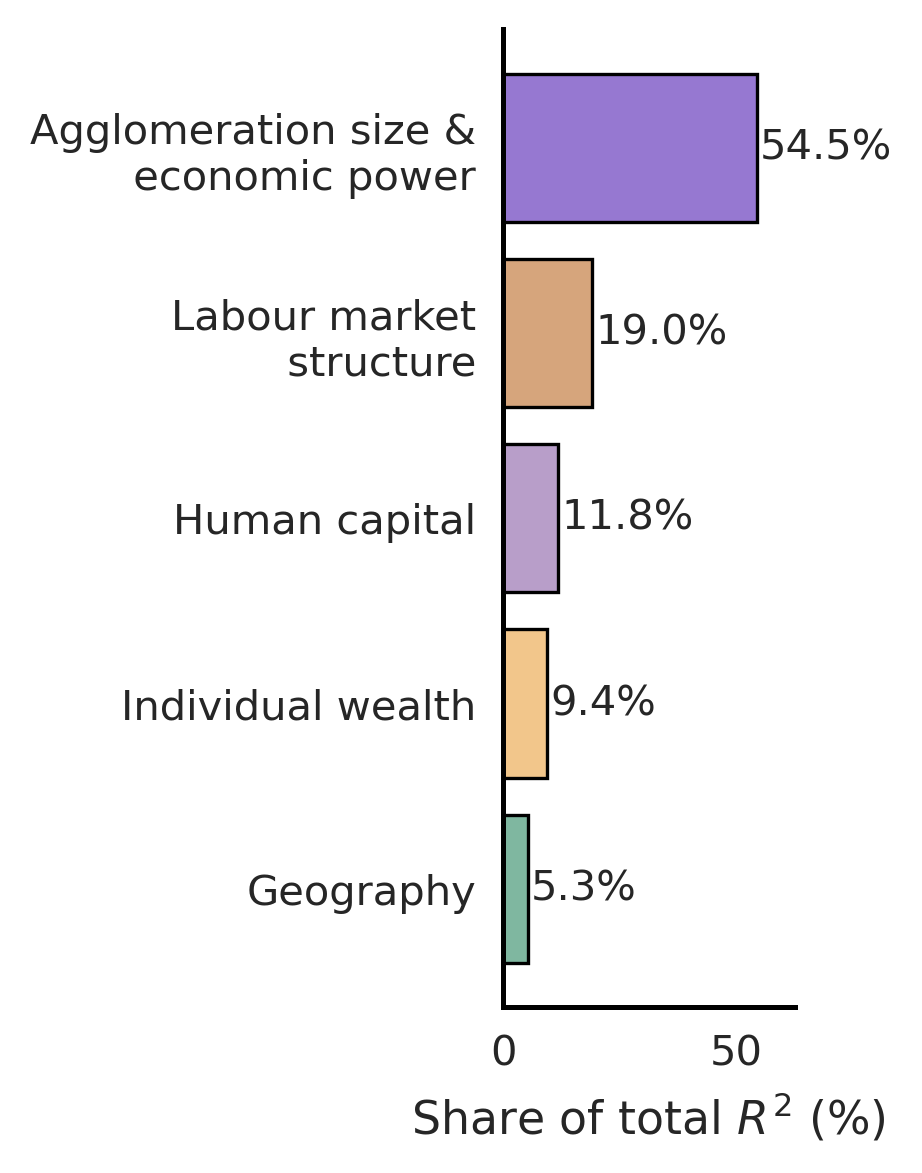

In [151]:
group_colors = {
    "Agglomeration size &\n economic power": "#9678D1",  # muted violet
    "Geography": "#7FB7A0",                              # sage green
    "Labour market\n structure": "#D6A57C",             # warm sand
    "Human capital": "#B89EC9",                          # lavender
    "Individual wealth": "#F2C68B"                       # soft amber
}

fig, ax = plt.subplots(figsize=(3, 4))

results = results.sort_values("Share of total R2 (%)", ascending=True)

ax.barh(
    results["Group"],
    results["Share of total R2 (%)"],
    color=results["Group"].map(group_colors),
    edgecolor="black",
    linewidth=0.8
)

for i, v in enumerate(results["Share of total R2 (%)"]):
    ax.text(
        v + 0.7,
        i,
        f"{v:.1f}%",
        va="center",
        fontsize=10
    )

# axis formatting
ax.set_xlabel("Share of total $R^2$ (%)")
ax.set_ylabel("")
ax.set_xlim(0, max(results["Share of total R2 (%)"]) * 1.15)

# remove grid, clean spines
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(axis="both", which="major")

plt.tight_layout()
plt.show()


In [152]:
from joblib import Parallel, delayed
from tqdm.auto import tqdm
from collections import defaultdict
import random

variables = [
    "log_pop_centered",
    "log_gdp_centered",
    "log_pop_centered:log_gdp_centered",
    "I(log_pop_centered ** 2)",
    "log_taxes_med_centered",
    "log_dividends_centered",
    "income_price_ratio2023_centered",
    "log_est_100k_centered",
    "log_emp_100k_centered",
    "log_n_postings_centered",
    "education_centered",
    "health_centered",
    "inequality_centered",
    "nat_amenity_centered",
    "water_perc_centered",
    "risk_centered",
]


def fit_r2(vars_subset, data):
    if len(vars_subset) == 0:
        return 0.0
    formula = "pagerank_logdiff ~ " + " + ".join(vars_subset)
    return smf.ols(formula, data=data).fit().rsquared


def shapley_one_permutation(variables, data, seed=None):
    if seed is not None:
        random.seed(seed)

    perm = variables.copy()
    random.shuffle(perm)

    contrib = defaultdict(float)
    included = []
    prev_r2 = 0.0

    for v in perm:
        included.append(v)
        r2_now = fit_r2(included, data)
        contrib[v] = r2_now - prev_r2
        prev_r2 = r2_now

    return contrib


n_permutations = 2000        
n_jobs = 12             

# run permutations in parallel
results_ind = Parallel(n_jobs=n_jobs)(
    delayed(shapley_one_permutation)(
        variables,
        df,
        seed=i
    )
    for i in tqdm(range(n_permutations), desc="Shapley permutations")
)

shapley = defaultdict(float)

for res in results_ind:
    for v, val in res.items():
        shapley[v] += val

# average over permutations
for v in shapley:
    shapley[v] /= n_permutations


Shapley permutations:   0%|          | 0/2000 [00:00<?, ?it/s]

In [153]:
R2_full = model_5.rsquared

shapley_var_df = (
    pd.DataFrame({
        "Variable": shapley.keys(),
        "Shapley R2": shapley.values()
    })
    .sort_values("Shapley R2", ascending=False)
    .reset_index(drop=True)
)

shapley_var_df["Share of total R2 (%)"] = (
    100 * shapley_var_df["Shapley R2"] / R2_full
)

shapley_var_df

,Variable,Shapley R2,Share of total R2 (%)
0,I(log_pop_centered ** 2),0.105156,24.127123
1,log_pop_centered:log_gdp_centered,0.087432,20.060468
2,log_est_100k_centered,0.037282,8.553973
3,log_pop_centered,0.035233,8.083940
4,log_emp_100k_centered,0.034531,7.922875
5,education_centered,0.030835,7.074745
6,income_price_ratio2023_centered,0.022067,5.062999
7,log_dividends_centered,0.016459,3.776491
8,log_gdp_centered,0.013486,3.094154
9,nat_amenity_centered,0.011654,2.673936


In [154]:
print("Sum of Shapley R2:", shapley_var_df["Shapley R2"].sum())
print("Full model R2:", R2_full)

Sum of Shapley R2: 0.4358407501954321
Full model R2: 0.43584075019543245


In [155]:
groups = { "Agglomeration size &\n economic power": [ "log_pop_centered", "log_gdp_centered", "log_pop_centered:log_gdp_centered", "I(log_pop_centered ** 2)" ], 
          "Individual wealth": [ "log_taxes_med_centered", "log_dividends_centered", "income_price_ratio2023_centered" ],
          "Human capital": [ "education_centered", "health_centered", "inequality_centered" ], 
          "Labour market\n structure": [ "log_est_100k_centered", "log_emp_100k_centered", "log_n_postings_centered" ], 
          "Geography": [ "nat_amenity_centered", "water_perc_centered", "risk_centered" ] }

var_to_group = {
    var: group
    for group, vars_in_group in groups.items()
    for var in vars_in_group
}

shapley_var_df["Group"] = shapley_var_df["Variable"].map(var_to_group)

# sort by partial R2
results = results.sort_values('Share of total R2 (%)', ascending=False)
group_order = (
    results.Group
)

# within each group: variables sorted by partial R2 (descending)
shapley_var_df["Group"] = pd.Categorical(shapley_var_df["Group"], categories=group_order, ordered=True)
shapley_var_df = shapley_var_df.sort_values(["Group", "Shapley R2"], ascending=[False, True]).reset_index(drop=True)

# y positions
shapley_var_df["y"] = np.arange(len(shapley_var_df))

var_labels = {
    "log_pop_centered": "Pop",
    "log_gdp_centered": "GDPpc",
    "log_pop_centered:log_gdp_centered": "Pop × GDPpc",
    "I(log_pop_centered ** 2)": "Pop²",
    "nat_amenity_centered": "Natural amenities",
    "risk_centered": "Hazard risk",
    "water_perc_centered": "Water share",
    "education_centered": "Education",
    "inequality_centered": "Inequality",
    "health_centered": "Health",
    "income_price_ratio2023_centered": "Price–income ratio",
    "log_taxes_med_centered": "Real estate taxes",
    "log_dividends_centered": "Dividends",
    "log_est_100k_centered": "Establishments",
    "log_emp_100k_centered": "Employment",
    "log_n_postings_centered": "Job postings",
}

shapley_var_df["label"] = shapley_var_df["Variable"].map(var_labels)


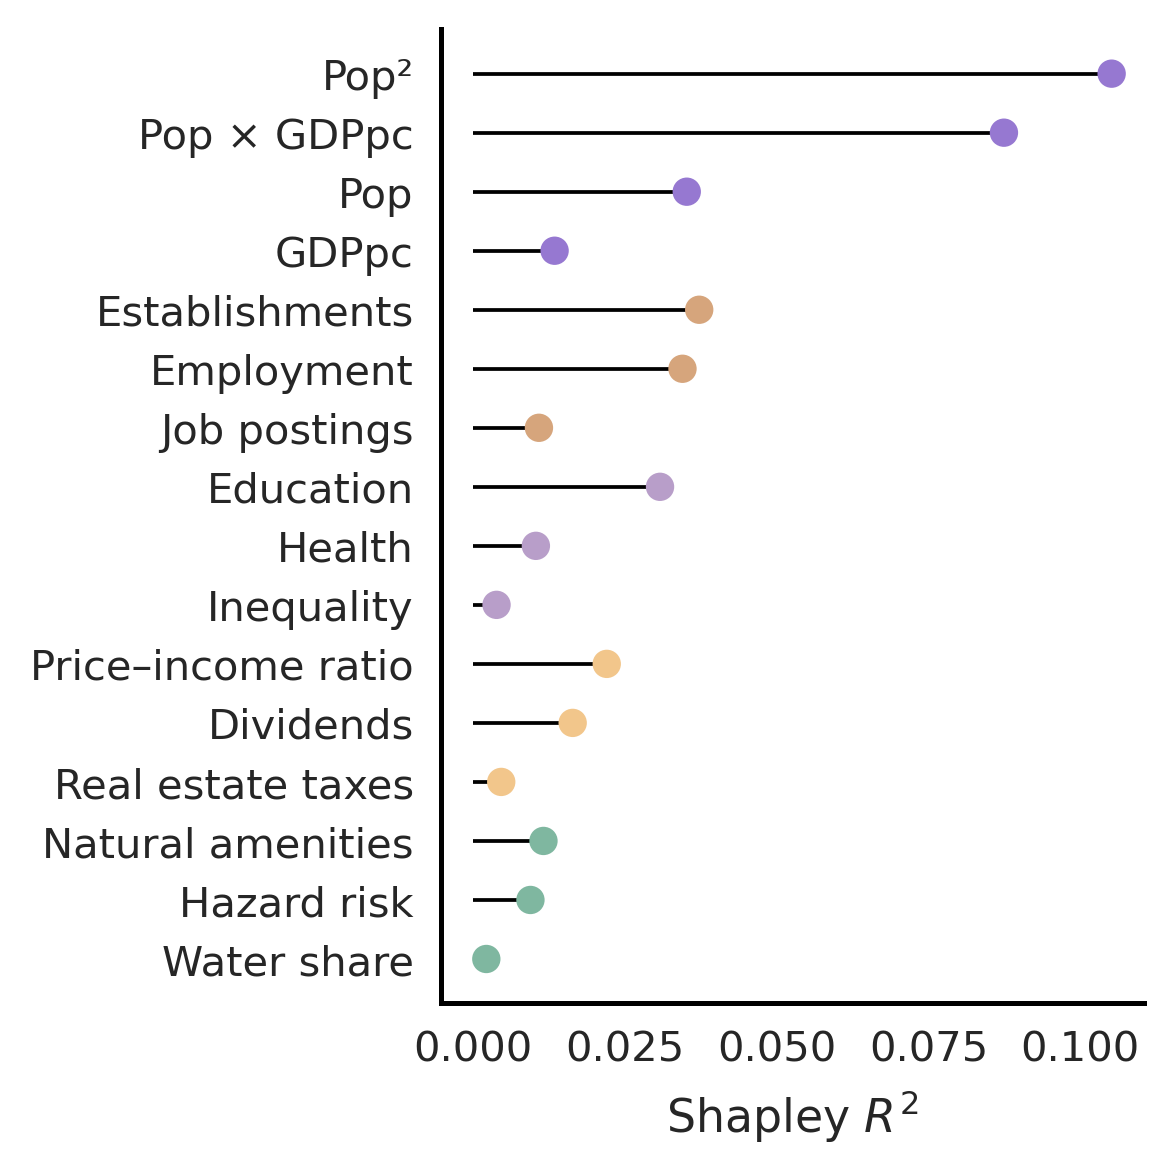

In [156]:
groups = shapley_var_df["Group"].unique()

fig, ax = plt.subplots(figsize=(4, 4))

# stems
ax.hlines(
    y=shapley_var_df["y"],
    xmin=0,
    xmax=shapley_var_df["Shapley R2"],
    color="black",
    linewidth=0.9
)

# heads (colored by group)
ax.scatter(
    shapley_var_df["Shapley R2"],
    shapley_var_df["y"],
    c=shapley_var_df["Group"].map(group_colors),
    s=36,
    zorder=3
)

# axis formatting
ax.set_xlabel("Shapley $R^2$")
ax.set_yticks(shapley_var_df["y"])
ax.set_yticklabels(shapley_var_df["label"])

# ax.set_xscale("log")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(False)


plt.tight_layout()
plt.show()


In [157]:
import re

records = []
rows = df_results.reset_index()

for i in range(len(rows) - 1):

    var = rows.loc[i, "index"]
    coef_cell = rows.loc[i, "Model 5 I"]
    se_cell   = rows.loc[i + 1, "Model 5 I"]

    # coefficient rows are strings; SE rows start with "("
    if not isinstance(coef_cell, str):
        continue
    if not isinstance(se_cell, str) or not se_cell.startswith("("):
        continue
    if var in ["Intercept", "R-squared", "R-squared Adj.", "BIC", "N"]:
        continue

    coef = float(re.sub(r"[^\d\.\-]", "", coef_cell))
    se   = float(re.sub(r"[^\d\.\-]", "", se_cell))

    sig = re.sub(r"[\d\.\-\s]", "", coef_cell)   # keeps *, **, *** or +

    records.append({
        "Variable": var,
        "coef": coef,
        "se": se,
        "sig": sig
    })



coef_df = pd.DataFrame(records)

coef_df["ci_low"] = coef_df["coef"] - 1.96 * coef_df["se"]
coef_df["ci_high"] = coef_df["coef"] + 1.96 * coef_df["se"]

var_to_group = {
    "log_pop_centered": "Agglomeration size &\n economic power",
    "log_gdp_centered": "Agglomeration size &\n economic power",
    "log_pop_centered:log_gdp_centered": "Agglomeration size &\n economic power",
    "I(log_pop_centered ** 2)": "Agglomeration size &\n economic power",

    "log_taxes_med_centered": "Individual wealth",
    "log_dividends_centered": "Individual wealth",
    "income_price_ratio2023_centered": "Individual wealth",

    "log_est_100k_centered": "Labour market\n structure",
    "log_emp_100k_centered": "Labour market\n structure",
    "log_n_postings_centered": "Labour market\n structure",

    "education_centered": "Human capital",
    "health_centered": "Human capital",
    "inequality_centered": "Human capital",

    "nat_amenity_centered": "Geography",
    "water_perc_centered": "Geography",
    "risk_centered": "Geography"
}

coef_df["Group"] = coef_df["Variable"].map(var_to_group)
coef_df = coef_df.dropna(subset=["Group"])



In [158]:
var_name_map = {
    "log_pop_centered:log_gdp_centered": "Pop × GDPpc",
    "I(log_pop_centered ** 2)": "Pop²",
    "log_gdp_centered": "GDPpc",
    "log_pop_centered": "Pop",

    "nat_amenity_centered": "Natural amenities",
    "risk_centered": "Hazard risk",
    "log_pop_density_centered": "Pop density",
    "water_perc_centered": "Water share",

    "education_centered": "Education",
    "inequality_centered": "Inequality",
    "health_centered": "Health",

    "income_price_ratio2023_centered": "Price-income ratio",
    "log_taxes_med_centered": "Real estate taxes",
    "log_dividends_centered": "Dividends",

    "log_est_100k_centered": "Establishments",
    "log_emp_100k_centered": "Employment",
    "log_n_postings_centered": "Job postings"
}

coef_df["Variable_label"] = coef_df["Variable"].map(var_name_map)

variable_order = shapley_var_df['Variable']

coef_df["Variable"] = pd.Categorical(
    coef_df["Variable"],
    categories=variable_order,
    ordered=True
)

coef_df = coef_df.sort_values("Variable").reset_index(drop=True)
coef_df["y"] = range(len(coef_df))

In [159]:
group_colors = {
    "Agglomeration size &\n economic power": "#9678D1",  # muted violet
    "Geography": "#7FB7A0",                              # sage green
    "Labour market\n structure": "#D6A57C",             # warm sand
    "Human capital": "#B89EC9",                          # lavender
    "Individual wealth": "#F2C68B"                       # soft amber
}



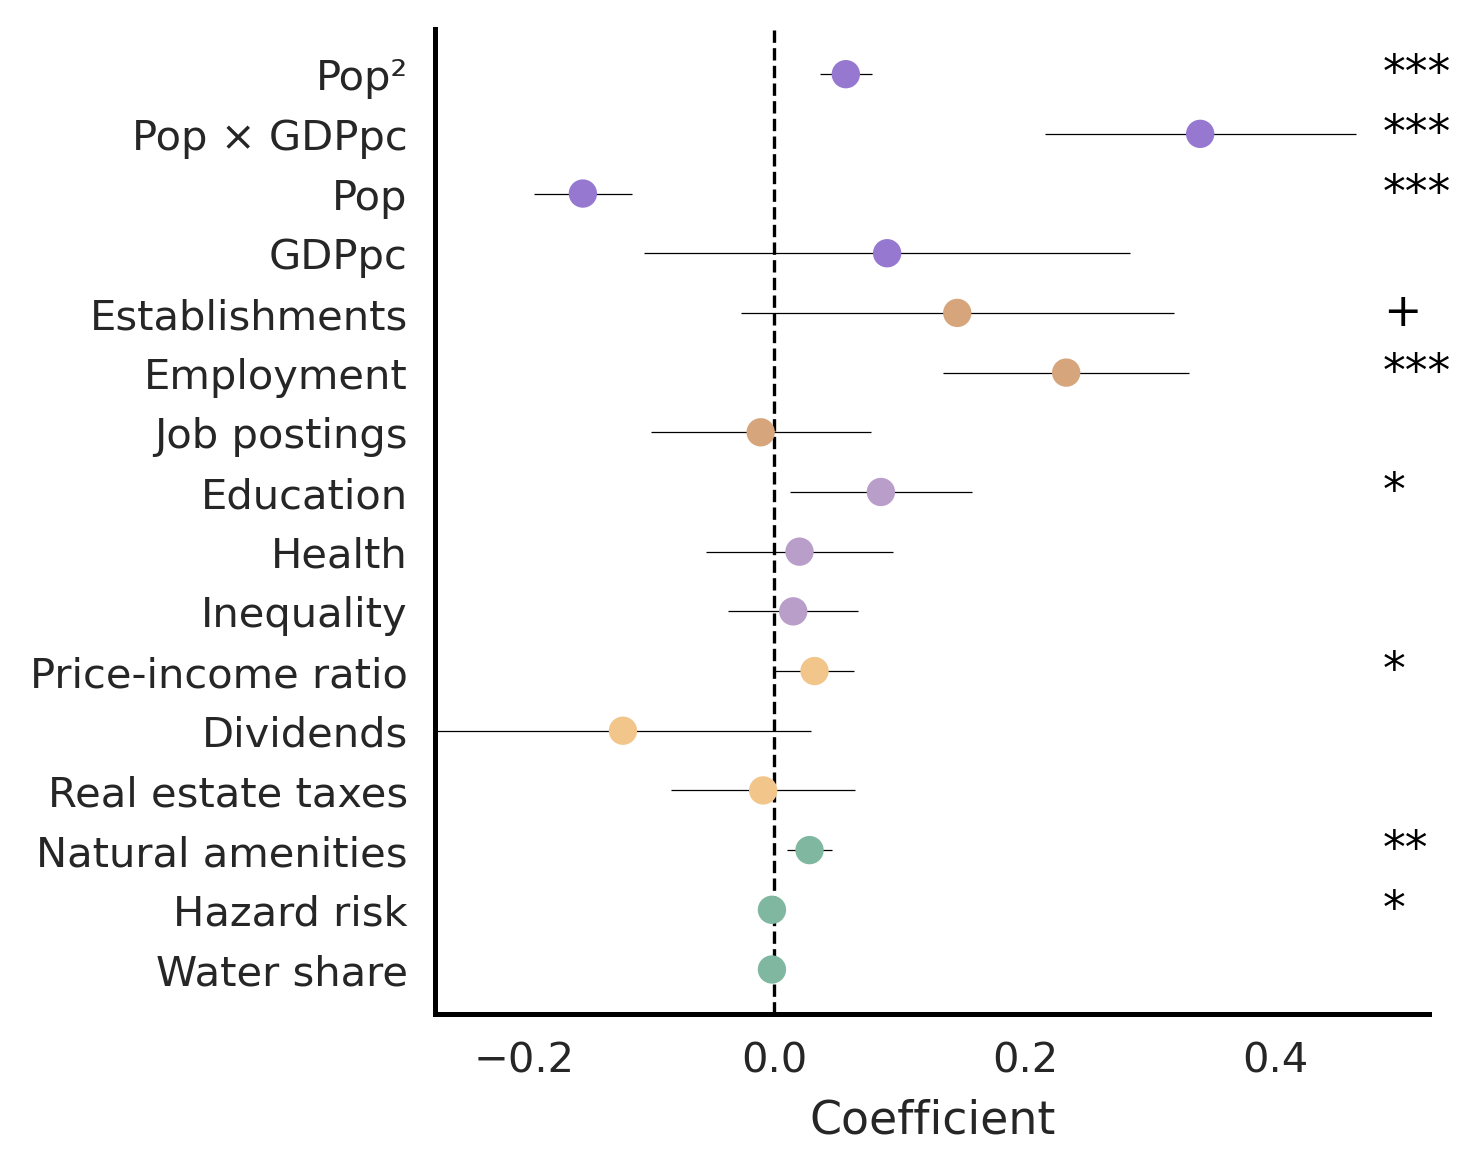

In [160]:
fig, ax = plt.subplots(figsize=(5, 4))

# confidence intervals
ax.hlines(
    y=coef_df["y"],
    xmin=coef_df["ci_low"],
    xmax=coef_df["ci_high"],
    color="black",
    linewidth=0.3
)

# point estimates
ax.scatter(
    coef_df["coef"],
    coef_df["y"],
    c=coef_df["Group"].map(group_colors),
    s=36,
    zorder=3
)

# zero line
ax.axvline(0, color="black", linestyle="--", linewidth=0.8)

ax.set_yticks(coef_df["y"])
ax.set_yticklabels(coef_df["Variable_label"])

ax.set_xlabel("Coefficient")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(False)

sig_x = coef_df["ci_high"].max() + 0.03 * (
    coef_df["ci_high"].max() - coef_df["ci_low"].min()
)

for _, row in coef_df.iterrows():
    if row["sig"] != "":
        ax.text(
            sig_x,
            row["y"],
            row["sig"],
            fontsize=11,
            va="center",
            ha="left",
            color="black",
            zorder=4
        )

ax.set_xlim(
    coef_df["ci_low"].min(),
    sig_x + 0.05 * (coef_df["ci_high"].max() - coef_df["ci_low"].min())
)


plt.tight_layout()
plt.show()


In [161]:
df.to_csv('../data_generated/df_merged_cbsa.csv')